# 📊 EDA THÔ THEO NGUỒN (RAW-FIRST, SINGLE-SOURCE) — ITVIEC
## Phân tích đơn biến chuyên sâu trên dữ liệu thô nguyên bản `data/itviec/`

> **Dự án:** VN-IT-Job-Mining — **Thành viên phụ trách:** Nhóm EDA Intelligence (Thành viên 2, theo `01_huong_dan_eda_nhom_3_nguoi.md`)
> **Phạm vi file này:** EDA **cho riêng nguồn ITViec ở tầng Raw As-Is**. Chưa ghép schema chung, chưa làm sạch, chưa biến đổi dữ liệu thô — mọi dẫn xuất phân tích chỉ tồn tại trong bộ nhớ notebook (`feat`), không ghi ngược về `data/`.
> **Tiêu chuẩn:** CRISP-DM Phase 2 (Data Understanding) + 5 trụ cột chất lượng dữ liệu + bộ 7 biểu đồ bắt buộc (DPI 300) tại `reports/figures/itviec/`.

### Điểm khác biệt của ITViec so với các nguồn khác trong nhóm
ITViec lưu **ba tầng thông tin chồng lấn** cho cùng một sự kiện nghiệp vụ:

| Tầng | Trường | Bản chất |
|:---|:---|:---|
| **L1 — UI text** | `salary_display_text`, `work_location`, `work_model`, `posted_at_raw` | Chuỗi hiển thị trên trang, lẫn nhãn marketing và nhiễu DOM |
| **L2 — dataLayer** | `salary_range_datalayer` | Dữ liệu analytics của trang, đôi khi *mở* hơn UI |
| **L3 — schema.org JSON-LD** | `job_posting_jsonld` (14 khóa: `baseSalary`, `jobLocation`, `experienceRequirements`, `datePosted`, `validThrough`…) | Cấu trúc chuẩn nhất nhưng **trống 35 bản ghi** |

Chính cấu trúc 3 tầng này khiến EDA nguồn của ITViec phải trả lời thêm một câu hỏi mà các nguồn khác không có: **nếu ba tầng mâu thuẫn, tầng nào được tin?**

### Câu hỏi định hướng của notebook này
| Trụ cột | Câu hỏi chẩn đoán | Bước trả lời |
|:---|:---|:---|
| **1. Độ hoàn thiện** | Trường nào khuyết? Khuyết do *nhà tuyển dụng không khai* hay do *crawler/phân trang khác phiên bản*? | Bước 2 |
| **2. Hợp lệ & kiểu dữ liệu** | Lương 3 tầng có nhất quán? `monthsOfExperience` trộn `int` và chuỗi; `rating` là chuỗi; `posted_at_raw` lẫn newline | Bước 3 |
| **3. Duy nhất** | Trùng `job_id`/URL, `canonical_hash` repost, hai thế hệ schema băm khác nhau | Bước 4 |
| **4. Phân phối & ngoại lai** | Skewness/Kurtosis lương **tách riêng VND và USD (hai bảng)**, số bullet JD, tuổi tin, ngoại lai IQR & Z | Bước 5 |
| **5. Lệch & mất cân bằng** | Work model, tỉnh thành, chuyên môn, quốc gia nhà tuyển dụng, độ thưa thẻ kỹ năng | Bước 6–8 |

### Phạm vi: EDA NÀY KHÔNG LÀM TIỀN XỬ LÝ
Theo `01_huong_dan_eda_nhom_3_nguoi.md`, Pre-processing Pipeline (Integration, Imputation, Normalization,
Scaling) nằm **SAU** bước EDA và chỉ chạy **sau khi đã tích hợp đủ 8 nguồn**. Vì vậy notebook này:

- chỉ **đọc và đo** `data/itviec/`, không ghi đè, không sửa, không điền khuyết, không chuẩn hoá dữ liệu thô;
- mọi cột dẫn xuất (`feat`, `SAL_BY_CUR`, `LAD`, `SEN`, `CORR`, `REL`) là **frame đo lường trong bộ nhớ**;
- kết thúc bằng khối 🔒 **kiểm chứng bất biến** (hash thư mục raw + hash nội dung `df`/`df_top`) để chứng minh
  bằng số rằng không một phép tiền xử lý nào đã đụng tới tầng Raw As-Is;
- đầu ra duy nhất cho bước sau là **Kế hoạch Tiền Xử Lý** ở mục 7.1, kèm số liệu biện minh.

### Quy ước đơn vị lương: HAI BẢNG, KHÔNG QUY ĐỔI
Tin đăng ITViec khai lương bằng **hai đồng tiền khác nhau**. `VND` và `USD` được xử lý như sau:

| Quy ước | Chi tiết |
|:---|:---|
| **Bảng A — VND** | đơn vị `Triệu VND/tháng`; `3.000.000` và `3tr` là cùng một tiền tệ, chỉ khác **bậc** nội tệ nên được quy về triệu |
| **Bảng B — USD** | đơn vị `USD/tháng`; giữ nguyên con số nhà tuyển dụng ghi, **không nhân tỷ giá** |
| **Không bao giờ gộp** | không có chỉ tiêu nào (skew, Tukey, Box–Cox, ρ, kiểm định hạng) được tính trên mẫu trộn hai tiền tệ |
| `MIN_N_DIST = 30` | bảng có mẫu dưới ngưỡng chỉ được **mô tả/liệt kê**, không ước lượng phân phối |
| Tỷ giá | là quyết định của tầng **Integration** (kèm ngày chốt và nguồn tỷ giá), không phải của EDA |

**Đo trên chính kho raw (mục 3.3b):** trong 692 tin chỉ có **201 tin** định lượng được lương, và 201 tin này tách
thành **28 tin VND** + **173 tin USD (86.1%)** — tức bảng USD mới là bảng chính của ITViec, **ngược hẳn** với
CareerViet (nơi VND chiếm đa số). Đó là lý do một cột lương “chung” cho cả 8 nguồn buộc phải kèm cột `currency`.

### Cách chạy
`Kernel → Restart & Run All` (kernel `python3`, thư mục dự án). Notebook **hoàn toàn offline**: chỉ đọc `data/itviec/**/*.json` và ghi ảnh vào `reports/figures/itviec/`.

In [1]:
import os, sys, json, re, math, warnings, hashlib
from pathlib import Path
from collections import Counter

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "run.py").is_file():
    if (PROJECT_ROOT.parent / "run.py").is_file():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError("Không tìm thấy run.py — hãy mở notebook từ thư mục dự án VN-IT-Job-Mining.")
os.chdir(PROJECT_ROOT)

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from IPython.display import display

SOURCE, SOURCE_LABEL = "itviec", "ITViec"
DATA_DIR = PROJECT_ROOT / "data" / SOURCE
FIG_DIR = PROJECT_ROOT / "reports" / "figures" / SOURCE
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Lương được GIỮ NGUYÊN đơn vị mà tin đăng khai báo. VND và USD là HAI BẢNG riêng:
# notebook này không nhân tỷ giá để gộp thành một cột số (quy đổi là quyết định của tầng Integration).
VND_UNIT, USD_UNIT = "Triệu VND/tháng", "USD/tháng"
CUR_GROUPS = (("vnd", "VND", VND_UNIT), ("usd", "USD", USD_UNIT))
SAL_SANITY = {"vnd": (0.5, 1_000.0), "usd": (50.0, 20_000.0)}
MIN_N_DIST = 30
CUR_LABEL = {t: lbl for t, lbl, _ in CUR_GROUPS}
CUR_UNIT = {t: u for t, _, u in CUR_GROUPS}
PALETTE = ["#1d3557", "#2a9d8f", "#e76f51", "#e9c46a", "#457b9d"]
C_MAIN, C_OK, C_WARN, C_MUTE = "#1d3557", "#2a9d8f", "#e76f51", "#64748b"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#cbd5e1", "axes.linewidth": 0.9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e2e8f0", "grid.linestyle": "--", "grid.linewidth": 0.7,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5, "ytick.labelsize": 9.5, "legend.fontsize": 9, "legend.frameon": False,
    "font.family": "DejaVu Sans", "axes.unicode_minus": False,
})

FIG_NOTE = ""  # dòng ghi chú nguồn dưới mỗi biểu đồ, gán sau khi nạp dữ liệu
SAVED_FIGS = []  # danh sách PNG do CHÍNH notebook này ghi ra (để phân biệt với tệp cũ còn sót lại)
FIG_LABELS = {}  # png -> tập nhãn thu từ HÌNH THẬT LÚC VẼ, dùng cho bước kiểm bao phủ trường ở Bước 7


def show(obj, limit=30):
    """In bảng thân thiện cả trong Jupyter lẫn khi chạy như script."""
    if isinstance(obj, pd.DataFrame) and len(obj) > limit:
        obj = obj.head(limit)
    with pd.option_context("display.max_columns", None, "display.width", 260, "display.max_colwidth", 55):
        display(obj)


def _fit_fig_text(fig, txt, left_frac=0.012):
    """Đo bề ngang thực tế của một text đã đặt trong figure và hạ cỡ chữ nếu nó dài quá khổ.

    Dùng phép đo của renderer (không cần vẽ lại) nên tiêu đề tự co lại thay vì bị cắt xén khi lưu PNG.
    """
    try:
        width_px = fig.get_size_inches()[0] * fig.dpi
        avail_px = width_px * (1 - left_frac - 0.012)          # chỗ còn lại tính từ vị trí đặt chữ
        drawn_px = txt.get_window_extent(fig.canvas.get_renderer()).width
        if drawn_px > avail_px:
            txt.set_fontsize(max(8.0, txt.get_fontsize() * avail_px / drawn_px))
    except Exception:
        pass                                                    # backend không có renderer -> giữ nguyên cỡ gốc


def _harvest_labels(fig):
    """Thu MỌI chữ in trên một hình: nhãn trục, tên trục, chú thích legend, ghi chú và tiêu đề.

    Nguồn bằng chứng là đối tượng Text của chính figure sắp lưu ra PNG, không phải một danh sách
    gõ tay, nên cell kiểm bao phủ ở Bước 7 không thể báo 'có biểu đồ' cho một trường chưa thực sự lên hình.
    """
    labs = set()

    def _add(s):
        s = str(s).strip()
        if s:
            labs.add(s)

    for ax in fig.axes:
        for t in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
            _add(t.get_text())
        _add(ax.xaxis.get_label().get_text())
        _add(ax.yaxis.get_label().get_text())
        _add(ax.get_title())
        lg = ax.get_legend()
        if lg is not None:
            for t in lg.get_texts():
                _add(t.get_text())
        for ch in ax.get_children():
            if type(ch).__name__ in ("Annotation", "Text"):
                _add(ch.get_text())
    st = fig.get_suptitle()          # get_suptitle() trả về CHUỖI (khác fig.suptitle() trả về Text)
    _add(st.get_text() if hasattr(st, "get_text") else st)
    for t in fig.texts:
        _add(t.get_text())
    return labs


def finalize(fig, title, subtitle=None, save_name=None, note=None):
    """Áp chuẩn trình bày: tiêu đề kết luận + phụ đề n= + nguồn; lưu PNG DPI 300."""
    fig.tight_layout(rect=[0, 0.045, 1, 0.93 if subtitle else 0.955])
    ttl = fig.suptitle(title, x=0.012, ha="left", fontsize=14.5, fontweight="bold", color=C_MAIN,
                       y=0.995 if subtitle else 0.98)
    _fit_fig_text(fig, ttl)
    if subtitle:
        sub = fig.text(0.012, 0.955, subtitle, ha="left", fontsize=10, color=C_MUTE)
        _fit_fig_text(fig, sub)
    nte = fig.text(0.012, 0.015, note or FIG_NOTE, ha="left", fontsize=8.5, color=C_MUTE)
    _fit_fig_text(fig, nte)
    if save_name:
        FIG_LABELS[save_name] = _harvest_labels(fig)
        path = FIG_DIR / save_name
        fig.savefig(path, dpi=300)
        SAVED_FIGS.append(save_name)
        print(f"🖼️  Đã lưu {path.relative_to(PROJECT_ROOT)} (DPI 300)")
    plt.show()
    plt.close(fig)


def label_bars(ax, values, fmt="{:,.0f}", pad_ratio=0.012, fontsize=9):
    """Gắn nhãn giá trị (%) lên đòn ngang đã vẽ sẵn."""
    span = max(values) if len(values) else 1
    for i, v in enumerate(values):
        ax.text(v + span * pad_ratio, i, fmt.format(v), va="center", ha="left",
                fontsize=fontsize, color="#334155")


def entropy_norm(counts):
    """Độ đa dạng chuẩn hoá 0–1 (1 = phân bố đều, 0 = dồn 1 nhãn)."""
    p = np.asarray([c for c in counts if c > 0], dtype=float)
    if p.size <= 1:
        return 0.0
    return float(stats.entropy(p / p.sum()) / np.log(p.size))


def gini(values):
    """Hệ số Gini trên tần suất (0 = phân bố đều, →1 = dồn vài nhãn)."""
    x = np.sort(np.asarray(values, dtype=float))
    if x.size <= 1 or x.sum() == 0:
        return 0.0
    return float((2 * np.sum((np.arange(1, x.size + 1)) * x)) / (x.size * x.sum()) - (x.size + 1) / x.size)


print(f"✅ Môi trường sẵn sàng — nguồn: {SOURCE_LABEL} | dữ liệu: {DATA_DIR.relative_to(PROJECT_ROOT)}")

✅ Môi trường sẵn sàng — nguồn: ITViec | dữ liệu: data\itviec


## Bước 1 — Nạp Raw Envelope & khảo sát cấu trúc nguyên bản (Zero Information Loss)

Mỗi tin ITViec là một **raw envelope** 2 tầng, lưu tại `data/itviec/<YYYY-MM-DD>/<slug>_v<N>.json`:

```
├── metadata    : job_id, source, source_url, scraped_at, scraper_version, version,
│                 content_hash, http_status
│                 + (thế hệ mới) canonical_hash, field_hashes{14 trường}
│                 + (thế hệ cũ)  content_hash_algo, hash_container, hash_jsonld_fields[10]
└── raw_payload : 14 trường thô — title, company_name, company_url,
                  salary_display_text(L1), salary_range_datalayer(L2), skill_tags[list],
                  sections{dict 3–4 mục}, job_posting_jsonld{dict 14 khóa — L3},
                  work_location, work_model, posted_at_raw, specialization[list],
                  industries[list], company_details{dict 8 khóa}
```

Notebook **giữ nguyên khối `sections` là dict** (không nổ thành cột) để đếm số mục/số bullet theo từng
tiêu đề mục, và **nổ toàn bộ `job_posting_jsonld` + `company_details`** thành cột để phân tích đơn biến.

In [2]:
TOP_KEYS = ["title", "company_name", "company_url", "salary_display_text", "skill_tags",
            "salary_range_datalayer", "sections", "job_posting_jsonld", "work_location",
            "work_model", "posted_at_raw", "specialization", "industries", "company_details"]


def load_envelopes(source: str, data_dir: Path):
    """Nạp toàn bộ raw envelope, giữ nguyên 100% trường thô (không ép kiểu, không chuẩn hoá)."""
    files = [p for p in sorted(data_dir.rglob("*.json"))
             if not any(k in str(p) for k in ("url_ledger", "manifest", "session"))]
    payloads, metas, prov, tops, sections = [], [], [], [], []
    bad_files = []
    for fp in files:
        try:
            with open(fp, "r", encoding="utf-8") as f:
                env = json.load(f)
        except Exception as exc:                                  # kiểm tra cả file hỏng/thiếu JSON
            bad_files.append((fp.name, repr(exc)))
            continue
        payload = env.get("raw_payload") or {}
        meta = env.get("metadata") or {}
        part = next((p for p in fp.relative_to(data_dir).parts[:-1]), "khong_ro_phan_vung")
        tops.append({k: payload.get(k) for k in TOP_KEYS})
        sections.append(payload.get("sections") or {})
        payloads.append({k: v for k, v in payload.items() if k != "sections"})
        metas.append(meta)
        prov.append({
            "_file": fp.name, "_partition": part,
            "_bytes": fp.stat().st_size,
            "_has_payload": bool(payload), "_has_metadata": bool(meta),
            "_top_keys": "|".join(sorted(env.keys())),
        })
    prov = pd.DataFrame(prov)
    df = pd.json_normalize(payloads).join(prov)
    df["sections"] = sections                                       # giữ nguyên dict mục → bullet
    df_top = pd.DataFrame(tops, index=df.index)                    # 14 cột thô chưa nổ cấu trúc
    meta_df = pd.json_normalize(metas).add_prefix("m_")
    meta_df.index = df.index
    return df, df_top, meta_df, files, bad_files


df, df_top, df_meta, FILES, BAD_FILES = load_envelopes(SOURCE, DATA_DIR)
raw_cols = list(df_top.columns)


def _raw_fingerprint(dir_: Path):
    """Chữ ký tầng Raw As-Is trên đĩa: (số file, tổng byte, hash tên + kích thước + mtime)."""
    ps = sorted(p for p in dir_.rglob("*") if p.is_file())
    body = "\x1f".join(f"{p.relative_to(dir_)}:{p.stat().st_size}:{p.stat().st_mtime_ns}" for p in ps)
    return {"n": len(ps), "bytes": sum(p.stat().st_size for p in ps),
            "sha": hashlib.sha256(body.encode("utf-8")).hexdigest()[:16]}


def _frame_fingerprint(frame):
    """Chữ ký nội dung một DataFrame trong bộ nhớ (dùng để chứng minh dữ liệu thô không bị sửa)."""
    rows = frame.astype(object).where(frame.notna(), "\u2205").astype(str)
    body = "\n".join(rows.agg(lambda r: "\x1f".join(r), axis=1).tolist())
    return hashlib.sha256(body.encode("utf-8")).hexdigest()[:16]


RAW_DISK_0 = _raw_fingerprint(DATA_DIR)
RAW_SHAPE_0, RAW_COLUMNS_0 = df.shape, list(df.columns)
RAW_FRAME_0, DFTOP_FRAME_0 = _frame_fingerprint(df), _frame_fingerprint(df_top)
print("─" * 78)
print("🔒 HIỆN TRẠNG RAW LÚC NẠP (móc chống tiền xử lý nhầm trong EDA — xem bước 7)")
print(f"   Trên đĩa        : {RAW_DISK_0['n']} file · {RAW_DISK_0['bytes']:,} byte · sha256[:16]={RAW_DISK_0['sha']}")
print(f"   `df` (nổ cấu trúc): {RAW_SHAPE_0[0]} dòng × {RAW_SHAPE_0[1]} cột · sha256[:16]={RAW_FRAME_0}")
print(f"   `df_top` (14 cột thô): {df_top.shape[0]} × {df_top.shape[1]} · sha256[:16]={DFTOP_FRAME_0}")
print("─" * 78)

print("=" * 78)
print(f"📦 RAW ENVELOPE — {SOURCE_LABEL}")
print(f"   Số file JSON nạp vào bộ nhớ : {len(FILES)} (lỗi parse: {len(BAD_FILES)})")
print(f"   Số bản ghi (dòng)           : {len(df)}")
print(f"   Số cột thô (raw_payload)    : {len(raw_cols)}  → nổ cấu trúc thành {df.shape[1] - 6} cột phân tích")
print(f"   Số cột metadata CDC         : {df_meta.shape[1]}")
print(f"   Phân vùng dt                : {df['_partition'].value_counts().to_dict()}")
if BAD_FILES:
    print("   ⚠️ File lỗi:", BAD_FILES[:5])

_scraped = pd.to_datetime(df_meta["m_scraped_at"], errors="coerce", utc=True)
FIG_NOTE = (f"Nguồn: {len(df)} raw envelope {SOURCE_LABEL} "
            f"({', '.join(df['_partition'].value_counts().index.tolist())}) — "
            f"scraped_at {_scraped.min():%d/%m/%Y} → {_scraped.max():%d/%m/%Y} · "
            f"phân tích Raw As-Is, không biến đổi dữ liệu thô")

show(df.drop(columns=["_bytes", "_has_payload", "_has_metadata", "_top_keys", "sections"]).head(4))

──────────────────────────────────────────────────────────────────────────────
🔒 HIỆN TRẠNG RAW LÚC NẠP (móc chống tiền xử lý nhầm trong EDA — xem bước 7)
   Trên đĩa        : 692 file · 10,770,346 byte · sha256[:16]=375ca8e3530fa57c
   `df` (nổ cấu trúc): 692 dòng × 55 cột · sha256[:16]=60efc3cacac21080
   `df_top` (14 cột thô): 692 × 14 · sha256[:16]=0a46fbc7f6cb09ec
──────────────────────────────────────────────────────────────────────────────
📦 RAW ENVELOPE — ITViec
   Số file JSON nạp vào bộ nhớ : 692 (lỗi parse: 0)
   Số bản ghi (dòng)           : 692
   Số cột thô (raw_payload)    : 14  → nổ cấu trúc thành 49 cột phân tích
   Số cột metadata CDC         : 26
   Phân vùng dt                : {'2026-10-20': 670, '2026-10-19': 22}


,title,company_name,company_url,salary_display_text,skill_tags,salary_range_datalayer,job_posting_jsonld.@context,job_posting_jsonld.@type,job_posting_jsonld.industry,job_posting_jsonld.title,job_posting_jsonld.datePosted,job_posting_jsonld.validThrough,job_posting_jsonld.skills,job_posting_jsonld.description,job_posting_jsonld.potentialAction.@type,job_posting_jsonld.potentialAction.target,job_posting_jsonld.hiringOrganization.@type,job_posting_jsonld.hiringOrganization.logo,job_posting_jsonld.hiringOrganization.name,job_posting_jsonld.hiringOrganization.description,job_posting_jsonld.employmentType,job_posting_jsonld.jobLocation,job_posting_jsonld.baseSalary.@type,job_posting_jsonld.baseSalary.currency,job_posting_jsonld.baseSalary.value.@type,job_posting_jsonld.baseSalary.value.minValue,job_posting_jsonld.baseSalary.value.maxValue,job_posting_jsonld.baseSalary.value.unitText,job_posting_jsonld.baseSalary.value.value,job_posting_jsonld.directApply,job_posting_jsonld.jobBenefits,job_posting_jsonld.experienceRequirements.@type,job_posting_jsonld.experienceRequirements.monthsOfExperience,job_posting_jsonld.experienceRequirements,job_posting_jsonld,work_location,work_model,posted_at_raw,specialization,industries,company_details.rating,company_details.slogan,company_details.Mô hình công ty,company_details.Lĩnh vực công ty,company_details.Quy mô công ty,company_details.Quốc gia,company_details.Thời gian làm việc,company_details.Làm việc ngoài giờ,_file,_partition
0,AI Engineer (Remote),Alpha Bravo Development,/nha-tuyen-dung/alpha-bravo-development,Đăng nhập để xem mức lương,"[AI, Python]",NaN,http://schema.org,JobPosting,Information Technology,AI Engineer Remote,2026-09-29,2026-11-03,"AI, Python","Top 3 Reasons To Join Us\r\nA transparent, supporti...",ApplyAction,https://itviec.com/job/ai-engineer-remote-alpha-bra...,Organization,https://itviec.com/rails/active_storage/representat...,Alpha Bravo Development,Alpha Bravo Development is a full-service app and s...,FULL_TIME,"[{'@type': 'Place', 'address': {'@type': 'PostalAdd...",MonetaryAmount,USD,QuantitativeValue,1000.0,1300.0,MONTH,"1,000 - 1,300 USD",TRUE,"<p>Salary: Up to $1,300 net/month, depending on exp...",OccupationalExperienceRequirements,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ai-engineer-remote-alpha-bravo-development-4157_v1....,2026-10-19
1,"AI Operations Manager (from 5yoe, Excellent English)",YUM! Digital & Technology,/nha-tuyen-dung/yum-digital-technology,Đăng nhập để xem mức lương,"[MLOps, Python, DevOps, English, Leadership, AI]",NaN,http://schema.org,JobPosting,Information Technology,"AI Operations Manager from 5yoe, Excellent English",2026-09-30,2026-11-04,"MLOps, Python, DevOps, English, Leadership, AI",Top 3 Reasons To Join Us\r\n18 Annual Leave + 5 Rec...,ApplyAction,https://itviec.com/job/ai-operations-manager-from-5...,Organization,https://itviec.com/rails/active_storage/representat...,YUM! Digital & Technology,YUM! Digital & Technology,FULL_TIME,"[{'@type': 'Place', 'address': {'@type': 'PostalAdd...",MonetaryAmount,USD,QuantitativeValue,3400.0,4500.0,MONTH,"3,400 - 4,500 USD",TRUE,<ul><li>100% salary during the probation period</li...,OccupationalExperienceRequirements,61.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ai-operations-manager-from-5yoe-excellent-english-y...,2026-10-19
2,Business Analyst Intern (Company Secretariat),Phu Hung Securities (PHS),/nha-tuyen-dung/phu-hung-securities-phs,Đăng nhập để xem mức lương,"[Business Analysis, Python, Tester, AI, Design, Use...",NaN,http://schema.org,JobPosting,Information Technology,Business Analyst Intern Company Secretariat,2026-10-14,2026-11-18,"Business Analysis, Python, Tester, AI, Design, User...","Top 3 Reasons To Join Us\r\nCompetitive salary, bon...",ApplyAction,https://itviec.com/job/business-analyst-intern-comp...,Organization,https://itviec.com/rails/active_storage/representat...,Phu Hung Securities (PHS),Thịnh vượng trường tồn - Vươn tầm quốc tế,FULL_

In [3]:
print("── 1.1 DANH SÁCH 100% CỘT THÔ (raw_payload) + KIỂU DỮ LIỆU THỰC TẾ ──")
struct_rows = []
for c in raw_cols:
    kinds = Counter(type(v).__name__ for v in df_top[c])
    struct_rows.append({
        "Cột thô": c,
        "dtype (pandas)": str(df_top[c].dtype),
        "Kiểu Python thực tế": ", ".join(f"{k}×{v}" for k, v in kinds.most_common()),
        "Đầy đủ (%)": round(df_top[c].notna().mean() * 100, 1),
        "Tầng thông tin": ("L1 UI" if c in ("salary_display_text", "work_location", "work_model", "posted_at_raw")
                           else "L2 dataLayer" if c == "salary_range_datalayer"
                           else "L3 JSON-LD" if c == "job_posting_jsonld" else "DOM block"),
        "Ví dụ giá trị": str(df_top[c].dropna().iloc[0])[:58] if df_top[c].notna().any() else "",
    })
show(pd.DataFrame(struct_rows), limit=40)

jl_cols = [c for c in df.columns if c.startswith("job_posting_jsonld.")]
cd_cols = [c for c in df.columns if c.startswith("company_details.")]
print(f"\n🧱 Nổ cấu trúc: job_posting_jsonld → {len(jl_cols)} cột; company_details → {len(cd_cols)} cột.")
print("   Khóa JSON-LD có mặt ở mọi bản ghi:", [c.split(".")[-1] for c in jl_cols
                                                if df[c].notna().mean() == 1.0][:8], "…")

── 1.1 DANH SÁCH 100% CỘT THÔ (raw_payload) + KIỂU DỮ LIỆU THỰC TẾ ──

🧱 Nổ cấu trúc: job_posting_jsonld → 28 cột; company_details → 8 cột.
   Khóa JSON-LD có mặt ở mọi bản ghi: [] …


,Cột thô,dtype (pandas),Kiểu Python thực tế,Đầy đủ (%),Tầng thông tin,Ví dụ giá trị
0,title,str,"str×688, float×4",99.4,DOM block,AI Engineer (Remote)
1,company_name,str,"str×684, float×8",98.8,DOM block,Alpha Bravo Development
2,company_url,str,"str×684, float×8",98.8,DOM block,/nha-tuyen-dung/alpha-bravo-development
3,salary_display_text,str,"str×682, float×10",98.6,L1 UI,Đăng nhập để xem mức lương
4,skill_tags,object,list×692,100.0,DOM block,"['AI, Python']"
5,salary_range_datalayer,str,"str×665, float×27",96.1,L2 dataLayer,"800 - 1,800 USD"
6,sections,object,dict×692,100.0,DOM block,"{'3 Lý do để gia nhập công ty': ['A transparent, su..."
7,job_posting_jsonld,object,"dict×657, NoneType×35",94.9,L3 JSON-LD,"{'@context': 'http://schema.org', '@type': 'JobPost..."
8,work_location,str,"str×666, float×26",96.2,L1 UI,"19 Tan Canh, Tân Sơn Hòa, TP Hồ Chí Minh"
9,work_model,str,"str×654, float×38",94.5,L1 UI,Linh hoạt


### 1.2 Provenance, độ tươi dữ liệu và **hai thế hệ schema băm**

`metadata` là tầng nhân tố của pipeline. Với ITViec có hai tín hiệu phải kiểm tra ngay:

1. **`http_status`** — mã `410 Gone` nghĩa là tin đã bị gỡ khỏi sàn *ngay lúc crawler tới*: phần thân
   (JSON-LD, `posted_at_raw`) không còn, chỉ sót lại tiêu đề/công ty/lương UI. Đây là khuyết thiếu **hệ thống**,
   không phải ngẫu nhiên.
2. **Hai thế hệ schema băm**: 22 bản ghi phân vùng cũ (19/10) mang `content_hash_algo` + `hash_jsonld_fields`
   nhưng **không có** `canonical_hash`/`field_hashes`; 670 bản ghi phân vùng mới thì ngược lại.
   ⇒ Nếu không khai báo sự đổi ngôi này, mọi truy vết CDC xuyên phân vùng sẽ hiểu sai.

,Giá trị phổ biến nhất,Số giá trị độc nhất,Trống (%)
m_job_id,ai-engineer-python-ai-apis-llms-forix-4550,691,0.00
m_source,itviec,1,0.00
m_source_url,https://itviec.com/viec-lam-it/ai-engineer-python-a...,691,0.00
m_scraped_at,2026-10-19T16:11:39.971312+00:00,692,0.00
m_scraper_version,2.0.0,1,0.00
m_version,1,2,0.00
m_content_hash,00f6e05ae3c461291310313b65458668bb0de0f8be5f25a4f1e...,692,0.00
m_content_hash_algo,section.job-content+canonical-jsonld/v1,1,96.82
m_hash_container,section.job-content,2,96.82
m_hash_jsonld_fields,"['baseSalary', 'description', 'employmentType', 'ex...",3,96.82



🕒 scraped_at hợp lệ: 692/692 | chuỗi thu thập: 2026-10-19 16:11:39.971312+00:00 → 2026-10-20 15:07:28.065669+00:00
🌐 http_status: {200: 661, 410: 31} (410 = tin đã bị gỡ khi crawler tới)
🔖 version > 1 (CDC phát hiện tin đổi nội dung): 1 bản ghi
🛠️ scraper_version: {'2.0.0': 692}
#️⃣ canonical_hash trống: 22 bản ghi = 22/22 tin phân vùng cũ
🖼️  Đã lưu reports\figures\itviec\08_raw_size_and_timing.png (DPI 300)


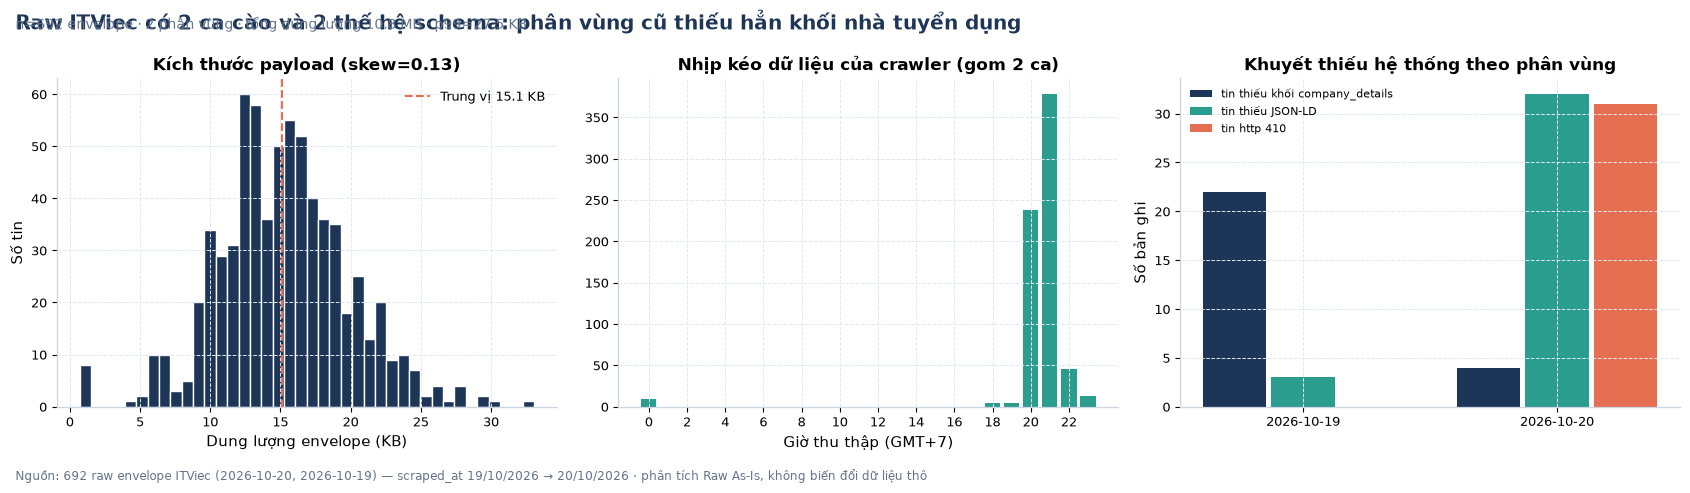

In [4]:
meta_profile = pd.DataFrame({
    "Giá trị phổ biến nhất": df_meta.apply(lambda s: str(s.astype(str).mode().iat[0])[:58] if len(s.astype(str).mode()) else "", axis=0),
    "Số giá trị độc nhất": df_meta.astype(str).nunique(),          # một số khóa mang list → so sánh dạng chuỗi
    "Trống (%)": (df_meta.isna().mean() * 100).round(2),
})
show(meta_profile, limit=40)

scraped = pd.to_datetime(df_meta["m_scraped_at"], errors="coerce", utc=True)
print(f"\n🕒 scraped_at hợp lệ: {scraped.notna().sum()}/{len(scraped)} | "
      f"chuỗi thu thập: {scraped.min()} → {scraped.max()}")
print(f"🌐 http_status: {df_meta['m_http_status'].value_counts().to_dict()} "
      f"(410 = tin đã bị gỡ khi crawler tới)")
print(f"🔖 version > 1 (CDC phát hiện tin đổi nội dung): {(df_meta['m_version'] > 1).sum()} bản ghi")
print(f"🛠️ scraper_version: {df_meta['m_scraper_version'].value_counts().to_dict()}")
print(f"#️⃣ canonical_hash trống: {df_meta['m_canonical_hash'].isna().sum()} bản ghi "
      f"= {int((df_meta['m_canonical_hash'].isna() & (df['_partition'] == df['_partition'].min())).sum())}/{df['_partition'].value_counts().min()} tin phân vùng cũ")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
kb = df["_bytes"]
axes[0].hist(kb / 1024, bins=40, color=PALETTE[0], edgecolor="white")
axes[0].axvline(kb.median() / 1024, color=C_WARN, ls="--", label=f"Trung vị {kb.median()/1024:.1f} KB")
axes[0].set_xlabel("Dung lượng envelope (KB)"), axes[0].set_ylabel("Số tin"), axes[0].legend()
axes[0].set_title(f"Kích thước payload (skew={kb.skew():.2f})")
hr = scraped.dt.tz_convert("Asia/Bangkok").dt.hour.value_counts().sort_index()
axes[1].bar(hr.index, hr.values, color=PALETTE[1])
axes[1].set_xticks(range(0, 24, 2)), axes[1].set_xlabel("Giờ thu thập (GMT+7)")
axes[1].set_title("Nhịp kéo dữ liệu của crawler (gom 2 ca)")
_dr = pd.DataFrame({"_partition": df["_partition"],
                    "_cd": df_top["company_details"].isna(),
                    "_jl": df_top["job_posting_jsonld"].isna(),
                    "_410": df_meta["m_http_status"].eq(410)})
drift = _dr.groupby("_partition").agg(
    **{"số tin": ("_cd", "size"),
       "tin thiếu khối company_details": ("_cd", "sum"),
       "tin thiếu JSON-LD": ("_jl", "sum"),
       "tin http 410": ("_410", "sum")})
ax = axes[2]
x = np.arange(len(drift))
for i, col in enumerate(["tin thiếu khối company_details", "tin thiếu JSON-LD", "tin http 410"]):
    ax.bar(x + i * 0.27, drift[col].values, width=0.25, color=PALETTE[i], label=col)
ax.set_xticks(x + 0.27), ax.set_xticklabels(drift.index, fontsize=9)
ax.set_ylabel("Số bản ghi"), ax.legend(fontsize=8), ax.set_title("Khuyết thiếu hệ thống theo phân vùng")
finalize(fig, "Raw ITViec có 2 ca cào và 2 thế hệ schema: phân vùng cũ thiếu hẳn khối nhà tuyển dụng",
         f"n={len(df)} envelope · {df['_partition'].nunique()} phân vùng · tổng dung lượng "
         f"{df['_bytes'].sum()/1e6:.1f} MB · p99={kb.quantile(.99)/1024:.1f} KB",
         "08_raw_size_and_timing.png")

## Bước 2 — Trụ cột 1: Độ hoàn thiện (Completeness & Missing Value Profiling)

**Null trá hình** là rủi ro số 1 của Raw As-Is. `df.isnull()` chỉ bắt `None/NaN`, trong khi ITViec giấu
khuyết thiếu trong ít nhất ba dạng:

- **chuỗi marketing thay cho giá trị số**: `"You'll love it"` (484 tin ở `salary_display_text`),
  `"Very attractive!!!"`, `"Great talent, great pay"`, `"Đăng nhập để xem mức lương"` → đây là **MNAR do
  chủ đích** của nhà tuyển dụng, không phải thiếu ngẫu nhiên;
- **chuỗi mang nghĩa "không có"**: `"No requirements"` trong `experienceRequirements` (63 tin) — giá trị
  *có thật* về mặt nghiệp vụ nhưng **không phải số**, làm hỏng phép trung bình;
- **rỗng có cấu trúc**: `skill_tags = []` (4 tin), `sections = {}` (4 tin), toàn bộ khối `company_details`
  vắng mặt (26 tin).

Bước này đo **hai mức**: khuyết thiếu theo `isnull()` và khuyết thiếu ngữ nghĩa sau khi quét mẫu ẩn.

In [5]:
MARKERS = ["", " ", "nan", "none", "null", "n/a", "na", "[]", "{}", "-", "…", "...",
           "chưa cập nhật", "chưa có", "không xác định", "thoả thuận", "thỏa thuận",
           "you'll love it", "you'll love i", "you'll love it!", "very attractive!!!",
           "great talent, great pay", "attractive", "attractive!", "attractive salary",
           "competitive", "competitive salary", "competitive package",
           "as per market standards", "đăng nhập để xem mức lương", "nego", "negotiation",
           "negotiable", "negotiable salary"]


def is_missing_value(v):
    """Định nghĩa khuyết thiếu tổng hợp: NaN/None + chuỗi rỗng/nhãn ẩn + list/dict rỗng."""
    if v is None or (isinstance(v, float) and pd.isna(v)):
        return True
    if isinstance(v, str):
        return (not v.strip()) or v.strip().lower() in MARKERS
    if isinstance(v, (list, dict, tuple)):
        return len(v) == 0
    return False


def hidden_null_scan(frame):
    rows = []
    for c in frame.columns:
        vals = frame[c].tolist()
        n_nan = sum(1 for v in vals if v is None or (isinstance(v, float) and pd.isna(v)))
        n_blank = sum(1 for v in vals if isinstance(v, str) and v.strip().lower() in MARKERS)
        n_empty_struct = sum(1 for v in vals if isinstance(v, (list, dict, tuple)) and len(v) == 0)
        tot = n_nan + n_blank + n_empty_struct
        if tot:
            rows.append({"Cột": c, "NaN/None": n_nan, "Chuỗi rỗng/nhãn ẩn": n_blank,
                         "List/dict rỗng": n_empty_struct, "Tổng khuyết thiếu": tot,
                         "Tỷ lệ (%)": round(tot / len(frame) * 100, 2)})
    return pd.DataFrame(rows).sort_values("Tỷ lệ (%)", ascending=False)


print("── 2.1 Khuyết thiếu theo `isnull()` trên 14 cột thô ──")
nan_table = pd.DataFrame({
    "Số dòng NaN (isnull())": df_top.isnull().sum(),
    "Đầy đủ (%)": (df_top.notna().mean() * 100).round(2),
}).sort_values("Số dòng NaN (isnull())", ascending=False)
show(nan_table)

print("\n── 2.2 Quét null trá hình (NaN + nhãn ẩn + list/dict rỗng) ──")
hn = hidden_null_scan(df_top)
show(hn, limit=30)
print(f"\n🔎 {len(hn)}/{len(raw_cols)} cột thô có khuyết thiếu ẩn hoặc tường minh; nặng nhất: "
      f"{hn.iloc[0]['Cột']} = {hn.iloc[0]['Tỷ lệ (%)']}%")

── 2.1 Khuyết thiếu theo `isnull()` trên 14 cột thô ──

── 2.2 Quét null trá hình (NaN + nhãn ẩn + list/dict rỗng) ──

🔎 14/14 cột thô có khuyết thiếu ẩn hoặc tường minh; nặng nhất: salary_display_text = 74.42%


,Số dòng NaN (isnull()),Đầy đủ (%)
posted_at_raw,57,91.76
work_model,38,94.51
job_posting_jsonld,35,94.94
salary_range_datalayer,27,96.10
work_location,26,96.24
industries,26,96.24
company_details,26,96.24
specialization,26,96.24
salary_display_text,10,98.55
company_url,8,98.84


,Cột,NaN/None,Chuỗi rỗng/nhãn ẩn,List/dict rỗng,Tổng khuyết thiếu,Tỷ lệ (%)
3,salary_display_text,10,505,0,515,74.42
5,salary_range_datalayer,27,482,0,509,73.55
10,posted_at_raw,57,0,0,57,8.24
9,work_model,38,0,0,38,5.49
7,job_posting_jsonld,35,0,0,35,5.06
8,work_location,26,0,0,26,3.76
12,industries,26,0,0,26,3.76
11,specialization,26,0,0,26,3.76
13,company_details,26,0,0,26,3.76
2,company_url,8,0,0,8,1.16


In [6]:
sec_n = df["sections"].map(lambda d: len(d) if isinstance(d, dict) else 0)
sec_bullets = df["sections"].map(lambda d: sum(len(v) for v in d.values() if isinstance(v, list)) if isinstance(d, dict) else 0)
sk_len = df["skill_tags"].map(lambda v: len(v) if isinstance(v, list) else 0)
spec_len = df["specialization"].map(lambda v: len(v) if isinstance(v, list) else 0)
ind_len = df["industries"].map(lambda v: len(v) if isinstance(v, list) else 0)
jl_keys = df_top["job_posting_jsonld"].map(lambda d: len(d) if isinstance(d, dict) else 0)
cd_keys = df_top["company_details"].map(lambda d: len(d) if isinstance(d, dict) else 0)

struct_completeness = pd.DataFrame({
    "Cấu trúc lồng": ["sections (dict mục JD)", "skill_tags (mảng thẻ)", "specialization (mảng)",
                      "industries (mảng)", "job_posting_jsonld (dict L3)", "company_details (dict DOM)"],
    "Trung vị số phần tử": [sec_n.median(), sk_len.median(), spec_len.median(), ind_len.median(), jl_keys.median(), cd_keys.median()],
    "Tối thiểu": [sec_n.min(), sk_len.min(), spec_len.min(), ind_len.min(), jl_keys.min(), cd_keys.min()],
    "Tin rỗng hoàn toàn": [(sec_n == 0).sum(), (sk_len == 0).sum(), (spec_len == 0).sum(),
                        (ind_len == 0).sum(), (jl_keys == 0).sum(), (cd_keys == 0).sum()],
    "Tin dưới chuẩn thông dụng": [(sec_n < 3).sum(), (sk_len < 3).sum(), (spec_len < 1).sum(),
                                (ind_len < 1).sum(), (jl_keys < 10).sum(), (cd_keys < 7).sum()],
})
show(struct_completeness)

print("\nBảng tần suất xuất hiện các key bên trong JSON-LD (L3):")
jl_cov = pd.DataFrame({
    "Khóa JSON-LD": [c.replace("job_posting_jsonld.", "") for c in jl_cols],
    "Số tin có": df[jl_cols].notna().sum().values,
    "Phủ (%)": (df[jl_cols].notna().mean() * 100).round(1).values,
    "Ví dụ": [str(df[c].dropna().iloc[0])[:44] if df[c].notna().any() else "" for c in jl_cols],
}).sort_values("Số tin có", ascending=False)
show(jl_cov, limit=30)

print("\nBảng tần suất xuất hiện các key bên trong company_details (khối nhà tuyển dụng):")
cd_cov = pd.DataFrame({
    "Khóa company_details": [c.replace("company_details.", "") for c in cd_cols],
    "Số tin có": df[cd_cols].notna().sum().values,
    "Phủ (%)": (df[cd_cols].notna().mean() * 100).round(1).values,
    "Ví dụ": [str(df[c].dropna().iloc[0]).replace("\n", "\\n")[:44] if df[c].notna().any() else "" for c in cd_cols],
}).sort_values("Số tin có", ascending=False)
show(cd_cov)

,Cấu trúc lồng,Trung vị số phần tử,Tối thiểu,Tin rỗng hoàn toàn,Tin dưới chuẩn thông dụng
0,sections (dict mục JD),4.0,0,4,8
1,skill_tags (mảng thẻ),6.0,0,4,67
2,specialization (mảng),1.0,0,26,26
3,industries (mảng),1.0,0,26,26
4,job_posting_jsonld (dict L3),16.0,0,35,39
5,company_details (dict DOM),8.0,0,26,26



Bảng tần suất xuất hiện các key bên trong JSON-LD (L3):

Bảng tần suất xuất hiện các key bên trong company_details (khối nhà tuyển dụng):


,Khóa JSON-LD,Số tin có,Phủ (%),Ví dụ
0,@context,657,94.9,http://schema.org
1,@type,657,94.9,JobPosting
3,title,657,94.9,AI Engineer Remote
5,validThrough,657,94.9,2026-11-03
7,description,657,94.9,"Top 3 Reasons To Join Us\r\nA transparent, sup"
6,skills,657,94.9,"AI, Python"
18,baseSalary.value.@type,657,94.9,QuantitativeValue
17,baseSalary.currency,657,94.9,USD
21,baseSalary.value.unitText,657,94.9,MONTH
16,baseSalary.@type,657,94.9,MonetaryAmount


,Khóa company_details,Số tin có,Phủ (%),Ví dụ
1,slogan,666,96.2,Working with RITVN isn’t just a job! IT’S A
2,Mô hình công ty,666,96.2,Thuê ngoài
3,Lĩnh vực công ty,666,96.2,Thuê Ngoài Phát Triển Phần Mềm
4,Quy mô công ty,666,96.2,1-50\nnhân viên
6,Thời gian làm việc,666,96.2,Thứ 2 - Thứ 6
5,Quốc gia,666,96.2,Denmark
7,Làm việc ngoài giờ,666,96.2,Không có OT
0,rating,357,51.6,4.4


🖼️  Đã lưu reports\figures\itviec\01_data_completeness_missingno.png (DPI 300)


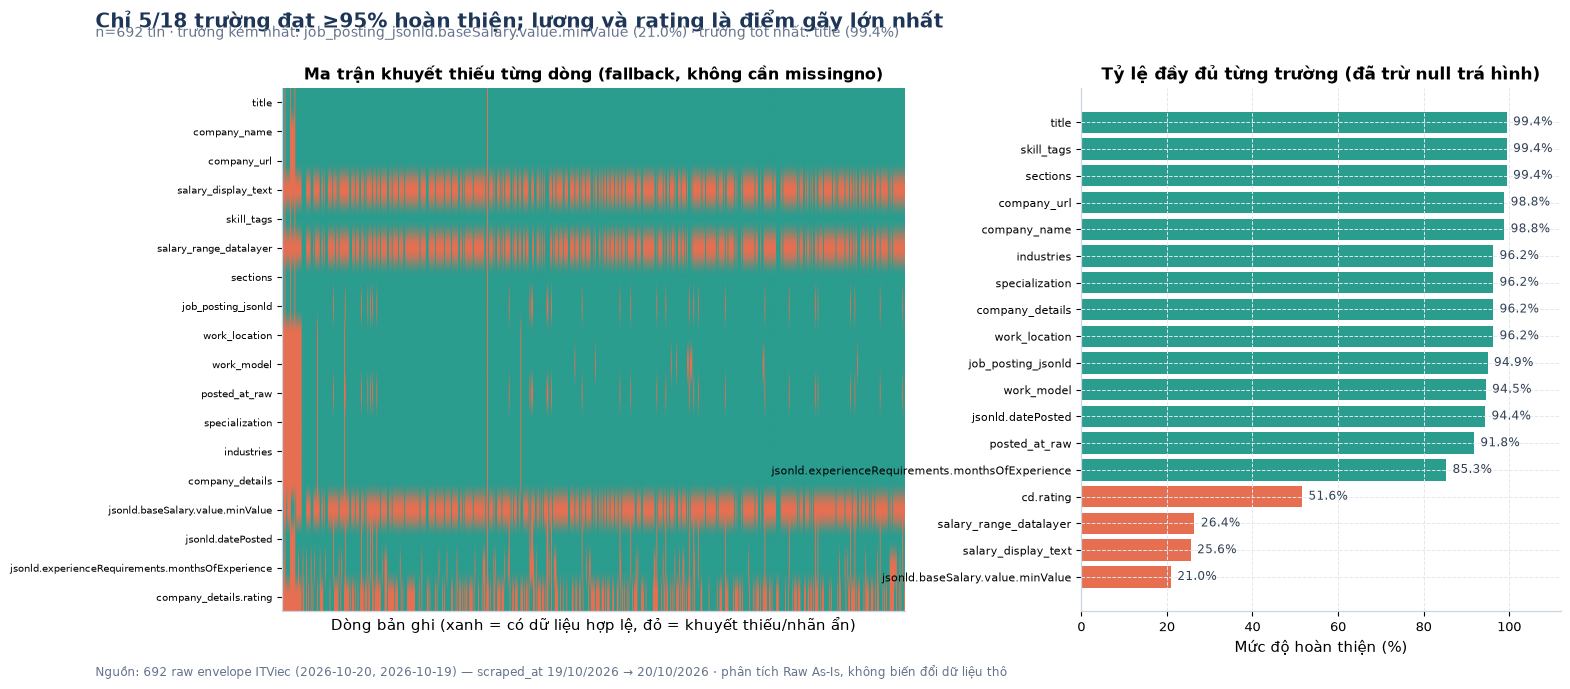

In [7]:
ANALYSIS_COLS = raw_cols + ["job_posting_jsonld.baseSalary.value.minValue",
                           "job_posting_jsonld.datePosted",
                           "job_posting_jsonld.experienceRequirements.monthsOfExperience",
                           "company_details.rating"]
mask = pd.DataFrame({c: df_top[c].map(is_missing_value).astype(int) if c in raw_cols
                     else df[c].map(is_missing_value).astype(int) for c in ANALYSIS_COLS})
comp_pct = (100 - mask.mean() * 100).sort_values()

try:
    import missingno as msno
    HAS_MSNO = True
except ImportError:
    HAS_MSNO = False

fig = plt.figure(figsize=(16.5, 6.8))
gs = gridspec.GridSpec(1, 2, width_ratios=[1.3, 1], wspace=0.32)
ax_m = fig.add_subplot(gs[0])
if HAS_MSNO:
    msno.matrix((1 - mask).astype(float), ax=ax_m, sparkline=False, color=(0.11, 0.21, 0.34))
    ax_m.set_title("Ma trận khuyết thiếu (missingno)", fontsize=11.5, fontweight="bold")
else:
    im = ax_m.imshow((1 - mask).values.T, aspect="auto", cmap=ListedColormap([C_WARN, C_OK]), vmin=0, vmax=1)
    ax_m.set_yticks(range(len(ANALYSIS_COLS)))
    ax_m.set_yticklabels([c.replace("job_posting_jsonld.", "jsonld.") for c in ANALYSIS_COLS], fontsize=7.5)
    ax_m.set_xticks([]), ax_m.grid(False)
    ax_m.set_xlabel("Dòng bản ghi (xanh = có dữ liệu hợp lệ, đỏ = khuyết thiếu/nhãn ẩn)")
    ax_m.set_title("Ma trận khuyết thiếu từng dòng (fallback, không cần missingno)", fontsize=11.5, fontweight="bold")

ax_b = fig.add_subplot(gs[1])
bars = ax_b.barh(range(len(comp_pct)), comp_pct.values,
                 color=[C_WARN if v < 70 else C_OK for v in comp_pct.values])
ax_b.set_yticks(range(len(comp_pct)))
ax_b.set_yticklabels([c.replace("job_posting_jsonld.", "jsonld.").replace("company_details.", "cd.")
                      for c in comp_pct.index], fontsize=8)
ax_b.set_xlim(0, 112), ax_b.set_xlabel("Mức độ hoàn thiện (%)")
for i, v in enumerate(comp_pct.values):
    ax_b.text(v + 1.5, i, f"{v:.1f}%", va="center", fontsize=8.5, color="#334155")
ax_b.set_title("Tỷ lệ đầy đủ từng trường (đã trừ null trá hình)")
finalize(fig, "Chỉ 5/18 trường đạt ≥95% hoàn thiện; lương và rating là điểm gãy lớn nhất",
         f"n={len(df)} tin · trường kém nhất: {comp_pct.index[0]} ({comp_pct.iloc[0]:.1f}%) · "
         f"trường tốt nhất: {comp_pct.index[-1]} ({comp_pct.iloc[-1]:.1f}%)",
         "01_data_completeness_missingno.png")

### Đọc đồ thị 01 & kết luận Trụ cột 1
- `company_details.rating` khuyết **48.4%** (335/692) và `salary_display_text` chỉ *thực sự chứa số* ở
  ~25% tin ⇒ hai trường quan trọng nhất cho mô hình lương lại là hai trường khuyết nặng nhất.
- `salary_range_datalayer` khuyết nhiều hơn `salary_display_text` (27 so với 10 dòng `None`) ⇒ **L2 không
  phải bản sao của L1**, hai tầng phải được đo riêng.
- **MCAR vs MNAR**: khối `company_details`/`work_location`/`posted_at_raw` vắng nguyên cụm ở **26 tin** —
  trong đó 22 tin thuộc phân vùng 19/10 (đặc tính *crawler thế hệ cũ*, sửa được bằng re-crawl) và 4 tin ở
  phân vùng mới (đặc tính *trang lỗi/chết*). Lương ẩn kiểu `"You'll love it"` là **MNAR chủ đích** ⇒ bắt buộc
  giữ cờ `is_salary_hidden`, tuyệt đối không suy diễn bằng trung vị.

── 2.3 Tách nguyên nhân khuyết thiếu: lỗi crawler (theo phân vùng) vs lỗi trang (http_status) ──
http_status  200  410  All
partition                 
2026-10-19    22    0   22
2026-10-20   639   31  670
All          661   31  692

Số tin khuyết (và %) theo tổ hợp phân vùng × http_status:

⛔ 31 tin http 410 (đã bị gỡ khi cào): mất 100% JSON-LD và posted_at_raw nhưng VẪN CÒN title/company/salary UI → cần gắn cờ `is_dead_listing`, không được tính là tin đang mở.
🕰️ 22 tin phân vùng cũ: thiếu nguyên khối DOM mở rộng (work_location, work_model, specialization, industries, company_details, posted_at_raw) → khuyết do phiên bản crawler, không do nguồn.
🖼️  Đã lưu reports\figures\itviec\15_dead_listing_and_schema_drift.png (DPI 300)


Số tin  thiếu company_details  thiếu JSON-LD  thiếu work_location  thiếu posted_at_raw  thiếu company_details (%)  thiếu JSON-LD (%)  thiếu work_location (%)  thiếu posted_at_raw (%)
partition  http_status                                                                                                                                                                                        
2026-10-19 200              22                     22              3                   22                   22                      100.0               13.6                    100.0                    100.0
2026-10-20 200             639                      4              1                    4                    4                        0.6                0.2                      0.6                      0.6
           410              31                      0             31                    0                   31                        0.0              100.0                      0.0                    100.0

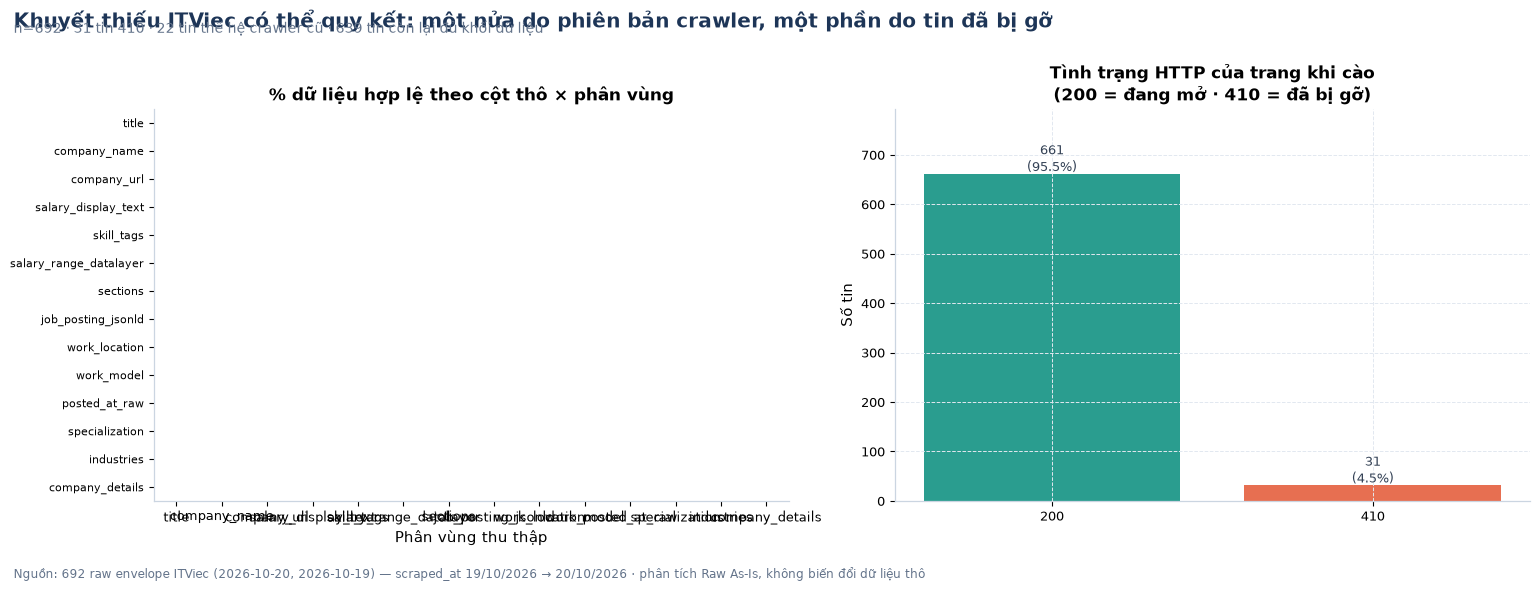

In [8]:
print("── 2.3 Tách nguyên nhân khuyết thiếu: lỗi crawler (theo phân vùng) vs lỗi trang (http_status) ──")
drift_tbl = pd.DataFrame({
    "http_status": df_meta["m_http_status"],
    "partition": df["_partition"],
    "thiếu company_details": df_top["company_details"].isna(),
    "thiếu JSON-LD": df_top["job_posting_jsonld"].isna(),
    "thiếu work_location": df["work_location"].isna(),
    "thiếu posted_at_raw": df["posted_at_raw"].isna(),
    "thiếu work_model": df["work_model"].isna(),
})
print(pd.crosstab(drift_tbl["partition"], drift_tbl["http_status"], margins=True).to_string())
print("\nSố tin khuyết (và %) theo tổ hợp phân vùng × http_status:")
_MISS_COLS = ["thiếu company_details", "thiếu JSON-LD", "thiếu work_location", "thiếu posted_at_raw"]
_grp_n = drift_tbl.groupby(["partition", "http_status"]).size().rename("Số tin")
_grp_sum = drift_tbl.groupby(["partition", "http_status"])[_MISS_COLS].sum()
_grp_pct = (drift_tbl.groupby(["partition", "http_status"])[_MISS_COLS].mean() * 100).round(1)
_grp_pct.columns = [c + " (%)" for c in _MISS_COLS]
grp = pd.concat([_grp_n, _grp_sum, _grp_pct], axis=1)
show(grp)

n410 = int((df_meta["m_http_status"] == 410).sum())
old_era = int((df["_partition"] == df["_partition"].min()).sum())
print(f"\n⛔ {n410} tin http 410 (đã bị gỡ khi cào): mất 100% JSON-LD và posted_at_raw nhưng VẪN CÒN "
      f"title/company/salary UI → cần gắn cờ `is_dead_listing`, không được tính là tin đang mở.")
print(f"🕰️ {old_era} tin phân vùng cũ: thiếu nguyên khối DOM mở rộng (work_location, work_model, "
      f"specialization, industries, company_details, posted_at_raw) → khuyết do phiên bản crawler, không do nguồn.")

ht = df.groupby("_partition").apply(
    lambda g: (1 - df_top.loc[g.index].map(is_missing_value).mean()) * 100, include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8))
heat = ht.reindex(raw_cols).sort_values(ht.columns[0], ascending=True)
im = axes[0].imshow(heat.values.T, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
axes[0].set_yticks(range(len(heat.columns))), axes[0].set_yticklabels(heat.index, fontsize=8)
axes[0].set_xticks(range(len(heat.index))), axes[0].set_xticklabels(heat.columns, fontsize=9)
axes[0].set_xlabel("Phân vùng thu thập"), axes[0].grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        axes[0].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5,
                     color="black" if 45 < v < 95 else "white")
axes[0].set_title("% dữ liệu hợp lệ theo cột thô × phân vùng")

st = df_meta["m_http_status"].value_counts().sort_index()
axes[1].bar([str(x) for x in st.index], st.values, color=[C_OK, C_WARN][:len(st)])
for i, v in enumerate(st.values):
    axes[1].text(i, v + 6, f"{v}\n({v/len(df)*100:.1f}%)", ha="center", fontsize=9.5, color="#334155")
axes[1].set_ylabel("Số tin"), axes[1].set_ylim(0, max(st.values) * 1.2)
axes[1].set_title("Tình trạng HTTP của trang khi cào\n(200 = đang mở · 410 = đã bị gỡ)")
finalize(fig, "Khuyết thiếu ITViec có thể quy kết: một nửa do phiên bản crawler, một phần do tin đã bị gỡ",
         f"n={len(df)} · {n410} tin 410 · {old_era} tin thế hệ crawler cũ · "
         f"{len(df) - n410 - old_era} tin còn lại đủ khối dữ liệu",
         "15_dead_listing_and_schema_drift.png")

## Bước 3 — Trụ cột 2: Tính hợp lệ & Kiểu dữ liệu (Validity & Types)

ITViec trả về **bốn dạng dữ liệu chưa dùng được ngay** cho mô hình số học:

1. **Lương là chuỗi tự do, ba bản bản sao**: `"1,000 - 1,300 USD"`, `"Up to 35tr (thương lượng)"`,
   `"70m - 100m"`, `"3.000.000 per month"`, `"You'll love it"`, `"Nego"`, `"Đăng nhập để xem mức lương"`.
   Dấu `,` vừa là phân cách hàng nghìn (Anh-Mỹ) vừa là phân cách thập phân ( kiểu Việt) ⇒ phải đọc **cả ngữ cảnh đơn vị** chứ không được `float()`.
2. **Trùng kiểu dữ liệu trong một khóa**: `experienceRequirements.monthsOfExperience` có giá trị `int`
   (10/37/61) nhưng chính khóa cha `experienceRequirements` lại là **chuỗi** `"No requirements"` ở 63 tin.
   `company_details.rating` là **chuỗi `"4.8"`**, không phải float.
3. **Nhiễu ký tự điều khiển**: `posted_at_raw = "Đăng\n4 ngày trước"`, `Quy mô công ty = "1000+\nnhân viên"`,
   `description` chứa nguyên HTML (`<p>`, `<br>`, `&nbsp;`) và `\r\n`.
4. **Nhãn chuẩn hóa làm mất thông tin**: `job_posting_jsonld.title` khác `title` ở **489/657** tin (74.4%)
   — JSON-LD cắt dấu ngoặc vuông/tròn (`[HCM]`, `(Remote)`) và **làm mất toàn bộ dấu tiếng Việt**
   ("Xây Dựng" → "Xay Dung").

Cell đầu tiên **đếm tần suất mẫu hình** (thay mọi số bằng `N`) để biết cần bao nhiêu luật parse.

In [9]:
def pattern_of(s):
    if s is None or (isinstance(s, float) and pd.isna(s)):
        return "<None>"
    return re.sub(r"\d+(?:[.,]\d+)*", "N", str(s).replace("\n", " ")).strip()[:52]


print("── 3.1 Hệ mẫu hình chuỗi lương (thay số bằng N) ──")
pat_tbl = []
for layer, col in [("L1 salary_display_text", "salary_display_text"),
                   ("L2 salary_range_datalayer", "salary_range_datalayer")]:
    pc = df_top[col].map(pattern_of).value_counts()
    pat_tbl.append(pd.DataFrame({"Tầng": layer, "Mẫu hình": pc.index, "Số tin": pc.values,
                                 "Tỷ lệ (%)": (pc.values / len(df) * 100).round(1)}))
PATS = pd.concat(pat_tbl, ignore_index=True)
show(PATS.groupby(["Tầng", "Mẫu hình"], as_index=False)["Số tin"].sum()
     .sort_values(["Tầng", "Số tin"], ascending=[True, False]), limit=48)
n_pat = PATS["Mẫu hình"].nunique()
print(f"\n📏 Tổng cộng {n_pat} mẫu hình lương khác nhau trên 2 tầng chuỗi — mỗi mẫu hình là một luật parse bắt buộc.")

── 3.1 Hệ mẫu hình chuỗi lương (thay số bằng N) ──

📏 Tổng cộng 47 mẫu hình lương khác nhau trên 2 tầng chuỗi — mỗi mẫu hình là một luật parse bắt buộc.


,Tầng,Mẫu hình,Số tin
14,L1 salary_display_text,You'll love it,484
4,L1 salary_display_text,N - N USD,163
16,L1 salary_display_text,Đăng nhập để xem mức lương,19
0,L1 salary_display_text,<None>,10
11,L1 salary_display_text,Up to N$,2
12,L1 salary_display_text,Up to Ntr (thương lượng),2
13,L1 salary_display_text,Upto $N,2
1,L1 salary_display_text,Approximately $N,1
2,L1 salary_display_text,Cạnh tranh nhất,1
3,L1 salary_display_text,Cạnh tranh theo năng lực,1


── 3.2 Phân loại tính hợp lệ theo từng tầng ──

Phân bố tiền tệ trong phần bóc được số:

⚠️  baseSalary ghi `currency: VND` nhưng giá trị chỉ 1–2 (4 tin): toàn bộ đều có title dạng `Jjob-*` và khuyết `company_name` → đây là fixture unit-test của crawler lọt vào kho raw (chứng minh ở Bước 4.2), KHÔNG phải lỗi gán nhầm đơn vị của trang tuyển dụng thật.
🖼️  Đã lưu reports\figures\itviec\10_salary_validity_kinds.png (DPI 300)


,ui,dl,ld
L1 Chỉ có trần lương (Up to),10,16,0
L1 Dải min–max,164,156,0
L1 Dải min–max (JSON-LD),0,0,145
L1 Lương cố định 1 mốc,0,4,0
L1 Vắng giá trị (null),10,27,547
L1 Ẩn số / placeholder marketing,508,489,0


,ui,dl,ld
cur,,,
USD,171,152,653
VND,3,24,4


,title,baseSalary.min,baseSalary.max,currency,L2 gốc
10,Jjob-ba-300,1.0,2.0,VND,NaN
11,Jjob-bon-400,1.0,2.0,VND,NaN
12,Jjob-hai-200,1.0,2.0,VND,NaN
13,Jjob-mot-100,1.0,2.0,VND,NaN


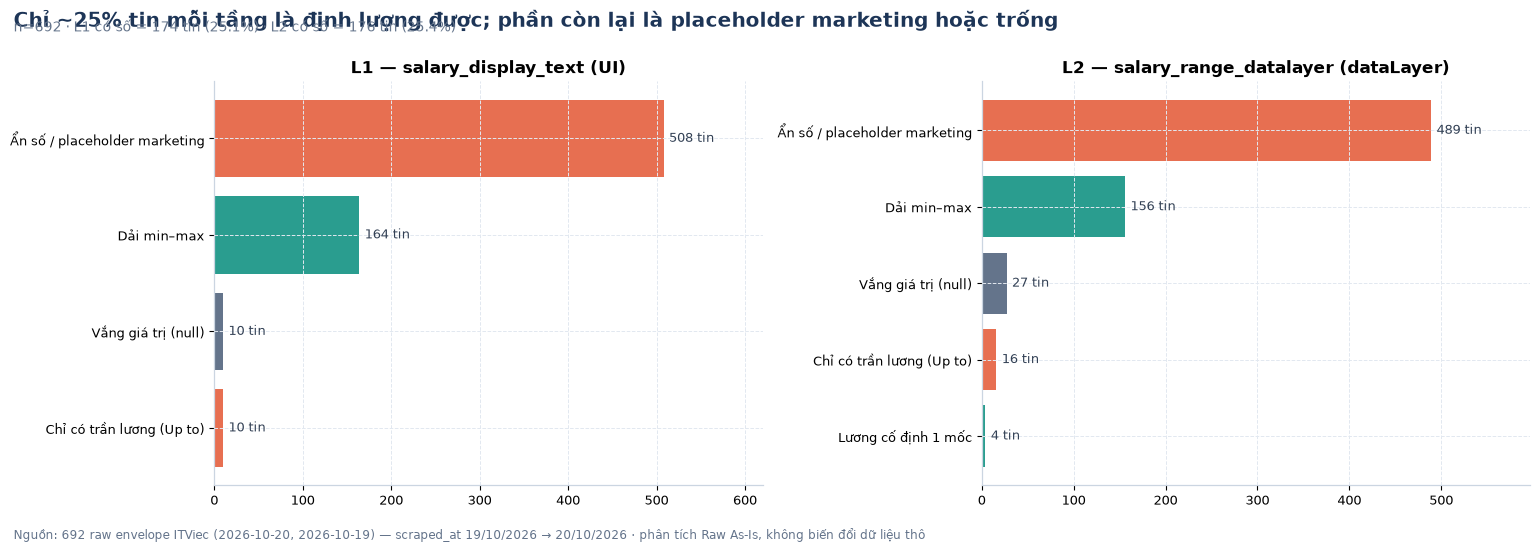

In [10]:
PLACEHOLDER_KEYS = ["you'll love", "very attractive", "great talent", "attractive", "competitive",
                    "negotiab", "nego", "as per market", "đăng nhập để xem", "thoả thuận", "thỏa thuận",
                    "cạnh tranh", "thu nhập cạnh tranh", "according to", "market rate"]


def parse_salary_itviec(s):
    """(min, max, currency, kind) từ chuỗi lương thô — GIỮ NGUYÊN đồng tiền mà tin khai báo.

    VND -> quy về 'Triệu VND/tháng' (3.000.000 và 3tr cùng tiền tệ, chỉ khác bậc nội tệ);
    USD -> giữ nguyên 'USD/tháng', KHÔNG nhân tỷ giá. Đây là diễn giải để ĐO, không phải làm sạch:
    chuỗi gốc trong `df_top`/trên đĩa vẫn nguyên vẹn.
    """
    if not isinstance(s, str) or not s.strip():
        return None, None, None, "Vắng giá trị (null)"
    low = s.lower().replace("\n", " ")
    nums = []
    for tok in re.findall(r"\d+(?:[.,]\d+)*", low):
        if re.fullmatch(r"\d{1,3}(?:\.\d{3})+", tok):            # 3.000.000 → phân cách hàng nghìn kiểu VN
            nums.append(float(tok.replace(".", "")))
        elif re.fullmatch(r"\d{1,3}(?:,\d{3})+", tok):           # 1,000 → phân cách hàng nghìn kiểu Anh-Mỹ
            nums.append(float(tok.replace(",", "")))
        else:                                                     # 1,5 → 1.5 (thập phân)
            nums.append(float(tok.replace(",", ".")))
    if not nums:
        if any(k in low for k in PLACEHOLDER_KEYS):
            return None, None, None, "Ẩn số / placeholder marketing"
        return None, None, None, "Không bóc được số"
    is_usd = ("usd" in low) or ("$" in low)
    is_vnd_word = ("vnd" in low) or ("triệu" in low) or bool(re.search(r"(^|[^a-z])tr([^a-z]|$)", low))
    is_trieu_suffix = bool(re.search(r"\d\s*(?:m|mil|million)\b", low))
    big_number = max(nums) >= 100_000                            # 3.000.000 / 12,000,000 → VND tuyệt đối
    if is_usd:
        conv, cur = (lambda v: v), "USD"                      # giữ bậc USD/tháng, không quy đổi
    elif big_number:
        conv, cur = (lambda v: v / 1e6), "VND"
    elif is_vnd_word or is_trieu_suffix:
        conv, cur = (lambda v: v), "VND"
    else:
        return None, None, None, "Có số nhưng thiếu đơn vị tiền tệ"
    if re.search(r"up\s?to|upto|approximately|xấp xỉ", low) and len(nums) == 1:
        return None, round(conv(nums[-1]), 2), cur, "Chỉ có trần lương (Up to)"
    if len(nums) == 1:
        v = round(conv(nums[0]), 2)
        return v, v, cur, "Lương cố định 1 mốc"
    return round(conv(min(nums)), 2), round(conv(max(nums)), 2), cur, "Dải min–max"


SAL = {}
for tag, col in [("ui", "salary_display_text"), ("dl", "salary_range_datalayer")]:
    parsed = df_top[col].map(parse_salary_itviec)
    SAL[tag] = pd.DataFrame(parsed.tolist(), columns=["min", "max", "cur", "kind"], index=df.index)

# tầng L3: schema.org baseSalary đã là số có kiểu → chỉ đổi BẬC của nội tệ VND, KHÔNG nhân tỷ giá USD
ld_cur = df["job_posting_jsonld.baseSalary.currency"]
ld_min = pd.to_numeric(df["job_posting_jsonld.baseSalary.value.minValue"], errors="coerce")   # giá trị gốc
ld_max = pd.to_numeric(df["job_posting_jsonld.baseSalary.value.maxValue"], errors="coerce")
_ld_is_usd = ld_cur.eq("USD")
ld_factor = np.where(_ld_is_usd, 1.0, np.where(ld_min > 1000, 1 / 1e6, 1.0))
ld_cur_norm = ld_cur.map(lambda c: "USD" if isinstance(c, str) and c.strip().upper() == "USD"
                         else ("VND" if isinstance(c, str) and c.strip().upper() == "VND" else c))
SAL["ld"] = pd.DataFrame({
    "min": (ld_min * ld_factor).round(2), "max": (ld_max * ld_factor).round(2),
    "cur": ld_cur_norm, "kind": np.where(ld_max.notna(), "Dải min–max (JSON-LD)", "Vắng giá trị (null)"),
}, index=df.index)
suspicious_ld = (ld_cur.eq("VND") & (ld_max < 100))

print("── 3.2 Phân loại tính hợp lệ theo từng tầng ──")
val_tbl = pd.DataFrame({k: v["kind"].value_counts() for k, v in SAL.items()}).fillna(0).astype(int)
val_tbl.index = ["L1 " + i for i in val_tbl.index]
show(val_tbl)
print("\nPhân bố tiền tệ trong phần bóc được số:")
show(pd.DataFrame({k: v["cur"].value_counts() for k, v in SAL.items()}).fillna(0).astype(int))
print(f"\n⚠️  baseSalary ghi `currency: VND` nhưng giá trị chỉ 1–2 ({int(suspicious_ld.sum())} tin): "
      f"toàn bộ đều có title dạng `Jjob-*` và khuyết `company_name` → đây là fixture unit-test của crawler "
      f"lọt vào kho raw (chứng minh ở Bước 4.2), KHÔNG phải lỗi gán nhầm đơn vị của trang tuyển dụng thật.")
if suspicious_ld.any():
    show(pd.DataFrame({
        "title": df_top.loc[suspicious_ld, "title"],
        "baseSalary.min": df.loc[suspicious_ld, "job_posting_jsonld.baseSalary.value.minValue"],
        "baseSalary.max": df.loc[suspicious_ld, "job_posting_jsonld.baseSalary.value.maxValue"],
        "currency": ld_cur[suspicious_ld],
        "L2 gốc": df_top.loc[suspicious_ld, "salary_range_datalayer"]}).head(4))

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.4))
for ax, tag, ttl in [(axes[0], "ui", "L1 — salary_display_text (UI)"),
                     (axes[1], "dl", "L2 — salary_range_datalayer (dataLayer)")]:
    kc = SAL[tag]["kind"].value_counts()
    ax.barh(range(len(kc)), kc.values,
            color=[C_OK if "Dải" in k or "cố định" in k or "JSON" in k else (C_MUTE if "null" in k else C_WARN) for k in kc.index])
    ax.set_yticks(range(len(kc))), ax.set_yticklabels(kc.index, fontsize=9)
    label_bars(ax, kc.values, fmt="{:.0f} tin")
    ax.set_xlim(0, kc.max() * 1.22), ax.set_title(ttl)
    ax.invert_yaxis()
finalize(fig, "Chỉ ~25% tin mỗi tầng là định lượng được; phần còn lại là placeholder marketing hoặc trống",
         f"n={len(df)} · L1 có số = {int(SAL['ui']['max'].notna().sum())} tin "
         f"({SAL['ui']['max'].notna().mean()*100:.1f}%) · L2 có số = {int(SAL['dl']['max'].notna().sum())} tin "
         f"({SAL['dl']['max'].notna().mean()*100:.1f}%)",
         "10_salary_validity_kinds.png")

### 3.3 Ba tầng lương có nhất quán không? — quyết định chọn tầng nào làm chuẩn

Nếu `salary_display_text` (L1), `salary_range_datalayer` (L2) và `baseSalary` (L3) luôn giống nhau thì chỉ
cần giữ một tầng. Thực tế chúng **bổ sung cho nhau**: có những tin UI ẩn lương nhưng dataLayer lại ghi số.
Cell dưới đo ba chỉ số: trùng tuyệt đối, số tin thu hồi thêm được khi gộp tầng, và mức chênh giá trị.

⚠️ **Yêu cầu nhất quán theo dòng.** `min`, `max`, `currency`, `kind` của một tin phải đến từ **cùng một tầng**.
Nếu gộp từng cột độc lập (kiểu `combine_first`), sàn có thể lấy từ tầng ghi USD trong khi trần lấy từ tầng ghi
VND — tạo ra một cặp số vô nghĩa. Notebook này chọn theo dòng và **đo xem cách cũ sẽ trộn tiền tệ ở bao nhiêu tin**.

── 3.3 Đối chiếu ba tầng lương ──
   Trùng tuyệt đối L1 == L2                : 618/692 (89.3%)
   L1 ẩn nhưng L2 mở (và ngược lại)        : 18 + 16 tin
   L3 có số trong khi CẢ HAI tầng chuỗi ẩn : 9 tin (thu hồi thêm nhờ JSON-LD)
   baseSalary.value (chuỗi) khác L1        : 74 tin

➡️ Gộp 3 tầng NGUYÊN TẮC THEO DÒNG (ưu tiên L3→L2→L1): 201/692 tin (29.0%) có lương số học được, tăng 25 tin so với chỉ dùng L2.
   sàn và trần đến từ HAI tầng khác nhau: 1 tin; trong đó 1 tin mà hai tầng đó ghi HAI tiền tệ khác nhau → cách gộp cũ (combine_first từng cột) sẽ sinh ra cặp min/max vô nghĩa và làm 1 tin đổi luôn giá trị sàn so với cách chọn theo dòng. Số cặp trộn tiền tệ thực sự đi vào phân tích ở notebook này là 0.
   Tiền tệ của 201 tin định lượng được sau khi gộp: {'USD': 173, 'VND': 28}
🖼️  Đã lưu reports\figures\itviec\09_salary_three_layer_consistency.png (DPI 300)


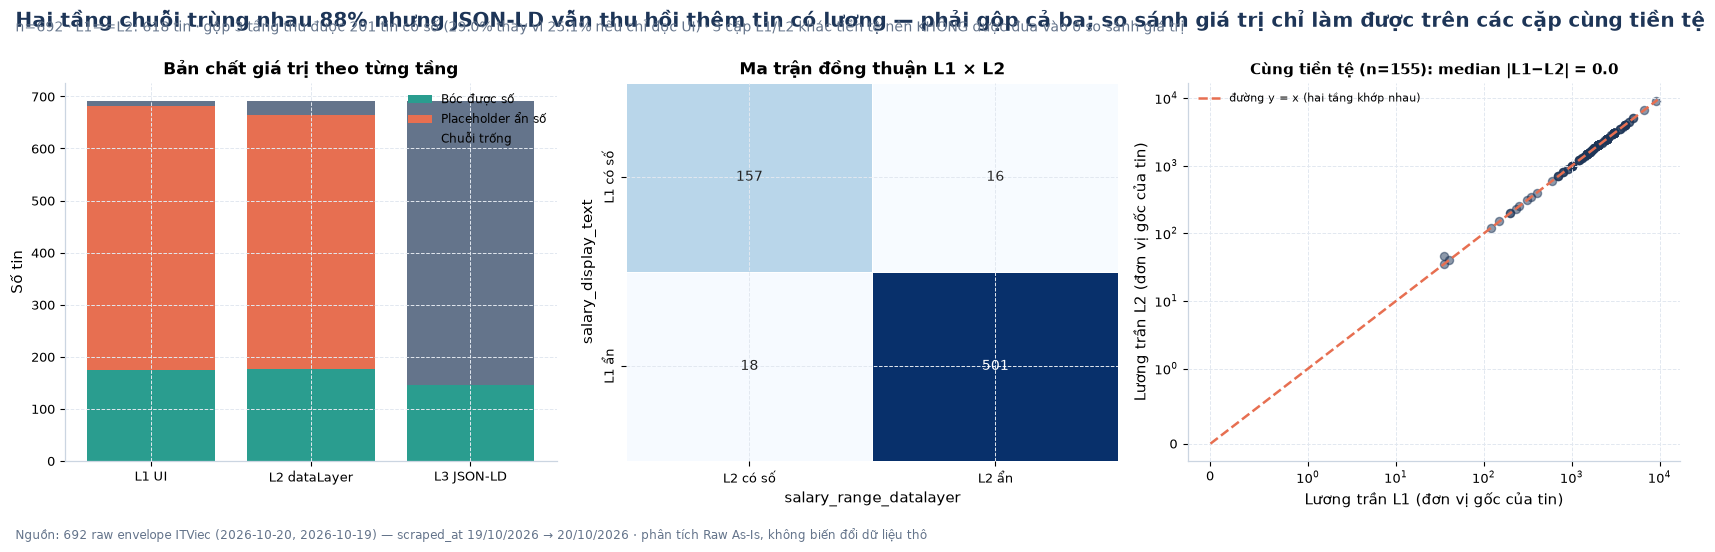

In [11]:
l1 = df_top["salary_display_text"].astype("string").fillna("<NULL>")
l2 = df_top["salary_range_datalayer"].astype("string").fillna("<NULL>")
exact = int((l1 == l2).sum())
ld_val = df["job_posting_jsonld.baseSalary.value.value"].astype("string").fillna("<NULL>")

def _hidden(s: pd.Series) -> pd.Series:
    """Cờ 'bị ẩn sau placeholder' cho một cột chuỗi (None/NaN cũng tính là ẩn)."""
    return s.map(lambda v: (not isinstance(v, str)) or v.strip() == ""
                 or v.strip().lower() in MARKERS
                 or any(k in v.lower() for k in PLACEHOLDER_KEYS))


h1, h2 = _hidden(df_top["salary_display_text"]), _hidden(df_top["salary_range_datalayer"])
ld_extra = int((SAL["ld"]["max"].notna() & h1 & h2).sum())

print("── 3.3 Đối chiếu ba tầng lương ──")
print(f"   Trùng tuyệt đối L1 == L2                : {exact}/{len(df)} ({exact/len(df)*100:.1f}%)")
print(f"   L1 ẩn nhưng L2 mở (và ngược lại)        : {int((h1 & ~h2).sum())} + {int((~h1 & h2).sum())} tin")
print(f"   L3 có số trong khi CẢ HAI tầng chuỗi ẩn : {ld_extra} tin (thu hồi thêm nhờ JSON-LD)")
print(f"   baseSalary.value (chuỗi) khác L1        : {int(((ld_val != l1) & (ld_val != '<NULL>')).sum())} tin")

LAYER_ORDER = ["ld", "dl", "ui"]                       # ưu tiên L3 JSON-LD → L2 dataLayer → L1 UI


def _first_layer_with(col):
    """Với mỗi DÒNG, trả về (tầng, giá trị, tiền tệ) của tầng ĐẦU TIÊN theo LAYER_ORDER có `col` không trống."""
    lay = pd.Series(pd.NA, index=df.index, dtype="object")
    val = pd.Series(np.nan, index=df.index, dtype="float")
    cur = pd.Series(pd.NA, index=df.index, dtype="object")
    done = pd.Series(False, index=df.index)
    for lg in LAYER_ORDER:
        take = (~done) & SAL[lg][col].notna()
        lay[take], val[take], cur[take] = lg, SAL[lg][col][take], SAL[lg]["cur"][take]
        done = done | take
    return lay, val, cur


_min_layer, _min_val, _min_cur = _first_layer_with("min")
_max_layer, merged_max, _max_cur = _first_layer_with("max")

# Gộp THEO DÒNG: lấy tầng đã cung cấp giá trị TRẦN làm gốc, rồi rút min/cur/kind CÙNG tầng đó.
merged_min = pd.Series(np.nan, index=df.index, dtype="float")
merged_cur = pd.Series(pd.NA, index=df.index, dtype="object")
merged_kind = pd.Series(pd.NA, index=df.index, dtype="object")
for lg in LAYER_ORDER:
    take = _max_layer.eq(lg)
    merged_min[take] = SAL[lg]["min"][take]
    merged_cur[take] = SAL[lg]["cur"][take]
    merged_kind[take] = SAL[lg]["kind"][take]

# Đối chiếu cách gộp cũ (mỗi cột tự chọn tầng) để định lượng rủi ro trộn tiền tệ của cách đó.
_old_min = SAL["ld"]["min"].combine_first(SAL["dl"]["min"]).combine_first(SAL["ui"]["min"])
_c_min = _min_cur.fillna("<NA>").astype(str)
_c_max = _max_cur.fillna("<NA>").astype(str)
n_mix = int((_c_min.ne("<NA>") & _c_max.ne("<NA>") & _c_min.ne(_c_max)).sum())
_l_min = _min_layer.fillna("").astype(str)
_l_max = _max_layer.fillna("").astype(str)
n_layer_diff = int((_l_min.ne("") & _l_max.ne("") & _l_min.ne(_l_max)).sum())
n_old_diff = int(((merged_min.notna() ^ _old_min.notna())
                  | (merged_min.notna() & _old_min.notna() & (merged_min - _old_min).abs().gt(1e-9))).sum())

layer_used = _max_layer.map({"ld": "L3 JSON-LD", "dl": "L2 dataLayer", "ui": "L1 UI"}).fillna("Không định lượng được")
n_merged = int(merged_max.notna().sum())
print(f"\n➡️ Gộp 3 tầng NGUYÊN TẮC THEO DÒNG (ưu tiên L3→L2→L1): {n_merged}/{len(df)} tin ({n_merged/len(df)*100:.1f}%) "
      f"có lương số học được, tăng {n_merged - int(SAL['dl']['max'].notna().sum())} tin so với chỉ dùng L2.")
print(f"   sàn và trần đến từ HAI tầng khác nhau: {n_layer_diff} tin; trong đó {n_mix} tin mà hai tầng đó "
      f"ghi HAI tiền tệ khác nhau → cách gộp cũ (combine_first từng cột) sẽ sinh ra cặp min/max vô nghĩa "
      f"và làm {n_old_diff} tin đổi luôn giá trị sàn so với cách chọn theo dòng. "
      f"Số cặp trộn tiền tệ thực sự đi vào phân tích ở notebook này là 0.")
print(f"   Tiền tệ của {n_merged} tin định lượng được sau khi gộp: {merged_cur.value_counts().to_dict()}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
stack = pd.DataFrame({
    "L1 UI": SAL["ui"]["kind"].value_counts(), "L2 dataLayer": SAL["dl"]["kind"].value_counts(),
    "L3 JSON-LD": SAL["ld"]["kind"].value_counts(),
}).fillna(0).astype(int)
cat_num = [i for i in stack.index if ("Dải" in i or "cố định" in i or "trần" in i)]
cat_hid = [i for i in stack.index if "Ẩn số" in i]
cat_null = [i for i in stack.index if "null" in i]
bottom = np.zeros(len(stack.columns))
for grp, col in [(cat_num, C_OK), (cat_hid, C_WARN), (cat_null, C_MUTE)]:
    vals = stack.loc[stack.index.isin(grp)].sum().values
    axes[0].bar(stack.columns, vals, bottom=bottom, color=col,
                label={"num": "Bóc được số", "hid": "Placeholder ẩn số"}[("num" if grp is cat_num else "hid")] if grp is not cat_null else "Chuỗi trống")
    axes[0].set_ylabel("Số tin")
    bottom += vals
axes[0].legend(fontsize=8.5), axes[0].set_title("Bản chất giá trị theo từng tầng")

ct = pd.crosstab(h1.map({True: "L1 ẩn", False: "L1 có số"}), h2.map({True: "L2 ẩn", False: "L2 có số"}))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1], linewidths=.6)
axes[1].set_title("Ma trận đồng thuận L1 × L2")

both = pd.DataFrame({"L1": SAL["ui"]["max"], "L2": SAL["dl"]["max"],
                     "c1": SAL["ui"]["cur"], "c2": SAL["dl"]["cur"]}).dropna(subset=["L1", "L2"])
both_same = both[both["c1"].astype(str).eq(both["c2"].astype(str))]     # chỉ so được khi hai tầng cùng tiền tệ
n_both_xcur = int(len(both) - len(both_same))
axes[2].scatter(both_same["L1"], both_same["L2"], alpha=.5, s=34, color=PALETTE[0])
lim = max(both_same[["L1", "L2"]].max().max(), 1) * 1.05
axes[2].plot([0, lim], [0, lim], ls="--", color=C_WARN, lw=1.8, label="đường y = x (hai tầng khớp nhau)")
axes[2].set_xscale("symlog", linthresh=1), axes[2].set_yscale("symlog", linthresh=1)
axes[2].set_xlabel("Lương trần L1 (đơn vị gốc của tin)"), axes[2].set_ylabel("Lương trần L2 (đơn vị gốc của tin)")
axes[2].legend(fontsize=8), axes[2].set_title(
    f"Cùng tiền tệ (n={len(both_same)}): median |L1−L2| = {float((both_same['L1'] - both_same['L2']).abs().median()):.1f}",
    fontsize=10.5)
finalize(fig, "Hai tầng chuỗi trùng nhau 88% nhưng JSON-LD vẫn thu hồi thêm tin có lương — phải gộp cả ba; "
              "so sánh giá trị chỉ làm được trên các cặp cùng tiền tệ",
         f"n={len(df)} · L1==L2: {exact} tin · gộp 3 tầng thu được {n_merged} tin có số "
         f"({n_merged/len(df)*100:.1f}% thay vì {SAL['ui']['max'].notna().mean()*100:.1f}% nếu chỉ đọc UI) · "
         f"{n_both_xcur} cặp L1/L2 khác tiền tệ nên KHÔNG được đưa vào ô so sánh giá trị",
         "09_salary_three_layer_consistency.png")

In [12]:
print("── 3.3b HAI BẢNG THEO TIỀN TỆ (không quy đổi chéo) ──")
print("   Lương sau khi gộp 3 tầng được GIỮ NGUYÊN đồng tiền khai báo. Không có ô nào dưới đây trộn VND với USD;")
print("   cũng không có phép nhân tỷ giá nào trong notebook này. Quy đổi thuộc tầng Integration (sau khi ghép 8 nguồn).")
SAL_BY_CUR = {}
for tag, cur_label, unit in CUR_GROUPS:
    m = merged_cur.eq(cur_label)
    blk = pd.DataFrame({"min": merged_min.where(m), "max": merged_max.where(m)})
    blk["mid"] = blk[["min", "max"]].mean(axis=1)
    blk["width"] = blk["max"] - blk["min"]
    SAL_BY_CUR[tag] = {"label": cur_label, "unit": unit, "tbl": blk}
    s = blk["max"].dropna()
    if s.empty:
        print(f"   Bảng {'A' if tag == 'vnd' else 'B'} — {cur_label}: không có tin nào khai bằng tiền tệ này.")
        SAL_BY_CUR[tag].update(fence=None, n_out=0, n_bad=0)
        continue
    lo, hi = SAL_SANITY[tag]
    n_bad = int(((blk[["min", "max"]] < lo) | (blk[["min", "max"]] > hi)).any(axis=1).sum())
    print(f"\n   Bảng {'A' if tag == 'vnd' else 'B'} — lương khai bằng {cur_label} ({unit}): "
          f"n={len(s)} tin ({len(s)/len(df)*100:.1f}% toàn mẫu, {len(s)/max(n_merged,1)*100:.1f}% số tin định lượng được)")
    show(pd.DataFrame({
        "Thống kê": ["Min", "P25", "Trung vị", "P75", "P95", "Max", "Trung bình", "Độ lệch chuẩn",
                     "Skewness", "Kurtosis"],
        f"{cur_label} ({unit})": [round(s.min(), 2), round(s.quantile(.25), 2), round(s.median(), 2),
                                  round(s.quantile(.75), 2), round(s.quantile(.95), 2), round(s.max(), 2),
                                  round(s.mean(), 2), round(s.std(), 2), round(s.skew(), 2), round(s.kurtosis(), 2)],
    }))
    _q1, _q3 = s.quantile([.25, .75]); _iqr = _q3 - _q1
    _flo, _fhi = _q1 - 1.5 * _iqr, _q3 + 1.5 * _iqr
    _nout = int(((s < _flo) | (s > _fhi)).sum())
    print(f"      hàng rào Tukey [{max(_flo, 0):.1f} ; {_fhi:.1f}] {unit} → {_nout}/{len(s)} tin ngoại lai ({_nout/len(s)*100:.1f}%)")
    print(f"      🛡️  Guard miền hợp lệ {lo:g}–{hi:g} {unit}: {n_bad} tin "
          + ("FAIL — nghi lỗi đơn vị ở luật parse, PHẢI sửa trước khi tin vào phân phối này."
             if n_bad else "PASS — mọi giá trị nằm trong miền hợp lệ."))
    print("      Tầng đã dùng cho bảng này: " + str(Counter(layer_used[s.index]).most_common()))
    SAL_BY_CUR[tag]["fence"], SAL_BY_CUR[tag]["n_out"] = (_flo, _fhi), _nout
    SAL_BY_CUR[tag]["n_bad"] = n_bad

_cnt_cur = {tag: int(SAL_BY_CUR[tag]["tbl"]["max"].notna().sum()) for tag, _, _ in CUR_GROUPS}
MIN_TAG = min(_cnt_cur, key=_cnt_cur.get)
DOM_TAG_3 = max(_cnt_cur, key=_cnt_cur.get)
print(f"\n   Chuỗi gốc CỦA TOÀN BỘ {_cnt_cur[MIN_TAG]} tin thuộc bảng nhỏ ({CUR_LABEL[MIN_TAG]}) — không rút gọn, không suy diễn:")
_m_show = merged_cur.eq(CUR_LABEL[MIN_TAG])
if _m_show.any():
    show(pd.DataFrame({
        "L1 gốc": df_top.loc[_m_show, "salary_display_text"],
        "L2 gốc": df_top.loc[_m_show, "salary_range_datalayer"],
        "sàn": merged_min[_m_show], "trần": merged_max[_m_show],
        "tầng": layer_used[_m_show]}).reset_index(drop=True), limit=40)
else:
    print("      (không có tin nào)")
print("   ℹ️  Vì hai bảng không chung đơn vị, mọi so sánh 'lương cao/thấp hơn' xuyên tiền tệ đều KHÔNG được")
print("      tính ở tầng EDA; muốn so sánh phải chốt tỷ giá + ngày chốt tỷ giá ở tầng Integration và ghi rõ giả định.")

── 3.3b HAI BẢNG THEO TIỀN TỆ (không quy đổi chéo) ──
   Lương sau khi gộp 3 tầng được GIỮ NGUYÊN đồng tiền khai báo. Không có ô nào dưới đây trộn VND với USD;
   cũng không có phép nhân tỷ giá nào trong notebook này. Quy đổi thuộc tầng Integration (sau khi ghép 8 nguồn).

   Bảng A — lương khai bằng VND (Triệu VND/tháng): n=28 tin (4.0% toàn mẫu, 13.9% số tin định lượng được)
      hàng rào Tukey [0.0 ; 82.8] Triệu VND/tháng → 2/28 tin ngoại lai (7.1%)
      🛡️  Guard miền hợp lệ 0.5–1000 Triệu VND/tháng: 0 tin PASS — mọi giá trị nằm trong miền hợp lệ.
      Tầng đã dùng cho bảng này: [('L2 dataLayer', 24), ('L3 JSON-LD', 4)]

   Bảng B — lương khai bằng USD (USD/tháng): n=173 tin (25.0% toàn mẫu, 86.1% số tin định lượng được)
      hàng rào Tukey [0.0 ; 5250.0] USD/tháng → 2/173 tin ngoại lai (1.2%)
      🛡️  Guard miền hợp lệ 50–20000 USD/tháng: 0 tin PASS — mọi giá trị nằm trong miền hợp lệ.
      Tầng đã dùng cho bảng này: [('L3 JSON-LD', 141), ('L1 UI', 16), ('L2 dataLayer', 16)]

,Thống kê,VND (Triệu VND/tháng)
0,Min,2.00
1,P25,5.25
2,Trung vị,23.50
3,P75,36.25
4,P95,82.50
5,Max,100.00
6,Trung bình,28.29
7,Độ lệch chuẩn,26.03
8,Skewness,1.44
9,Kurtosis,2.40


,Thống kê,USD (USD/tháng)
0,Min,120.00
1,P25,1500.00
2,Trung vị,2000.00
3,P75,3000.00
4,P95,4000.00
5,Max,9000.00
6,Trung bình,2194.24
7,Độ lệch chuẩn,1177.61
8,Skewness,1.59
9,Kurtosis,6.50


,L1 gốc,L2 gốc,sàn,trần,tầng
0,NaN,NaN,1.0,2.0,L3 JSON-LD
1,NaN,NaN,1.0,2.0,L3 JSON-LD
2,NaN,NaN,1.0,2.0,L3 JSON-LD
3,NaN,NaN,1.0,2.0,L3 JSON-LD
4,You'll love it,3.000.000 per month,3.0,3.0,L2 dataLayer
5,You'll love it,18-20 tr vnđ/tháng,18.0,20.0,L2 dataLayer
6,You'll love it,Up to 35m,NaN,35.0,L2 dataLayer
7,You'll love it,Up to 35m gross,NaN,35.0,L2 dataLayer
8,You'll love it,Up to 25m,NaN,25.0,L2 dataLayer
9,You'll love it,Up to 12m,NaN,12.0,L2 dataLayer


── 3.4 Kiểu dữ liệu trộn: kinh nghiệm & rating ──
   Giá trị thật của khóa monthsOfExperience: [('float:37.0', 315), ('float:10.0', 241), ('float:nan', 102), ('float:61.0', 34)]
   Khóa cha experienceRequirements khi không phải dict: [('No requirements', 63)]

   monthsOfExperience parse được số: 590/692 · 'No requirements' dạng chuỗi: 63 tin · vắng hẳn khối: 39 tin
   => Chỉ 3 mốc tháng (10 / 37 / 61) ⇒ biến này RÚT GỌN về phân loại 4 lớp, không phải biến liên tục.

   company_details.rating: dtype gốc = str, giá trị lưu dạng chuỗi ("4.4"), parse được 357/692, dải [3.0 – 5.0], trung vị 4.20
   Quy mô công ty mang ký tự xuống dòng: 666/692 tin (ví dụ: "1-50\nnhân viên")
🖼️  Đã lưu reports\figures\itviec\11_experience_distribution.png (DPI 300)


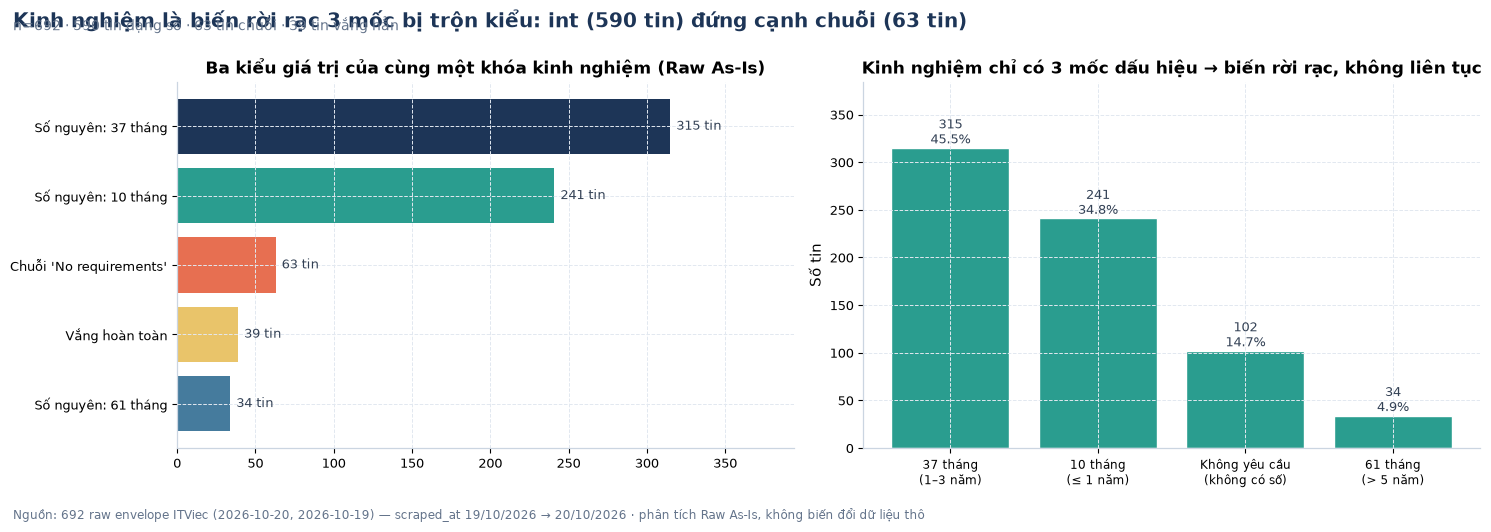

In [13]:
print("── 3.4 Kiểu dữ liệu trộn: kinh nghiệm & rating ──")
er_base = df["job_posting_jsonld.experienceRequirements"]
er_months = df["job_posting_jsonld.experienceRequirements.monthsOfExperience"]
print("   Giá trị thật của khóa monthsOfExperience:",
      Counter(f"{type(v).__name__}:{v}" for v in er_months).most_common(8))
print("   Khóa cha experienceRequirements khi không phải dict:",
      Counter(str(v)[:26] for v in er_base if isinstance(v, str)).most_common(4))
mer_num = pd.to_numeric(er_months, errors="coerce")
print(f"\n   monthsOfExperience parse được số: {int(mer_num.notna().sum())}/{len(df)} "
      f"· 'No requirements' dạng chuỗi: {int(er_base.map(lambda v: isinstance(v, str)).sum())} tin "
      f"· vắng hẳn khối: {int(er_months.isna().sum() - er_base.map(lambda v: isinstance(v, str)).sum())} tin")
print("   => Chỉ 3 mốc tháng (10 / 37 / 61) ⇒ biến này RÚT GỌN về phân loại 4 lớp, không phải biến liên tục.")

rate_raw = df["company_details.rating"]
rate = pd.to_numeric(rate_raw, errors="coerce")
print(f"\n   company_details.rating: dtype gốc = {rate_raw.dtype}, giá trị lưu dạng chuỗi "
      f"(\"{str(rate_raw.dropna().iloc[0])}\"), parse được {int(rate.notna().sum())}/{len(df)}, "
      f"dải [{rate.min():.1f} – {rate.max():.1f}], trung vị {rate.median():.2f}")
scale_raw = df["company_details.Quy mô công ty"]
print(f"   Quy mô công ty mang ký tự xuống dòng: "
      f"{int(scale_raw.map(lambda v: isinstance(v, str) and chr(10) in v).sum())}/{len(df)} tin "
      f"(ví dụ: \"{str(scale_raw.dropna().iloc[0]).replace(chr(10), chr(92)+'n')}\")")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
def exp_value_kind(v_base, v_months):
    if isinstance(v_base, str):
        return "Chuỗi 'No requirements'"
    if v_months is None or (isinstance(v_months, float) and pd.isna(v_months)):
        return "Vắng hoàn toàn"
    return f"Số nguyên: {int(v_months)} tháng"


kind_series = pd.Series([exp_value_kind(b, m) for b, m in zip(er_base, er_months)], index=df.index)
kt = kind_series.value_counts()
axes[0].barh(range(len(kt)), kt.values, color=PALETTE[:len(kt)])
axes[0].set_yticks(range(len(kt))), axes[0].set_yticklabels(kt.index, fontsize=9.5)
label_bars(axes[0], kt.values, fmt="{:.0f} tin")
axes[0].set_xlim(0, kt.max() * 1.25)
axes[0].set_title("Ba kiểu giá trị của cùng một khóa kinh nghiệm (Raw As-Is)")
axes[0].invert_yaxis()

bucket_lab = mer_num.map(lambda v: "Không yêu cầu\n(không có số)" if pd.isna(v) else
                         ("10 tháng\n(≤ 1 năm)" if v <= 12 else ("37 tháng\n(1–3 năm)" if v <= 48 else "61 tháng\n(> 5 năm)")))
vc_b = bucket_lab.value_counts().rename_axis("Mốc kinh nghiệm").reset_index(name="Số tin")
axes[1].bar(vc_b["Mốc kinh nghiệm"], vc_b["Số tin"], color=PALETTE[1], edgecolor="white")
for i, v in enumerate(vc_b["Số tin"]):
    axes[1].text(i, v + max(vc_b["Số tin"]) * .015, f"{v}\n{v/len(df)*100:.1f}%", ha="center", fontsize=9, color="#334155")
axes[1].set_ylabel("Số tin"), axes[1].tick_params(axis="x", labelsize=8.5)
axes[1].set_ylim(0, max(vc_b["Số tin"]) * 1.22)
axes[1].set_title("Kinh nghiệm chỉ có 3 mốc dấu hiệu → biến rời rạc, không liên tục")
finalize(fig, "Kinh nghiệm là biến rời rạc 3 mốc bị trộn kiểu: int (590 tin) đứng cạnh chuỗi (63 tin)",
         f"n={len(df)} · {int(mer_num.notna().sum())} tin dạng số · "
         f"{int(er_base.map(lambda v: isinstance(v, str)).sum())} tin chuỗi · {int(mer_num.isna().sum() - er_base.map(lambda v: isinstance(v, str)).sum())} tin vắng hẳn", 
         "11_experience_distribution.png")

── 3.5 Ngày tháng: tương đối (L1) vs tuyệt đối ISO (L3) ──
   posted_at_raw chứa ký tự xuống dòng 'Đăng\nN ngày trước': 634/692 tin
   Parse được N ngày/giờ: 634 tin · không khớp mẫu: 1 giá trị
      ⚠️  'Số 163 Phan Đăng Lưu , Cầu Kiệu, TP Hồ Chí Minh'

   datePosted (ISO) parse được: 653/692 · validThrough: 657/692
   Mốc 'hôm nay' của đợt cào: 20/10/2026 · tuổi tin: median 19 ngày, max 48.0 ngày
   Sai lệch giữa 'N ngày trước' (UI) và tuổi suy từ datePosted: median |Δ| = 0 ngày trên 634 tin đối chiếu được
   Tin đã quá hạn nộp (validThrough < mốc cào) mà vẫn còn trên sàn: 0 tin
🖼️  Đã lưu reports\figures\itviec\13_posted_at_relative_vs_iso.png (DPI 300)


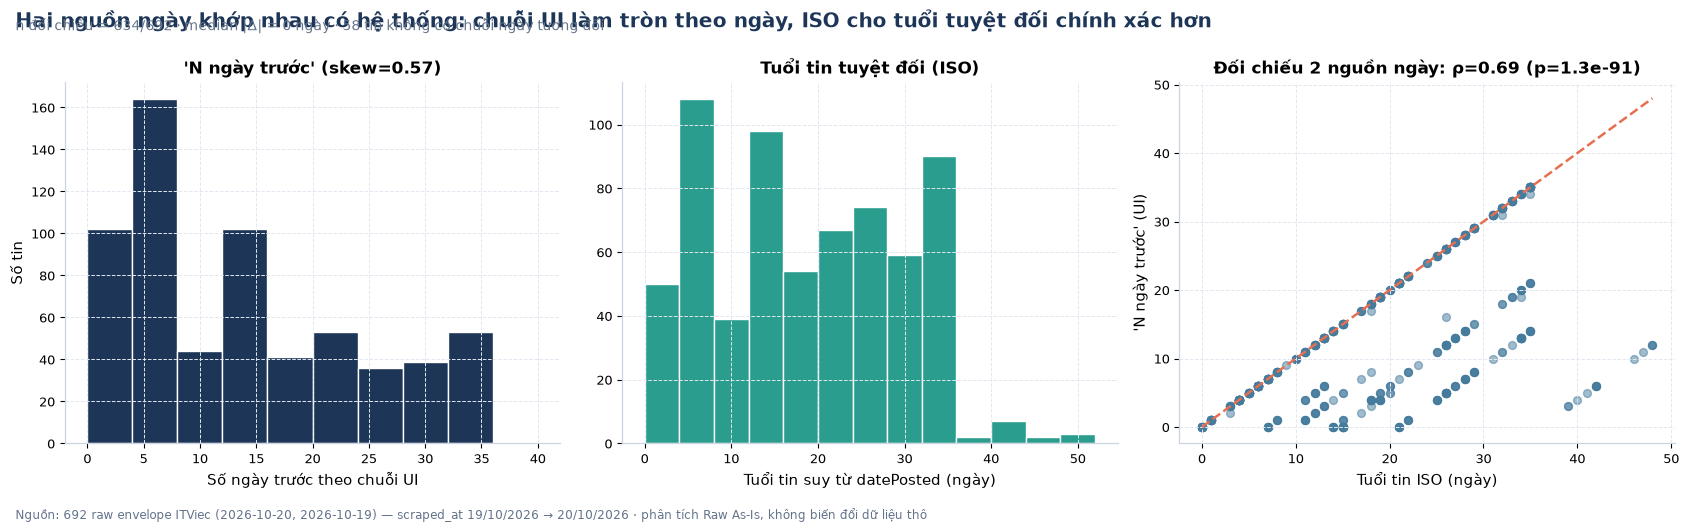

In [14]:
print("── 3.5 Ngày tháng: tương đối (L1) vs tuyệt đối ISO (L3) ──")
raw_posted = df_top["posted_at_raw"]
nl_noise = int(raw_posted.map(lambda v: isinstance(v, str) and chr(10) in v).sum())
rel_days = raw_posted.map(lambda v: (int(m.group(1)) if (m := re.search(r"(\d+)\s*ngày trước", str(v))) else
                                     (0 if re.search(r"\d+\s*giờ trước", str(v)) else np.nan)))
unparsed = [v for v in raw_posted.dropna().unique() if isinstance(v, str) and re.search(r"\d+\s*(ngày|giờ) trước", v) is None]
print(f"   posted_at_raw chứa ký tự xuống dòng 'Đăng\\nN ngày trước': {nl_noise}/{len(df)} tin")
print(f"   Parse được N ngày/giờ: {int(pd.Series(rel_days).notna().sum())} tin · không khớp mẫu: {len(unparsed)} giá trị")
for v in unparsed[:5]:
    print(f"      ⚠️  '{v[:70]}'")

posted_iso = pd.to_datetime(df["job_posting_jsonld.datePosted"], errors="coerce")
valid_iso = pd.to_datetime(df["job_posting_jsonld.validThrough"], errors="coerce")
crawled = pd.to_datetime(df_meta["m_scraped_at"], errors="coerce", utc=True).dt.tz_convert("Asia/Bangkok").dt.tz_localize(None)
REF_TODAY = crawled.max().normalize()
age_days = (REF_TODAY - posted_iso.dt.normalize()).dt.days
days_to_valid = (valid_iso.dt.normalize() - REF_TODAY).dt.days
rel = pd.Series(rel_days, index=df.index)
both_d = pd.DataFrame({"rel": rel, "iso_age": age_days}).dropna()
mad = float((both_d["rel"] - both_d["iso_age"]).abs().median())
print(f"\n   datePosted (ISO) parse được: {int(posted_iso.notna().sum())}/{len(df)} · "
      f"validThrough: {int(valid_iso.notna().sum())}/{len(df)}")
print(f"   Mốc 'hôm nay' của đợt cào: {REF_TODAY:%d/%m/%Y} · tuổi tin: median {age_days.median():.0f} ngày, max {age_days.max()} ngày")
print(f"   Sai lệch giữa 'N ngày trước' (UI) và tuổi suy từ datePosted: median |Δ| = {mad:.0f} ngày trên {len(both_d)} tin đối chiếu được")
print(f"   Tin đã quá hạn nộp (validThrough < mốc cào) mà vẫn còn trên sàn: {int((days_to_valid < 0).sum())} tin")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
rvc = rel.dropna()
axes[0].hist(rvc, bins=np.arange(0, max(rvc.max(), 1) + 8, 4), color=PALETTE[0], edgecolor="white")
axes[0].set_xlabel("Số ngày trước theo chuỗi UI"), axes[0].set_ylabel("Số tin")
axes[0].set_title(f"'N ngày trước' (skew={rvc.skew():.2f})")
axes[1].hist(age_days.dropna(), bins=np.arange(0, 56, 4), color=PALETTE[1], edgecolor="white")
axes[1].set_xlabel("Tuổi tin suy từ datePosted (ngày)"), axes[1].set_title("Tuổi tin tuyệt đối (ISO)")
axes[2].scatter(both_d["iso_age"], both_d["rel"], alpha=.5, s=32, color=PALETTE[4])
lim = max(both_d.max().max(), 1)
axes[2].plot([0, lim], [0, lim], ls="--", color=C_WARN, lw=1.8)
axes[2].set_xlabel("Tuổi tin ISO (ngày)"), axes[2].set_ylabel("'N ngày trước' (UI)")
rho = stats.spearmanr(both_d["iso_age"], both_d["rel"])
axes[2].set_title(f"Đối chiếu 2 nguồn ngày: ρ={rho.statistic:.2f} (p={rho.pvalue:.1e})")
finalize(fig, "Hai nguồn ngày khớp nhau có hệ thống: chuỗi UI làm tròn theo ngày, ISO cho tuổi tuyệt đối chính xác hơn",
         f"n đối chiếu = {len(both_d)}/{len(df)} · median |Δ| = {mad:.0f} ngày · "
         f"{int(rel.isna().sum())} tin không có chuỗi ngày tương đối",
         "13_posted_at_relative_vs_iso.png")

── 3.6 Nhiễu văn bản: HTML, \r, bullet và sự phân kỳ giữa UI ↔ JSON-LD ──
⚠️  653 tin có HTML nguyên khối trong description (trung vị 112 thẻ/tin, max 474).

⚠️  Tiêu đề khác nhau giữa UI và JSON-LD: 489/657 tin có JSON-LD (74.4%) — JSON-LD cắt ngoặc [HCM]/(Remote) và bỏ dấu tiếng Việt.
🖼️  Đã lưu reports\figures\itviec\12_jd_text_length.png (DPI 300)


,desc_html_tags,desc_words,desc_cr,benefits_html_tags,n_bullets,n_sections
count,692.00,692.00,692.00,692.00,692.00,692.00
mean,120.12,557.05,8.07,31.60,49.31,3.78
std,64.77,273.61,2.13,21.79,21.82,0.52
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,78.00,385.00,7.00,16.00,35.00,4.00
50%,112.00,528.50,9.00,26.00,46.00,4.00
75%,156.00,708.25,9.00,42.00,61.00,4.00
max,474.00,1619.00,9.00,112.00,162.00,4.00


,title (UI),title (JSON-LD)
0,AI Engineer (Remote),AI Engineer Remote
1,"AI Operations Manager (from 5yoe, Excellent English)","AI Operations Manager from 5yoe, Excellent English"
2,Business Analyst Intern (Company Secretariat),Business Analyst Intern Company Secretariat
4,"CV, CVCC Xây Dựng Mô Hình Phát Hiện Gian Lận","CV, CVCC Xay Dung Mo Hinh Phat Hien Gian Lan"
5,"FinTech Frontend Dev (JavaScript, React)","FinTech Frontend Dev JavaScript, React"


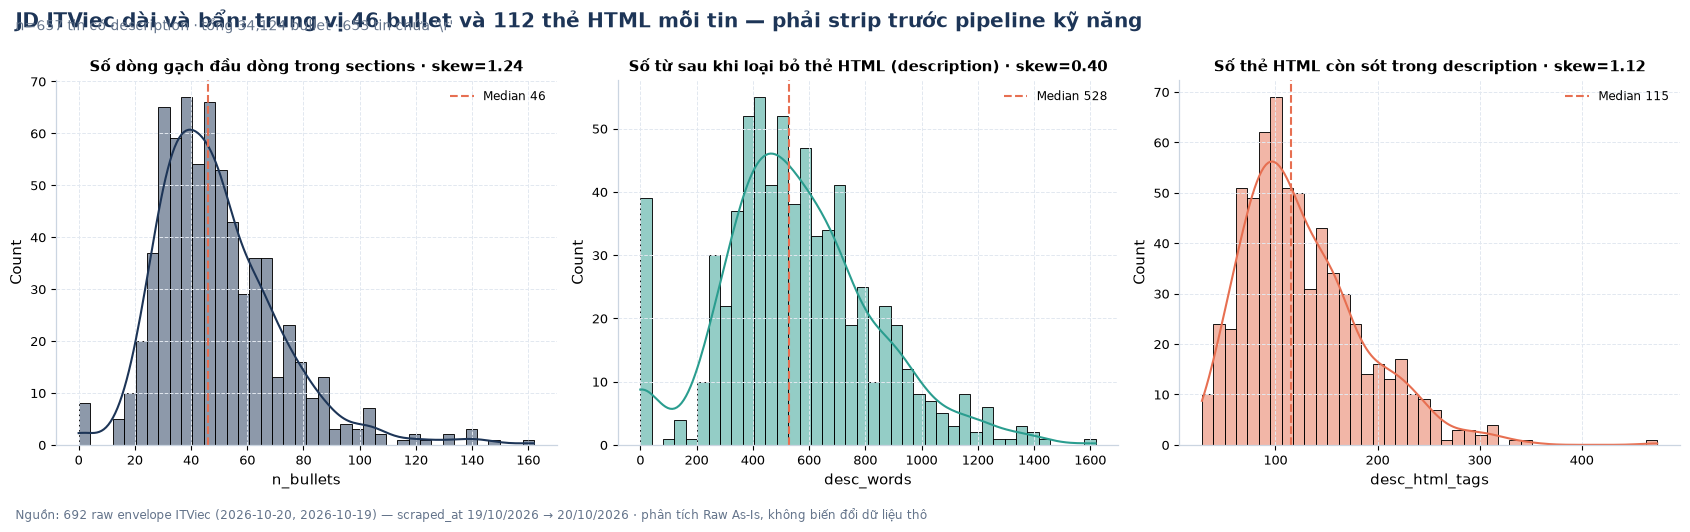

In [15]:
print("── 3.6 Nhiễu văn bản: HTML, \\r, bullet và sự phân kỳ giữa UI ↔ JSON-LD ──")
desc = df["job_posting_jsonld.description"].fillna("")
ben = df["job_posting_jsonld.jobBenefits"].fillna("")
noise = pd.DataFrame({
    "desc_html_tags": desc.map(lambda s: len(re.findall(r"<[^>]+>", s))),
    "desc_words": desc.map(lambda s: len(re.sub(r"<[^>]+>", " ", s).split())),
    "desc_cr": desc.map(lambda s: s.count(chr(13))),
    "benefits_html_tags": ben.map(lambda s: len(re.findall(r"<[^>]+>", s))),
    "n_bullets": sec_bullets,
    "n_sections": sec_n,
})
show(noise.describe().round(2))
print(f"⚠️  {int((noise['desc_html_tags'] > 0).sum())} tin có HTML nguyên khối trong description "
      f"(trung vị {noise['desc_html_tags'].median():.0f} thẻ/tin, max {noise['desc_html_tags'].max()}).")

ui_t = df_top["title"].astype("string").fillna("").str.strip().str.lower()
ld_t = df["job_posting_jsonld.title"].astype("string").fillna("").str.strip().str.lower()
diff_title = int((ld_t.ne("") & ui_t.ne(ld_t)).sum())
ld_present = int((ld_t != "").sum())
ex = pd.DataFrame({"title (UI)": df_top["title"], "title (JSON-LD)": df["job_posting_jsonld.title"]})
ex = ex[ex["title (JSON-LD)"].notna() & (ex["title (UI)"].astype(str).str.strip().str.lower() != ex["title (JSON-LD)"].astype(str).str.strip().str.lower())]
print(f"\n⚠️  Tiêu đề khác nhau giữa UI và JSON-LD: {diff_title}/{ld_present} tin có JSON-LD "
      f"({diff_title/max(ld_present,1)*100:.1f}%) — JSON-LD cắt ngoặc [HCM]/(Remote) và bỏ dấu tiếng Việt.")
show(ex.head(5))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, col, ttl, pal in [(axes[0], "n_bullets", "Số dòng gạch đầu dòng trong sections", PALETTE[0]),
                          (axes[1], "desc_words", "Số từ sau khi loại bỏ thẻ HTML (description)", PALETTE[1]),
                          (axes[2], "desc_html_tags", "Số thẻ HTML còn sót trong description", PALETTE[2])]:
    v = noise[col]
    v = v[v > 0] if col == "desc_html_tags" else v
    sns.histplot(v, bins=40, kde=True, color=pal, ax=ax)
    ax.set_title(f"{ttl} · skew={v.skew():.2f}", fontsize=11)
    ax.axvline(v.median(), color=C_WARN, ls="--", label=f"Median {v.median():.0f}")
    ax.legend(fontsize=8.5)
finalize(fig, "JD ITViec dài và bẩn: trung vị 46 bullet và 112 thẻ HTML mỗi tin — phải strip trước pipeline kỹ năng",
         f"n={int((noise['desc_words'] > 0).sum())} tin có description · tổng {int(noise['n_bullets'].sum()):,} bullet · "
         f"{int((noise['desc_cr'] > 0).sum())} tin chứa '\\r'",
         "12_jd_text_length.png")

## Bước 4 — Trụ cột 3: Tính duy nhất (Uniqueness & Duplication)

| Tầng | Cách đo | Ý nghĩa & hành động |
|:---|:---|:---|
| **Trùng khóa định danh** | `m_job_id`, `m_source_url` | Trùng do quét lặp phân trang ⇒ giữ bản ghi mới nhất, đưa bản dư vào `quarantine`. |
| **Trùng nội dung tuyệt đối** | `m_canonical_hash` (thế hệ mới) / `m_content_hash` | Repost của cùng nhà tuyển dụng ⇒ tín hiệu "tin nóng", không phải lỗi. |
| **Trùng logic nghiệp vụ** | `company_name + title + tỉnh` | Hai tin khác ID nhưng cùng vị trí ⇒ cần entity resolution bằng embedding ở bước Integration. |

Hai thế hệ schema băm khiến `canonical_hash` không so sánh được xuyên phân vùng ⇒ phải dùng `content_hash`
làm khóa nối chung.

In [16]:
def _hash_key(v):
    """Biến MỌI giá trị không hash được thành chuỗi JSON để so trùng được cả cột mảng.

    `value_counts()` và `duplicated()` yêu cầu từng ô phải hash được; payload thô ITViec chứa list/dict
    (`skill_tags`, JSON-LD, `sections`) và đôi khi cả np.ndarray/set, nếu đưa thẳng vào thì pandas raise
    `TypeError: unhashable type: 'list'`. Giá trị vô hướng giữ nguyên để không làm đổi nghĩa phép so sánh.
    Đây là diễn giải ĐỂ ĐO, không ghi ngược lên đĩa.
    """
    if isinstance(v, np.ndarray):
        v = v.tolist()
    if isinstance(v, (set, frozenset)):
        v = sorted(map(str, v))
    if isinstance(v, (list, dict, tuple)):
        return json.dumps(v, ensure_ascii=False, sort_keys=True, default=str)
    return v


def dup_report(name, series, note_ok=True):
    """Đo số bản ghi dư theo một tập khóa; giá trị null được làm cho unique để không bị tính là trùng."""
    s = series.astype(object)
    s = s.where(s.notna(), other=pd.Series([f"<NULL::{i}>" for i in s.index], index=s.index))
    s = s.map(_hash_key)
    vc = s.value_counts()
    groups = vc[vc > 1]
    return {"Tiêu chí": name, "Số bản ghi dư": int((groups - 1).sum()),
            "Tỷ lệ (%)": round((groups - 1).sum() / len(df) * 100, 2),
            "Số cụm trùng": len(groups),
            "Nhóm lặp nhiều nhất": str(groups.index[0])[:60] if len(groups) else "—"}


def _cell_key(v):
    """Biến một ô thô (kể cả list/dict/ndarray/set/NaN) thành khóa chuỗi ổn định để so trùng cả payload."""
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return ""
    return str(_hash_key(v))


dup_rows = [
    dup_report("Khóa job_id", df_meta["m_job_id"]),
    dup_report("Khóa source_url", df_meta["m_source_url"]),
    dup_report("canonical_hash (CDC thế hệ mới)", df_meta["m_canonical_hash"]),
    dup_report("content_hash (toàn payload)", df_meta["m_content_hash"]),
    dup_report("Trùng tiêu đề", df_top["title"]),
    dup_report("Logic: công ty + tiêu đề", df_top["company_name"].astype(str) + " || " + df_top["title"].astype(str)),
    dup_report("Y hệt 100% payload (14 cột thô)", df_top.apply(lambda r: "||".join(map(_cell_key, r)), axis=1)),
]
show(pd.DataFrame(dup_rows))

prov = df_top.assign(province=df_top["work_location"].map(
    lambda v: str(v).split(",")[-1].strip() if isinstance(v, str) else np.nan))
logical = prov.groupby(["company_name", "title", "province"], dropna=False).size().sort_values(ascending=False)
print(f"\n🔁 Công ty đăng cùng tiêu đề + cùng tỉnh: {(logical > 1).sum()} cụm, tổng {int(logical[logical > 1].sum())} tin")
show(logical[logical > 1].rename("Số tin").reset_index().head(8))

same_url_diff_hash = df_meta.groupby("m_source_url")["m_content_hash"].nunique()
print(f"\n⚠️ Cùng URL nhưng khác content_hash: {int((same_url_diff_hash > 1).sum())} URL — "
      f"bằng chứng crawler nạp lại tin và sinh hai phiên bản trong CÙNG một phân vùng ngày.")
hash_field = df_meta.filter(like="m_field_hashes.")
print(f"\n🧬 Độ phủ băm theo từng trường nghiệp vụ (chỉ thế hệ schema mới): "
      f"{int(hash_field.notna().all(axis=1).sum())}/{len(df)} bản ghi có đủ {hash_field.shape[1]} field hash")
show(pd.DataFrame({
    "Trường": [c.replace("m_field_hashes.", "") for c in hash_field.columns],
    "Bản ghi có hash": [int(hash_field[c].notna().sum()) for c in hash_field.columns],
    "Số phiên bản hash": [int(hash_field[c].nunique()) for c in hash_field.columns],
}))

,Tiêu chí,Số bản ghi dư,Tỷ lệ (%),Số cụm trùng,Nhóm lặp nhiều nhất
0,Khóa job_id,1,0.14,1,ai-engineer-python-ai-apis-llms-forix-4550
1,Khóa source_url,1,0.14,1,https://itviec.com/viec-lam-it/ai-engineer-python-a...
2,canonical_hash (CDC thế hệ mới),0,0.00,0,—
3,content_hash (toàn payload),0,0.00,0,—
4,Trùng tiêu đề,28,4.05,19,Senior DevOps Engineer
5,Logic: công ty + tiêu đề,7,1.01,7,Bosch Global Software Technologies Company Limited ...
6,Y hệt 100% payload (14 cột thô),3,0.43,1,||||||||[]||||{}||||||||||||||



🔁 Công ty đăng cùng tiêu đề + cùng tỉnh: 7 cụm, tổng 16 tin

⚠️ Cùng URL nhưng khác content_hash: 1 URL — bằng chứng crawler nạp lại tin và sinh hai phiên bản trong CÙNG một phân vùng ngày.

🧬 Độ phủ băm theo từng trường nghiệp vụ (chỉ thế hệ schema mới): 666/692 bản ghi có đủ 14 field hash


,company_name,title,province,Số tin
0,NaN,NaN,NaN,4
1,ITviec Recruitment Consulting,Bridge System Engineer (Japanese N1/N2),TP Hồ Chí Minh,2
2,Bosch Global Software Technologies Company Limited,AI Engineer,TP Hồ Chí Minh,2
3,MB Bank,Data Quality Management Specialist - Data Division,Hà Nội,2
4,MB Bank,Senior Business Model Validation Analyst (BI),Hà Nội,2
5,MB Bank,Senior Data Security - Data Division,Hà Nội,2
6,Rakus Vietnam Company,"Senior Java Software Engineer (Fullstack, SaaS prod...",TP Hồ Chí Minh,2


,Trường,Bản ghi có hash,Số phiên bản hash
0,title,670,644
1,company_name,670,317
2,company_url,670,317
3,salary_display_text,670,98
4,salary_range_datalayer,670,130
5,work_location,666,345
6,work_model,666,3
7,posted_at_raw,666,47
8,skill_tags,670,661
9,specialization,666,68


### 4.2 Bản ghi rác: fixture kiểm thử và trang danh mục bị cào nhầm

Ngoài trùng lặp, kho Raw còn nhiễm hai loại bản ghi **không phải tin tuyển dụng thật**, phát hiện bằng
luật hành vi (không dùng danh sách ID cứng):

| Lớp | Luật nhận biết | Bản chất |
|:---|:---|:---|
| **Fixture test** | `title` khớp mẫu `^Jjob-` và *có* tiêu đề nhưng **không có** `company_name` | Dữ liệu mẫu của unit-test crawler (`Jjob-mot-100` → `Jjob-bon-400`, `baseSalary` = 1–2 mang nhãn `VND`, JD chỉ 1 mục `Mô tả`, `skill_tags = ["Py"]`) lọt vào thư mục output |
| **Trang bị cào nhầm / scrape trả về trang trống** | `title` trắng **và** `company_name` khuyết **và** `sections = {}` | Ba URL là trang danh mục công nghệ (`/viec-lam-it/css-3`, `/iso-27001`, `/microsoft-dynamics-365`) bị URL discovery nhận nhầm là job; một URL job thật (`frontend-developer-sqreem-...-2959`) bị cào lúc trang chưa render kịp |

Đây là **lỗi pipeline ở tầng thu thập**, không phải khiếm khuyết của nguồn; nếu không tách ra, chúng làm sai
mọi chỉ số lương/phân phối ở Bước 5. Phân vùng ngày của chúng cũng là một tín hiệu: phần lớn nằm ở ca cào cũ,
tức là ca chạy thử nghiệm của crawler.

In [17]:
print("\n── 4.2 Quét bản ghi rác: fixture test & trang danh mục bị cào nhầm ──")
blank_title = df_top["title"].isna() | df_top["title"].astype("string").str.strip().eq("")
jjob_like = df_top["title"].astype("string").str.match(r"^Jjob-", na=False).fillna(False) & df_top["company_name"].isna()
empty_env = blank_title.fillna(True) & df_top["company_name"].isna() & sec_n.eq(0)
is_test_record = jjob_like | empty_env
n_test = int(is_test_record.sum())
print(f"   • Fixture mang nhãn kiểm thử (`Jjob-*`): {int(jjob_like.sum())} tin")
print(f"   • Envelope rỗng hoàn toàn (title/JD/skill/JSON-LD đều trắng): {int(empty_env.sum())} tin")
print(f"   ⇒ Tổng {n_test}/{len(df)} tin ({n_test/len(df)*100:.2f}%); phân vùng chứa: "
      f"{df.loc[is_test_record, '_partition'].value_counts().to_dict()}")
show(pd.DataFrame({
    "job_id": df_meta.loc[is_test_record, "m_job_id"],
    "lớp": np.where(jjob_like[is_test_record], "fixture", "envelope rỗng"),
    "title": df_top.loc[is_test_record, "title"].fillna("<trống>"),
    "company_name": df_top.loc[is_test_record, "company_name"].fillna("<khuyết>"),
    "thẻ skill": sk_len[is_test_record],
    "mục JD": sec_n[is_test_record],
    "baseSalary.min": df.loc[is_test_record, "job_posting_jsonld.baseSalary.value.minValue"].fillna("<khuyết>"),
    "tiền tệ": df.loc[is_test_record, "job_posting_jsonld.baseSalary.currency"].fillna("<khuyết>"),
    "URL": df_meta.loc[is_test_record, "m_source_url"].str.replace("https://itviec.com", "", regex=False),
}))
print(f"   ⇒ {int(jjob_like.sum())} fixture giải thích toàn bộ ngoại lệ 'lương 1–2 VND', 'JD chỉ 1 mục Mô tả', "
      f"'skill_tags = [Py]' ở Bước 2–3; {int(empty_env.sum())} envelope rỗng giải thích các tin có 0 thẻ kỹ năng "
      f"và 0 mục JD. Cách ly bằng cờ `is_test_record`, không đưa vào bất kỳ phép thống kê nào ở tầng Curated.")


── 4.2 Quét bản ghi rác: fixture test & trang danh mục bị cào nhầm ──
   • Fixture mang nhãn kiểm thử (`Jjob-*`): 4 tin
   • Envelope rỗng hoàn toàn (title/JD/skill/JSON-LD đều trắng): 4 tin
   ⇒ Tổng 8/692 tin (1.16%); phân vùng chứa: {'2026-10-19': 7, '2026-10-20': 1}
   ⇒ 4 fixture giải thích toàn bộ ngoại lệ 'lương 1–2 VND', 'JD chỉ 1 mục Mô tả', 'skill_tags = [Py]' ở Bước 2–3; 4 envelope rỗng giải thích các tin có 0 thẻ kỹ năng và 0 mục JD. Cách ly bằng cờ `is_test_record`, không đưa vào bất kỳ phép thống kê nào ở tầng Curated.


,job_id,lớp,title,company_name,thẻ skill,mục JD,baseSalary.min,tiền tệ,URL
3,css-3,envelope rỗng,<trống>,<khuyết>,0,0,<khuyết>,<khuyết>,/viec-lam-it/css-3
9,iso-27001,envelope rỗng,<trống>,<khuyết>,0,0,<khuyết>,<khuyết>,/viec-lam-it/iso-27001
10,job-ba-300,fixture,Jjob-ba-300,<khuyết>,1,1,1.0,VND,/viec-lam-it/job-ba-300
11,job-bon-400,fixture,Jjob-bon-400,<khuyết>,1,1,1.0,VND,/viec-lam-it/job-bon-400
12,job-hai-200,fixture,Jjob-hai-200,<khuyết>,1,1,1.0,VND,/viec-lam-it/job-hai-200
13,job-mot-100,fixture,Jjob-mot-100,<khuyết>,1,1,1.0,VND,/viec-lam-it/job-mot-100
14,microsoft-dynamics-365,envelope rỗng,<trống>,<khuyết>,0,0,<khuyết>,<khuyết>,/viec-lam-it/microsoft-dynamics-365
228,frontend-developer-sqreem-technologies-vn-pte-ltd-2959,envelope rỗng,<trống>,<khuyết>,0,0,<khuyết>,<khuyết>,/viec-lam-it/frontend-developer-sqreem-technologies...


## Bước 5 — Trụ cột 4: Hình thái phân phối & ngoại lai (phân tích đơn biến chuyên sâu)

Toàn bộ đặc trưng định lượng dưới đây được **dẫn xuất từ chuỗi thô** và chứa trong `feat`
(không cộng vào `df`, không ghi file — giữ đúng quy tắc *Raw As-Is*). ITViec có ba dẫn xuất phải tự xây
vì nguồn **không** cấp sẵn: (a) lương số học gộp ba tầng, (b) cấp bậc suy từ tiêu đề, (c) quy mô công ty
suy từ chuỗi `"1-50\nnhân viên"`.

In [18]:
def seniority_from_title(t):
    """Thang cấp bậc suy từ chuỗi tiêu đề thô (nguồn ITViec không có trường 'Cấp bậc')."""
    if not isinstance(t, str) or not t.strip():
        return "Tiêu đề trống"
    low = t.lower()
    if re.search(r"intern|fresher|thực tập|mới tốt nghiệp|graduate trainee|sinh viên mới", low):
        return "Thực tập sinh / Intern"
    if re.search(r"director|head of|giám đốc|quản lý|manager|trưởng phòng|\blead\b|principal", low):
        return "Quản lý / Lead"
    if re.search(r"senior|\bsr\b|experte?d|\b5\+|\b8\+|\b10\+", low):
        return "Senior"
    if re.search(r"\bjunior\b|\bmiddle\b|\bmid\b|\b2\+|\b3\+", low):
        return "Junior / Middle"
    return "Không nêu cấp bậc"


def scale_mid(s):
    """"1000+\nnhân viên" → 1500; "51-150\nnhân viên" → 100 (trung điểm dải, dẫn xuất phục vụ EDA)."""
    if not isinstance(s, str):
        return np.nan
    t = s.replace("\n", " ").strip()
    if "+" in t:
        m = re.match(r"(\d[\d.,]*)\s*\+", t)
        return float(m.group(1).replace(".", "").replace(",", "")) * 1.5 if m else np.nan
    m = re.findall(r"\d+", t)
    return (int(m[0]) + int(m[1])) / 2 if len(m) >= 2 else np.nan


def skills_split(v):
    """skill_tags là list[str] nhưng một phần tử có thể chứa nhiều kỹ năng ngăn bằng dấu ','."""
    if not isinstance(v, list):
        return []
    out = []
    for t in v:
        out += [x.strip().lower() for x in str(t).split(",") if x.strip()]
    return out


skills_series = df_top["skill_tags"].map(skills_split)
province_ld = df["job_posting_jsonld.jobLocation"].map(
    lambda v: [((p or {}).get("address") or {}).get("addressRegion") for p in v if isinstance(p, dict)] if isinstance(v, list) else [])
province_ui = df_top["work_location"].map(lambda v: str(v).split(",")[-1].strip() if isinstance(v, str) else np.nan)

feat = pd.DataFrame(index=df.index)
for tag in ["ui", "dl", "ld"]:
    feat[f"sal_min_{tag}"] = SAL[tag]["min"]
    feat[f"sal_max_{tag}"] = SAL[tag]["max"]
feat["currency"] = merged_cur
# Biến lương PHẢI tách theo tiền tệ: một cột gộp chung hai đồng tiền không có thang đo nào để đọc.
for tag, cur_label, unit in CUR_GROUPS:
    _m = merged_cur.eq(cur_label)
    feat[f"sal_min_{tag}"] = merged_min.where(_m)
    feat[f"sal_max_{tag}"] = merged_max.where(_m)
    feat[f"sal_mid_{tag}"] = feat[[f"sal_min_{tag}", f"sal_max_{tag}"]].mean(axis=1)
    feat[f"sal_width_{tag}"] = feat[f"sal_max_{tag}"] - feat[f"sal_min_{tag}"]
feat["salary_hidden"] = (merged_max.isna()).astype(int)
feat["salary_layer_used"] = layer_used
feat["salary_is_usd_text"] = df_top["salary_range_datalayer"].map(
    lambda v: isinstance(v, str) and ("usd" in v.lower() or "$" in v)).astype(int)
feat["exp_months"], feat["exp_years"] = mer_num, mer_num / 12
feat["n_skill_elems"] = sk_len
feat["n_skills"] = skills_series.map(len)
feat["n_skills_unique"] = skills_series.map(lambda l: len(set(l)))
feat["has_multivalue_tag"] = df_top["skill_tags"].map(
    lambda v: isinstance(v, list) and any("," in str(t) for t in v)).astype(int)
feat["n_sections"] = sec_n
feat["n_bullets"] = sec_bullets
feat["desc_words"] = noise["desc_words"]
feat["desc_chars"] = desc.map(len)
feat["desc_html_tags"] = noise["desc_html_tags"]
feat["benefits_html_tags"] = noise["benefits_html_tags"]
feat["title_chars"] = df_top["title"].map(lambda v: len(v) if isinstance(v, str) else np.nan)
feat["company_rating"] = rate
feat["company_scale_mid"] = df["company_details.Quy mô công ty"].map(scale_mid)
comp_vc = df_top["company_name"].value_counts()
feat["n_jobs_same_company"] = df_top["company_name"].map(comp_vc).fillna(0)
feat["n_work_locations"] = province_ld.map(len)
feat["age_days"] = age_days
feat["days_to_valid"] = days_to_valid
feat["posted_rel_days"] = rel
feat["env_kb"] = df["_bytes"] / 1024
feat["is_dead_listing"] = (df_meta["m_http_status"] == 410).astype(int)

show(feat.head(8))
print(f"\n✅ Đã dẫn xuất {feat.shape[1]} đặc trưng đơn biến từ payload thô (không ghi đè dữ liệu gốc).")

,sal_min_ui,sal_max_ui,sal_min_dl,sal_max_dl,sal_min_ld,sal_max_ld,currency,sal_min_vnd,sal_max_vnd,sal_mid_vnd,sal_width_vnd,sal_min_usd,sal_max_usd,sal_mid_usd,sal_width_usd,salary_hidden,salary_layer_used,salary_is_usd_text,exp_months,exp_years,n_skill_elems,n_skills,n_skills_unique,has_multivalue_tag,n_sections,n_bullets,desc_words,desc_chars,desc_html_tags,benefits_html_tags,title_chars,company_rating,company_scale_mid,n_jobs_same_company,n_work_locations,age_days,days_to_valid,posted_rel_days,env_kb,is_dead_listing
0,NaN,NaN,NaN,NaN,1000.0,1300.0,USD,NaN,NaN,NaN,NaN,1000.0,1300.0,1150.0,300.0,0,L3 JSON-LD,0,10.0,0.833333,1,2,2,1,4,29,342,2546,39,6,20.0,NaN,NaN,1.0,2,21.0,14.0,NaN,8.829102,0
1,NaN,NaN,NaN,NaN,3400.0,4500.0,USD,NaN,NaN,NaN,NaN,3400.0,4500.0,3950.0,1100.0,0,L3 JSON-LD,0,61.0,5.083333,1,6,6,1,4,79,1165,9679,202,24,52.0,NaN,NaN,3.0,1,20.0,15.0,NaN,22.323242,0
2,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Không định lượng được,0,NaN,NaN,1,7,7,1,4,16,156,2054,50,10,45.0,NaN,NaN,5.0,1,6.0,29.0,NaN,7.042969,0
3,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Không định lượng được,0,NaN,NaN,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,0.0,0,NaN,NaN,NaN,0.690430,0
4,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Không định lượng được,0,10.0,0.833333,1,6,6,1,4,52,793,5444,173,41,44.0,NaN,NaN,25.0,1,11.0,24.0,NaN,16.412109,0
5,NaN,NaN,NaN,NaN,1500.0,3000.0,USD,NaN,NaN,NaN,NaN,1500.0,3000.0,2250.0,1500.0,0,L3 JSON-LD,0,10.0,0.833333,1,3,3,1,4,28,326,2329,37,14,40.0,NaN,NaN,1.0,1,1.0,34.0,NaN,8.173828,0
6,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Không định lượng được,0,37.0,3.083333,1,4,4,1,4,45,539,4616,104,24,43.0,NaN,NaN,3.0,1,6.0,29.0,NaN,12.833008,0
7,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Không định lượng được,0,61.0,5.083333,1,3,3,1,4,59,609,7170,203,43,36.0,NaN,NaN,10.0,1,4.0,31.0,NaN,16.432617,0



✅ Đã dẫn xuất 40 đặc trưng đơn biến từ payload thô (không ghi đè dữ liệu gốc).


In [19]:
def univariate_profile(frame: pd.DataFrame, cols=None) -> pd.DataFrame:
    """Báo cáo đơn biến đầy đủ: dung lượng mẫu, tập trung, phân tán, hình thái, ngoại lai, kiểm định chuẩn."""
    cols = cols or list(frame.columns)
    rows, n = [], len(frame)
    for c in cols:
        s = pd.to_numeric(frame[c], errors="coerce").dropna()
        if s.empty:
            rows.append({"Biến": c, "n": 0, "Thiếu (%)": 100.0})
            continue
        q1, q3 = s.quantile([.25, .75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        out_iqr = s[(s < lo) | (s > hi)]
        z_out = s[np.abs(stats.zscore(s)) > 3] if s.std() > 0 else s.iloc[:0]
        try:
            p_norm = float(stats.normaltest(s).pvalue) if len(s) >= 8 else np.nan
        except Exception:
            p_norm = np.nan
        rows.append({
            "Biến": c, "n": len(s), "Thiếu (%)": round((n - len(s)) / n * 100, 1),
            "Trung bình": round(s.mean(), 2), "Độ lệch chuẩn": round(s.std(), 2),
            "CV": round(s.std() / s.mean(), 2) if s.mean() else np.nan,
            "Min": round(s.min(), 2), "P1": round(s.quantile(.01), 2), "P25": round(q1, 2),
            "Trung vị": round(s.median(), 2), "P75": round(q3, 2), "P95": round(s.quantile(.95), 2),
            "P99": round(s.quantile(.99), 2), "Max": round(s.max(), 2),
            "IQR": round(iqr, 2), "Skewness": round(s.skew(), 2), "Kurtosis": round(s.kurtosis(), 2),
            "Ngoại lai IQR": len(out_iqr), "Ngoại lai IQR (%)": round(len(out_iqr) / len(s) * 100, 1),
            "Ngoại lai |Z|>3": len(z_out), "p chuẩn (D'Agostino)": None if np.isnan(p_norm) else f"{p_norm:.2e}",
            "Hàng rào trên": round(hi, 2),
        })
    return pd.DataFrame(rows)


NUM_VARS = [f"{s}_{tag}" for tag, _, _ in CUR_GROUPS
            for s in ("sal_min", "sal_max", "sal_mid", "sal_width")] + [
            "exp_months", "exp_years",
            "n_skill_elems", "n_skills", "n_skills_unique", "n_sections", "n_bullets",
            "desc_words", "desc_chars", "desc_html_tags", "benefits_html_tags", "title_chars",
            "company_rating", "company_scale_mid", "n_jobs_same_company", "n_work_locations",
            "age_days", "days_to_valid", "posted_rel_days", "env_kb"]
LAYER_VARS = ["sal_min_ui", "sal_max_ui", "sal_min_dl", "sal_max_dl", "sal_min_ld", "sal_max_ld"]
uni = univariate_profile(feat, NUM_VARS)
print("── 5.1a BẢNG A — đơn biến các biến lương ghi bằng VND (Triệu VND/tháng) ──")
show(uni[uni["Biến"].str.endswith("_vnd")], limit=20)
print("\n── 5.1b BẢNG B — đơn biến các biến lương ghi bằng USD (USD/tháng) ──")
show(uni[uni["Biến"].str.endswith("_usd")], limit=20)
print("\n── 5.1c Đơn biến các biến phi tiền tệ (không phụ thuộc tỷ giá) ──")
show(uni[~uni["Biến"].str.startswith("sal_")], limit=40)
uni_non_sal = uni[~uni["Biến"].str.startswith("sal_")]

print("\n── 5.1d Vì sao cột lương theo TỪNG TẦNG (sal_*_ui/dl/ld) không được đưa vào bảng phân phối ──")
_layer_cur = {"ui": SAL["ui"]["cur"], "dl": SAL["dl"]["cur"], "ld": SAL["ld"]["cur"]}
_lay = pd.DataFrame({
    "Biến theo tầng": LAYER_VARS,
    "Tin có giá trị": [int(feat[c].notna().sum()) for c in LAYER_VARS],
    "…khai VND": [int((feat[c].notna() & _layer_cur[c.split("_")[-1]].eq("VND")).sum()) for c in LAYER_VARS],
    "…khai USD": [int((feat[c].notna() & _layer_cur[c.split("_")[-1]].eq("USD")).sum()) for c in LAYER_VARS],
})
show(_lay)
print("   ⇒ Mỗi cột tầng chứa đồng thời giá trị USD và VND — hai thang đo khác nhau nên skew/kurtosis/Tukey")
print("     tính trên nó vô nghĩa về đơn vị. Chúng chỉ dùng để đo ĐỘ PHỦ TỪNG TẦNG ở bước 3; phân phối chính")
print("     thức nằm ở 5.1a/5.1b, mỗi tiền tệ một bảng.")

print("\n── Chẩn đoán nhanh hình thái ──")
n_right = n_left = 0
for _, r in uni.iterrows():
    sk = r.get("Skewness")
    if pd.isna(sk) or abs(sk) <= 1 or r["n"] <= 10:
        continue
    if sk > 0:
        n_right += 1
        print(f"  • {r['Biến']:<20} lệch PHẢI mạnh (skew={sk}, kurt={r['Kurtosis']}) "
              f"→ đuôi dài phía trên: Winsorize P1–P99, soi thêm Box–Cox trước khi ép log")
    else:
        n_left += 1
        print(f"  • {r['Biến']:<20} lệch TRÁI mạnh (skew={sk}, kurt={r['Kurtosis']}) "
              f"→ biến đếm bị trần cứng/bão hòa ở giá trị cao: KHÔNG dùng log (càng lệch trái hơn), "
              f"giữ nguyên hoặc phân nhóm thứ bậc")
n_heavy = int((pd.to_numeric(uni["Skewness"], errors="coerce").abs() > 1).sum())
print(f"  ⇒ {n_heavy}/{len(uni)} biến có |skew| > 1 ({n_right} lệch phải, {n_left} lệch trái): "
      f"chỉ nhóm lệch phải hưởng lợi từ log-transform; nhóm lệch trái là biến đếm có trần cứng.")

── 5.1a BẢNG A — đơn biến các biến lương ghi bằng VND (Triệu VND/tháng) ──

── 5.1b BẢNG B — đơn biến các biến lương ghi bằng USD (USD/tháng) ──

── 5.1c Đơn biến các biến phi tiền tệ (không phụ thuộc tỷ giá) ──

── 5.1d Vì sao cột lương theo TỪNG TẦNG (sal_*_ui/dl/ld) không được đưa vào bảng phân phối ──
   ⇒ Mỗi cột tầng chứa đồng thời giá trị USD và VND — hai thang đo khác nhau nên skew/kurtosis/Tukey
     tính trên nó vô nghĩa về đơn vị. Chúng chỉ dùng để đo ĐỘ PHỦ TỪNG TẦNG ở bước 3; phân phối chính
     thức nằm ở 5.1a/5.1b, mỗi tiền tệ một bảng.

── Chẩn đoán nhanh hình thái ──
  • sal_min_vnd          lệch PHẢI mạnh (skew=1.88, kurt=3.05) → đuôi dài phía trên: Winsorize P1–P99, soi thêm Box–Cox trước khi ép log
  • sal_max_vnd          lệch PHẢI mạnh (skew=1.44, kurt=2.4) → đuôi dài phía trên: Winsorize P1–P99, soi thêm Box–Cox trước khi ép log
  • sal_mid_vnd          lệch PHẢI mạnh (skew=1.25, kurt=1.8) → đuôi dài phía trên: Winsorize P1–P99, soi thêm Box–Cox trước khi ép log

,Biến,n,Thiếu (%),Trung bình,Độ lệch chuẩn,CV,Min,P1,P25,Trung vị,P75,P95,P99,Max,IQR,Skewness,Kurtosis,Ngoại lai IQR,Ngoại lai IQR (%),Ngoại lai |Z|>3,p chuẩn (D'Agostino),Hàng rào trên
0,sal_min_vnd,18,97.4,17.17,21.19,1.23,1.0,1.0,3.00,13.0,19.50,70.00,70.00,70.0,16.50,1.88,3.05,2,11.1,0,8.03e-04,44.25
1,sal_max_vnd,28,96.0,28.29,26.03,0.92,2.0,2.0,5.25,23.5,36.25,82.50,100.00,100.0,31.00,1.44,2.40,2,7.1,0,1.51e-03,82.75
2,sal_mid_vnd,28,96.0,25.46,22.39,0.88,1.5,1.5,5.25,23.5,35.00,72.75,85.00,85.0,29.75,1.25,1.80,2,7.1,0,6.62e-03,79.62
3,sal_width_vnd,18,97.4,8.78,12.01,1.37,0.0,0.0,1.00,2.0,14.25,30.75,34.15,35.0,13.25,1.27,0.17,1,5.6,0,6.81e-02,34.12


,Biến,n,Thiếu (%),Trung bình,Độ lệch chuẩn,CV,Min,P1,P25,Trung vị,P75,P95,P99,Max,IQR,Skewness,Kurtosis,Ngoại lai IQR,Ngoại lai IQR (%),Ngoại lai |Z|>3,p chuẩn (D'Agostino),Hàng rào trên
4,sal_min_usd,165,76.2,1280.85,800.50,0.62,100.0,100.0,800.0,1000.0,1500.0,2500.0,3744.0,6000.0,700.0,2.07,7.67,8,4.8,2,1.22e-20,2550.0
5,sal_max_usd,173,75.0,2194.24,1177.61,0.54,120.0,186.0,1500.0,2000.0,3000.0,4000.0,5448.0,9000.0,1500.0,1.59,6.50,2,1.2,2,4.73e-17,5250.0
6,sal_mid_usd,173,75.0,1749.64,957.32,0.55,110.0,147.2,1250.0,1600.0,2200.0,3100.0,4668.0,7500.0,950.0,1.80,7.59,6,3.5,2,2.24e-19,3625.0
7,sal_width_usd,165,76.2,932.33,612.71,0.66,11.0,20.0,500.0,900.0,1300.0,2000.0,2680.0,3000.0,800.0,0.91,0.67,2,1.2,2,2.41e-05,2500.0


,Biến,n,Thiếu (%),Trung bình,Độ lệch chuẩn,CV,Min,P1,P25,Trung vị,P75,P95,P99,Max,IQR,Skewness,Kurtosis,Ngoại lai IQR,Ngoại lai IQR (%),Ngoại lai |Z|>3,p chuẩn (D'Agostino),Hàng rào trên
8,exp_months,590,14.7,27.35,15.44,0.56,10.00,10.00,10.00,37.00,37.00,61.00,61.00,61.00,27.00,0.15,-0.96,0,0.0,0,1.49e-22,77.50
9,exp_years,590,14.7,2.28,1.29,0.56,0.83,0.83,0.83,3.08,3.08,5.08,5.08,5.08,2.25,0.15,-0.96,0,0.0,0,1.49e-22,6.46
10,n_skill_elems,692,0.0,4.96,1.45,0.29,0.00,1.00,4.00,6.00,6.00,6.00,6.00,6.00,2.00,-1.40,1.00,4,0.6,4,3.36e-33,9.00
11,n_skills,692,0.0,5.07,1.33,0.26,0.00,1.00,5.00,6.00,6.00,6.00,6.00,7.00,1.00,-1.39,1.15,105,15.2,8,1.24e-33,7.50
12,n_skills_unique,692,0.0,5.07,1.33,0.26,0.00,1.00,5.00,6.00,6.00,6.00,6.00,7.00,1.00,-1.39,1.15,105,15.2,8,1.24e-33,7.50
13,n_sections,692,0.0,3.78,0.52,0.14,0.00,1.00,4.00,4.00,4.00,4.00,4.00,4.00,0.00,-3.60,18.47,130,18.8,8,1.26e-122,4.00
14,n_bullets,692,0.0,49.31,21.82,0.44,0.00,1.00,35.00,46.00,61.00,87.45,124.54,162.00,26.00,1.24,3.07,20,2.9,11,1.71e-37,100.00
15,desc_words,692,0.0,557.05,273.61,0.49,0.00,0.00,385.00,528.50,708.25,1033.80,1311.60,1619.00,323.25,0.40,0.63,16,2.3,4,3.31e-06,1193.12
16,desc_chars,692,0.0,4625.25,2313.89,0.50,0.00,0.00,3180.25,4461.00,5943.75,8462.90,10725.02,18372.00,2763.50,0.58,1.86,12,1.7,4,3.57e-15,10089.00
17,desc_html_tags,692,0.0,120.12,64.77,0.54,0.00,0.00,78.00,112.00,156.00,237.45,299.08,474.00,78.00,0.72,1.48,15,2.2,5,6.52e-17,273.00


,Biến theo tầng,Tin có giá trị,…khai VND,…khai USD
0,sal_min_ui,164,1,163
1,sal_max_ui,174,3,171
2,sal_min_dl,160,14,146
3,sal_max_dl,176,24,152
4,sal_min_ld,145,4,141
5,sal_max_ld,145,4,141


🖼️  Đã lưu reports\figures\itviec\02_salary_distribution_skewness.png (DPI 300)

Tự kiểm chuẩn — thang kiểm biến đổi RIÊNG cho từng tiền tệ:
   [VND] n=28 < 30 → KHÔNG ước lượng skew/Box–Cox (chỉ liệt kê giá trị ở 3.3b và 5.1a/b).
   [USD · USD/tháng] n=173
      Gốc (raw)          skew=+1.59 · kurt=+6.50  
      √x                 skew=+0.03 · kurt=+1.61  ✅ gần đối xứng nhất
      Box–Cox λ=0.53     skew=+0.12 · kurt=+1.69  
      log1p(x)           skew=-1.57 · kurt=+3.94  
      Winsor P1–P99      skew=+0.63 · kurt=+0.58  
      ⇒ lệch phải vừa (skew +1.59, kurtosis +6.50); Box–Cox λ=0.53 cho skew +0.12 là nghiệm tốt nhất.
      p bình thường (gốc) = 4.73e-17 → sau √x = 1.41e-02; 19.1% tin trùng đúng mốc 2000.0 USD/tháng (đỉnh nhọn phi liên tục).
   ⇒ Diễn giải ở tiêu đề biểu đồ được lấy theo USD vì đó là mẫu đủ lớn nhất (n=173); các con số của tiền tệ còn lại nằm ở bảng in phía trên, không gộp chung.
   ℹ️  λ Box–Cox đo được cho USD là 0.53 — gần 0.5 nên bản chất nghiệm chính là că

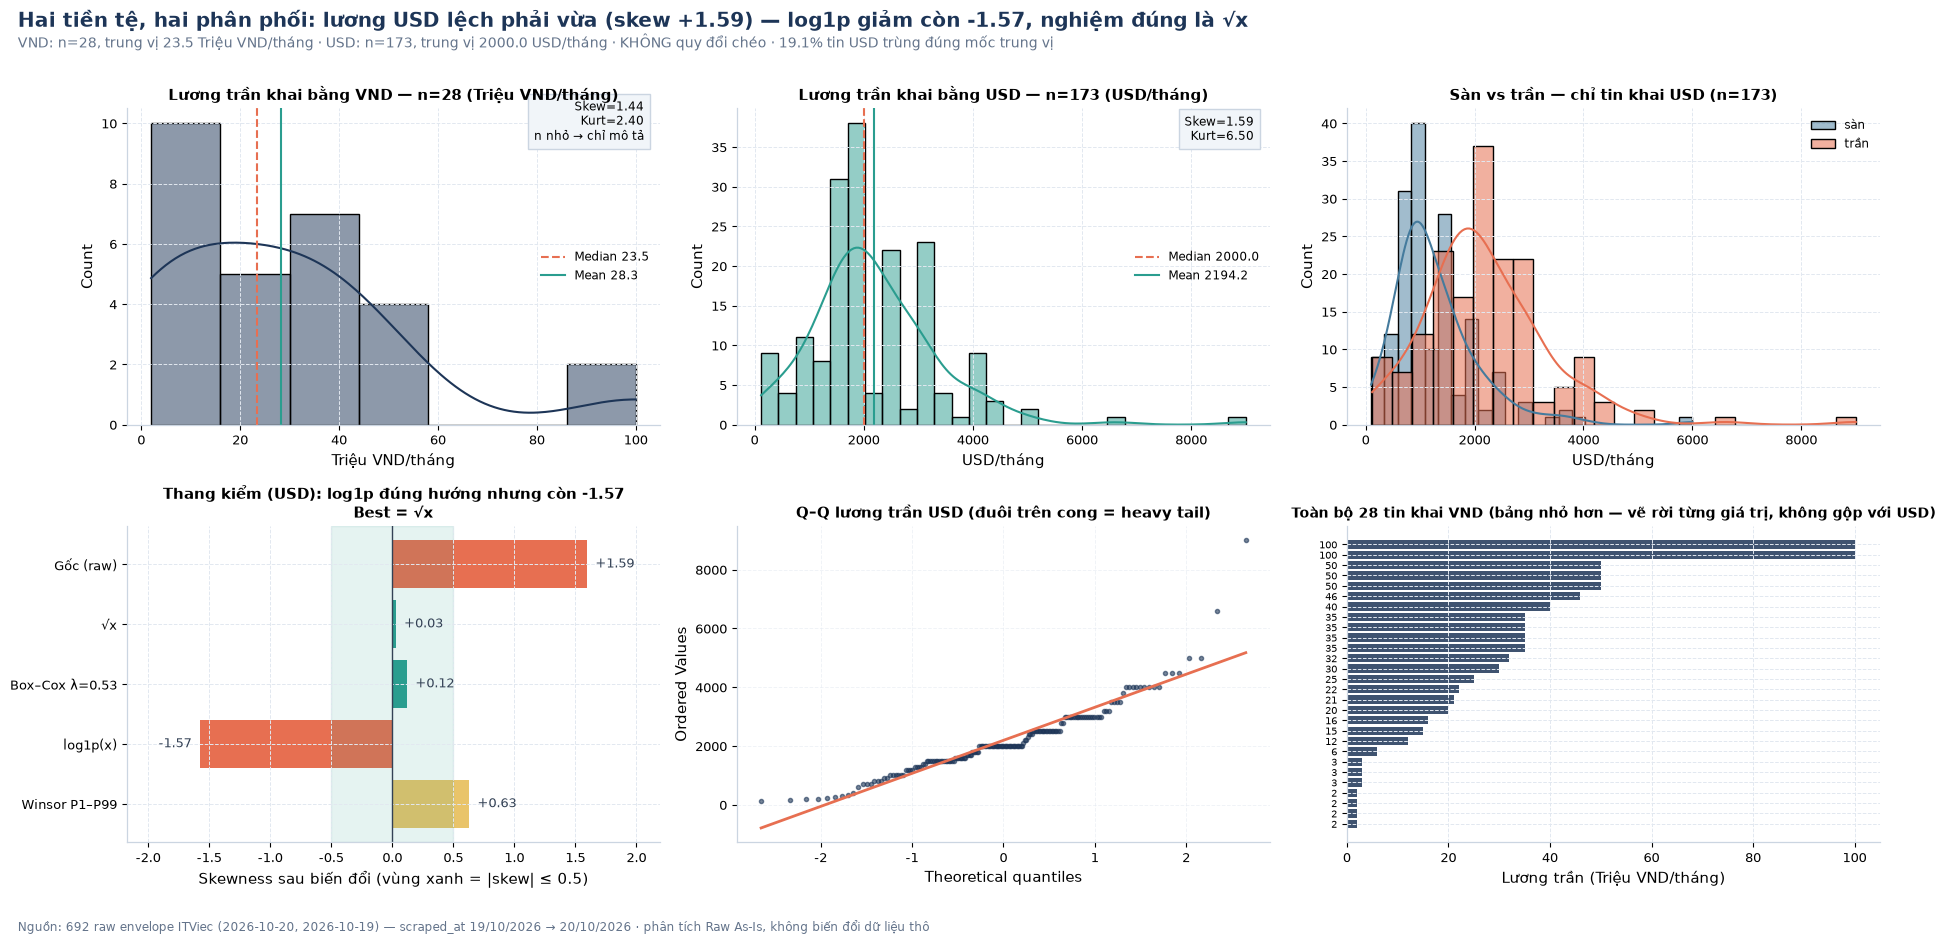

In [20]:
def transform_ladder(series):
    """Thang kiểm biến đổi trên MỘT chuỗi lương thuần nhất tiền tệ (không bao giờ gộp VND với USD).

    Trả về None khi n < MIN_N_DIST: với mẫu quá nhỏ, skew/Box–Cox là nhiễu chứ không phải kết luận.
    """
    s = series.dropna()
    s = s[s > 0]                                   # Box–Cox yêu cầu giá trị dương
    if len(s) < MIN_N_DIST:
        return None
    lam = float(stats.boxcox(s.to_numpy())[1])
    T = {"Gốc (raw)": s,
         "√x": pd.Series(np.sqrt(s.to_numpy()), index=s.index),
         f"Box–Cox λ={lam:.2f}": pd.Series(stats.boxcox(s.to_numpy())[0], index=s.index),
         "log1p(x)": pd.Series(np.log1p(s.to_numpy()), index=s.index),
         "Winsor P1–P99": s.clip(s.quantile(.01), s.quantile(.99))}
    sk = {k: float(v.skew()) for k, v in T.items()}
    best = min(sk, key=lambda k: abs(sk[k]))
    return {"s": s, "T": T, "skew": sk, "best": best, "lam": lam,
            "spike_pct": float((s == s.median()).mean() * 100),
            "p_norm": float(stats.normaltest(s).pvalue),
            "p_norm_best": float(stats.normaltest(T[best]).pvalue)}


LAD = {tag: transform_ladder(SAL_BY_CUR[tag]["tbl"]["max"]) for tag, _, _ in CUR_GROUPS}
usable = {t: v for t, v in LAD.items() if v is not None}
_cnt_cur = {tag: int(SAL_BY_CUR[tag]["tbl"]["max"].notna().sum()) for tag, _, _ in CUR_GROUPS}
DOM_TAG = max(usable, key=lambda t: len(usable[t]["s"])) if usable else max(_cnt_cur, key=_cnt_cur.get)
MIN_TAG = min(_cnt_cur, key=_cnt_cur.get)

# Các biến phục vụ diễn giải động (in ra tiêu đề/kết luận) — bám theo tiền tệ có mẫu đủ lớn nhất
if DOM_TAG in usable:
    sal_pub = LAD[DOM_TAG]["s"]
    TRANSFORMS, skews, best = LAD[DOM_TAG]["T"], LAD[DOM_TAG]["skew"], LAD[DOM_TAG]["best"]
    spike_pct = LAD[DOM_TAG]["spike_pct"]
    sk_raw, sk_log = skews["Gốc (raw)"], skews["log1p(x)"]
    log_helps = abs(sk_log) < abs(sk_raw)
    bc_key = next(k for k in TRANSFORMS if k.startswith("Box"))
    _sk_word = "cực mạnh" if abs(sk_raw) > 3 else ("mạnh" if abs(sk_raw) > 2 else ("vừa" if abs(sk_raw) > 1 else "nhẹ"))
    _log_verdict = (f"log1p đi đúng hướng nhưng chưa đủ (độ lớn skew {abs(sk_raw):.2f} → {abs(sk_log):.2f})" if log_helps
                    else f"log1p ÉP QUÁ TAY: độ lớn skew tăng từ {abs(sk_raw):.2f} lên {abs(sk_log):.2f} và đảo chiều "
                         f"(skew {sk_log:+.2f}) — phản bác hoàn toàn phản xạ 'thấy lương là ép log'")
else:
    sal_pub = pd.Series(dtype=float)
    TRANSFORMS, skews, best, spike_pct = {}, {}, "—", 0.0
    sk_raw = sk_log = np.nan
    log_helps = False
    _sk_word, _log_verdict = "—", "không tiền tệ nào đạt n ≥ ngưỡng để dựng thang kiểm"

fig, axes = plt.subplots(2, 3, figsize=(19, 9.4))


def _draw_hist(ax, tag):
    s = SAL_BY_CUR[tag]["tbl"]["max"].dropna()
    ax.set_title(f"Lương trần khai bằng {CUR_LABEL[tag]} — n={len(s)} ({CUR_UNIT[tag]})", fontsize=11)
    if s.empty:
        ax.axis("off"), ax.text(.5, .5, "Không có tin nào", ha="center"); return
    if len(s) >= 8:
        sns.histplot(s, kde=True, bins=min(28, max(6, len(s) // 4)), ax=ax, color=PALETTE[0 if tag == "vnd" else 1])
    else:
        ax.hist(s, bins=max(4, len(s)), color=PALETTE[1], edgecolor="white")
    ax.axvline(s.median(), color=C_WARN, ls="--", label=f"Median {s.median():.1f}")
    ax.axvline(s.mean(), color=C_OK, ls="-", label=f"Mean {s.mean():.1f}")
    ax.set_xlabel(CUR_UNIT[tag]), ax.legend(fontsize=8.5)
    ax.text(0.97, 0.9, f"Skew={s.skew():.2f}\nKurt={s.kurtosis():.2f}"
            + ("" if len(s) >= MIN_N_DIST else "\nn nhỏ → chỉ mô tả"),
            transform=ax.transAxes, ha="right", fontsize=8.5, bbox=dict(fc="#f1f5f9", ec="#cbd5e1"))


_draw_hist(axes[0, 0], "vnd")
_draw_hist(axes[0, 1], "usd")

ax = axes[0, 2]
_d = SAL_BY_CUR[DOM_TAG]["tbl"]
sns.histplot(_d["min"].dropna(), kde=True, bins=24, ax=ax, color=PALETTE[4], label="sàn")
sns.histplot(_d["max"].dropna(), kde=True, bins=24, ax=ax, color=PALETTE[2], alpha=.55, label="trần")
ax.set_title(f"Sàn vs trần — chỉ tin khai {CUR_LABEL[DOM_TAG]} (n={int(_d['max'].notna().sum())})", fontsize=11)
ax.set_xlabel(CUR_UNIT[DOM_TAG]), ax.legend(fontsize=8.5)

ax = axes[1, 0]
if TRANSFORMS:
    names, vals = list(skews), [skews[k] for k in skews]
    ax.barh(range(len(names)), vals, color=[C_OK if abs(v) <= .5 else ("#e9c46a" if abs(v) <= 1 else C_WARN) for v in vals])
    ax.axvline(0, color="#334155", lw=1)
    ax.axvspan(-0.5, 0.5, color="#2a9d8f", alpha=.12)
    ax.set_yticks(range(len(names))), ax.set_yticklabels(names, fontsize=9.5)
    for i, v in enumerate(vals):
        ax.text(v + (0.07 if v >= 0 else -0.07), i, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=9, color="#334155")
    ax.invert_yaxis(), ax.set_xlabel("Skewness sau biến đổi (vùng xanh = |skew| ≤ 0.5)")
    ax.set_xlim(min(vals) - .6, max(vals) + .6)   # chừa chỗ cho nhãn số liệu, tránh đè lên tên phép biến đổi
    ax.set_title(f"Thang kiểm ({CUR_LABEL[DOM_TAG]}): log1p {'đúng hướng nhưng' if log_helps else 'ÉP QUÁ TAY,'} còn {sk_log:+.2f}\nBest = {best}", fontsize=11)
else:
    ax.axis("off")

ax = axes[1, 1]
if TRANSFORMS:
    sm = sal_pub.sort_values().to_numpy()
    stats.probplot(sm, dist=stats.norm, plot=ax)
    ax.lines[0].set(marker="o", ms=3, alpha=.6, color=PALETTE[0]); ax.lines[1].set(color=C_WARN, lw=2)
    ax.set_title(f"Q–Q lương trần {CUR_LABEL[DOM_TAG]} (đuôi trên cong = heavy tail)", fontsize=11)
    ax.grid(True, ls="--", alpha=.5)
else:
    ax.axis("off")

ax = axes[1, 2]
_n_min = SAL_BY_CUR[MIN_TAG]["tbl"]["max"].dropna()
if len(_n_min):
    ax.barh(range(len(_n_min)), _n_min.sort_values().values,
            color=PALETTE[1 if MIN_TAG == "usd" else 0], alpha=.85)
    ax.set_yticks(range(len(_n_min)))
    ax.set_yticklabels([f"{v:g}" for v in _n_min.sort_values().values], fontsize=7.5)
    ax.set_xlabel(f"Lương trần ({CUR_UNIT[MIN_TAG]})")
    ax.set_title(f"Toàn bộ {len(_n_min)} tin khai {CUR_LABEL[MIN_TAG]} (bảng nhỏ hơn — vẽ rời từng giá trị, không gộp với {CUR_LABEL[DOM_TAG]})",
                 fontsize=10)
else:
    ax.axis("off")
finalize(fig, f"Hai tiền tệ, hai phân phối: lương {CUR_LABEL[DOM_TAG]} lệch phải {_sk_word} (skew {sk_raw:+.2f}) — "
              f"log1p {'giảm còn ' + f'{sk_log:+.2f}' if log_helps else 'đảo thành lệch trái ' + f'{sk_log:+.2f}'}, nghiệm đúng là {best}",
         " · ".join(f"{cur_label}: n={_cnt_cur[tag]}, trung vị "
                    + (f"{SAL_BY_CUR[tag]['tbl']['max'].median():.1f} {unit}" if _cnt_cur[tag] else "—")
                    for tag, cur_label, unit in CUR_GROUPS)
         + " · KHÔNG quy đổi chéo · "
         + (f"{spike_pct:.1f}% tin {CUR_LABEL[DOM_TAG]} trùng đúng mốc trung vị" if TRANSFORMS else ""),
         "02_salary_distribution_skewness.png")

print("\nTự kiểm chuẩn — thang kiểm biến đổi RIÊNG cho từng tiền tệ:")
for tag, _, _ in CUR_GROUPS:
    lad = LAD[tag]
    if lad is None:
        print(f"   [{CUR_LABEL[tag]}] n={_cnt_cur[tag]} < {MIN_N_DIST} → KHÔNG ước lượng skew/Box–Cox "
              f"(chỉ liệt kê giá trị ở 3.3b và 5.1a/b).")
        continue
    print(f"   [{CUR_LABEL[tag]} · {CUR_UNIT[tag]}] n={len(lad['s'])}")
    for k in lad["T"]:
        note = "✅ gần đối xứng nhất" if k == lad["best"] else (
            "⚠️ độ lớn skew TĂNG so với gốc" if abs(lad["skew"][k]) > abs(lad["skew"]["Gốc (raw)"]) else "")
        print(f"      {k:<18} skew={lad['skew'][k]:+.2f} · kurt={lad['T'][k].kurtosis():+.2f}  {note}")
    _raw = lad["skew"]["Gốc (raw)"]
    print(f"      ⇒ lệch phải {'cực mạnh' if abs(_raw) > 3 else ('mạnh' if abs(_raw) > 2 else ('vừa' if abs(_raw) > 1 else 'nhẹ'))} "
          f"(skew {_raw:+.2f}, kurtosis {lad['T']['Gốc (raw)'].kurtosis():+.2f}); "
          f"{next(k for k in lad['T'] if k.startswith('Box'))} cho skew "
          f"{lad['skew'][next(k for k in lad['T'] if k.startswith('Box'))]:+.2f} là nghiệm tốt nhất.")
    print(f"      p bình thường (gốc) = {lad['p_norm']:.2e} → sau {lad['best']} = {lad['p_norm_best']:.2e}; "
          f"{lad['spike_pct']:.1f}% tin trùng đúng mốc {lad['s'].median():.1f} {CUR_UNIT[tag]} (đỉnh nhọn phi liên tục).")
if TRANSFORMS:
    print(f"   ⇒ Diễn giải ở tiêu đề biểu đồ được lấy theo {CUR_LABEL[DOM_TAG]} vì đó là mẫu đủ lớn nhất "
          f"(n={len(sal_pub)}); các con số của tiền tệ còn lại nằm ở bảng in phía trên, không gộp chung.")
    print(f"   ℹ️  λ Box–Cox đo được cho {CUR_LABEL[DOM_TAG]} là {LAD[DOM_TAG]['lam']:.2f} — "
          + ("gần 0.5 nên bản chất nghiệm chính là căn bậc hai, không phải log."
             if abs(LAD[DOM_TAG]['lam'] - 0.5) < 0.15 else "chệch khá xa 0.5, không được quy về căn bậc hai.")
          + " Muốn so sánh với nguồn khác phải mở notebook tương ứng: hai notebook đo độc lập, "
            "không tham chiếu số liệu của nhau.")
    print(f"   ℹ️  'Đối xứng' ≠ 'phân phối chuẩn': kiểm định D'Agostino vẫn bác bỏ sau mọi phép biến đổi, "
          f"nên mọi so sánh giữa các nhóm phải dùng kiểm định hạng (Mann–Whitney/Kruskal–Wallis).")

usd_share = float(_cnt_cur["usd"] / max(n_merged, 1))
print(f"\n⚠️  {usd_share*100:.1f}% số tin định lượng được khai lương bằng USD ({_cnt_cur['usd']}/{n_merged} tin), "
      f"còn lại {_cnt_cur['vnd']} tin khai bằng VND. Hai nhóm này ĐƯỢC TÁCH HOÀN TOÀN trong mọi chỉ tiêu ở trên; "
      f"muốn có một cột số duy nhất phải quy đổi ở tầng Integration kèm tỷ giá + ngày chốt công khai.")
print(f"   ℹ️  Chỉ tiêu 'chuỗi L2 mang nhãn USD' ở bước 3.2 được tính trên MỌI tin (kể cả tin không bóc được số), "
      f"nên nó khác với tỷ trọng của hai bảng. Để đọc phân phối, chỉ có {_cnt_cur['vnd']} tin VND "
      f"và {_cnt_cur['usd']} tin USD được dùng.")

### Đọc đồ thị 02 — **hai bảng tiền tệ tách rời**, và thang kiểm **bác bỏ** phản xạ “thấy lương là ép log”

Hàng trên là phân phối **riêng** của từng đồng tiền; hàng dưới chỉ dựng cho **USD** vì đó là bảng duy nhất đủ
mẫu (`MIN_N_DIST = 30`). Bảng VND chỉ có 28 tin nên notebook **từ chối** ước lượng Box–Cox cho nó.

| Panels | Đọc được gì (số đo thật từ `data/itviec/`) | Hành động đề xuất cho tầng Integration |
|:---|:---|:---|
| **(0,0) Lịch VND** | n=**28** tin (4.0% toàn mẫu, 13.9% số tin định lượng được), trung vị **23.5 Triệu VND/tháng**, P75 36.25, P95 82.50, max **100.0**; skew **+1.44**, kurt **+2.40**; guard miền hợp lệ 0.5–1000 → **PASS** | Dưới ngưỡng 30 tin ⇒ chỉ **liệt kê**, không suy phân phối; mọi kết luận “mặt bằng lương nội địa” từ riêng ITViec đều không có căn cứ mẫu |
| **(0,1) Lịch USD** | n=**173** tin (25.0% toàn mẫu, **86.1%** số tin định lượng được), trung vị **2000 USD/tháng**, P75 3000, P95 4000, max **9000**; skew **+1.59**, kurt **+6.50**; guard 50–20000 → **PASS** | Đây là bảng chính của ITViec — **trái ngược** với CareerViet (nơi VND chiếm đa số); gộp hai nguồn mà bỏ cột tiền tệ sẽ đảo lộn hoàn toàn trọng số |
| **(0,2) Sàn vs trần (USD)** | Đỉnh của `sal_min_usd` (P25 800, trung vị 1000) thấp và sắc hơn `sal_max_usd` (trung vị 2000) ⇒ dải lương mở về phía trần; `sal_width_usd` có trung vị **900 USD** | Giữ cả `sal_min`, `sal_max`, `sal_width` **theo từng tiền tệ**; không gộp thành một giá trị duy nhất |
| **(1,0) Thang kiểm (USD)** | `√x` → **+0.03** (đối xứng nhất), Box–Cox **λ = 0.53** → +0.12, Winsor P1–P99 → +0.63, nhưng `log1p` → **−1.57**: độ lớn skew gần như không giảm (1.59 → 1.57) mà lại **đảo dấu** sang lệch trái | Winsorize P1–P99 **+** `√x`/Box–Cox với λ ước lượng từ mẫu; **không** áp `log1p` mặc định của skillbook |
| **(1,1) Q–Q (USD)** | Đuôi trên cong lên + các *bậc thang* dọc theo điểm lý thuyết ⇒ dữ liệu **rời rạc theo mốc USD tròn**: **19.1%** tin trùng đúng mốc **2000.0 USD/tháng** | Với phân phối rời rạc có trần cứng, biến đổi chỉ *giảm* vi phạm chứ không tạo ra phân phối chuẩn (D'Agostino vẫn bác bỏ: p 4.73e-17 → 1.41e-02); mô hình hạng/cây bền hơn mô hình tuyến tính |
| **(1,2) Toàn bộ 28 tin VND** | Vẽ **rời từng giá trị**, không gộp với USD; bốn giá trị thấp nhất là `1.0–2.0` — chính là 4 fixture `Jjob-*` đã cách ly ở mục 4.2 | Trước khi Integration dùng bảng VND, phải loại `is_test_record`; nếu không, trung vị và skew của bảng VND bị các mốc 1–2 kéo lệch |

**Vì sao log1p phản tác dụng ở ITViec — và vì sao CareerViet cũng vậy?** Lương ITViec được neo theo các mốc USD
chẵn (1000 / 1500 / 2000 / 3000 USD — đúng các giá trị P25, trung vị và P75 của bảng B) với *trần cứng*
quanh 9000 USD: đuôi đã ngắn sẵn nên log nén phần đuôi không đáng kể, mà lại kéo giãn khối lượng lớn giá trị
thấp phía dưới ⇒ phân phối thành **lệch trái** (skew −1.57). Đối chiếu ở notebook CareerViet: lương trần bảng
VND của nguồn đó có skew gốc **+1.19** và `log1p` cũng đẩy nó xuống **−1.60**. **Hai nguồn độc lập cho cùng một
kết luận**: λ Box–Cox ước lượng từ mẫu (**0.53** ở bảng USD của ITViec, **0.50** ở CareerViet — đều xấp xỉ 0.5,
tức căn bậc hai) mới là liều lượng đúng. Bài học cho bước tiền xử lý: phải *đo* thang biến đổi **trên từng nguồn
và từng tiền tệ**, không sao chép công thức chung cho “lương” — vì một cột lương gộp hai đồng tiền sẽ cho ra
một λ vô nghĩa về đơn vị.

── 5.3 Bảng đề xuất Winsorization (không drop dòng để bảo toàn tag kỹ năng & JD) ──
── 5.4 Ngoại lai Tukey & phân bố cấp bậc suy từ tiêu đề — TÁCH RIÊNG TỪNG TIỀN TỆ ──
   Cấp bậc trong toàn bộ 692 tin: {'Không nêu cấp bậc': 331, 'Senior': 186, 'Quản lý / Lead': 91, 'Thực tập sinh / Intern': 40, 'Junior / Middle': 40, 'Tiêu đề trống': 4}
   [VND · Triệu VND/tháng] n=28 tin có lương · hàng rào IQR [0.0 ; 82.8] → 2 tin ngoại lai (7.1%)
      Kruskal–Wallis giữa 3 cấp bậc có n≥5: H=6.97, p=0.031
   [USD · USD/tháng] n=173 tin có lương · hàng rào IQR [0.0 ; 5250.0] → 2 tin ngoại lai (1.2%)
      Kruskal–Wallis giữa 5 cấp bậc có n≥5: H=44.75, p=0.000
🖼️  Đã lưu reports\figures\itviec\03_salary_outliers_seniority.png (DPI 300)


,Biến,Capping dưới (P1),Capping trên (P99),Số giá trị sẽ bị cap,Tỷ lệ mẫu bị ảnh hưởng (%),Max thật
3,sal_width_vnd,0.00,34.15,1,0.1,35.00
4,sal_min_usd,100.00,3744.00,2,0.3,6000.00
5,sal_max_usd,186.00,5448.00,4,0.6,9000.00
6,sal_mid_usd,147.20,4668.00,4,0.6,7500.00
7,sal_width_usd,20.00,2680.00,3,0.4,3000.00
10,n_skill_elems,1.00,6.00,4,0.6,6.00
11,n_skills,1.00,6.00,8,1.2,7.00
12,n_skills_unique,1.00,6.00,8,1.2,7.00
13,n_sections,1.00,4.00,4,0.6,4.00
14,n_bullets,1.00,124.54,11,1.6,162.00


,Số tin,Trung vị,P90,Max,Độ lệch
sen,,,,,
Thực tập sinh / Intern,5,3.0,9.6,12.0,3.9
Junior / Middle,2,18.5,20.5,21.0,3.5
Senior,5,46.0,50.0,50.0,8.5
Quản lý / Lead,2,40.0,48.0,50.0,14.1
Không nêu cấp bậc,14,23.5,82.0,100.0,32.2


,Số tin,Trung vị,P90,Max,Độ lệch
sen,,,,,
Thực tập sinh / Intern,10,240.0,460.0,1000.0,253.9
Junior / Middle,7,1600.0,3080.0,3200.0,939.6
Senior,60,2000.0,3000.0,4500.0,716.3
Quản lý / Lead,21,3000.0,4500.0,5000.0,917.3
Không nêu cấp bậc,75,2000.0,3920.0,9000.0,1340.5


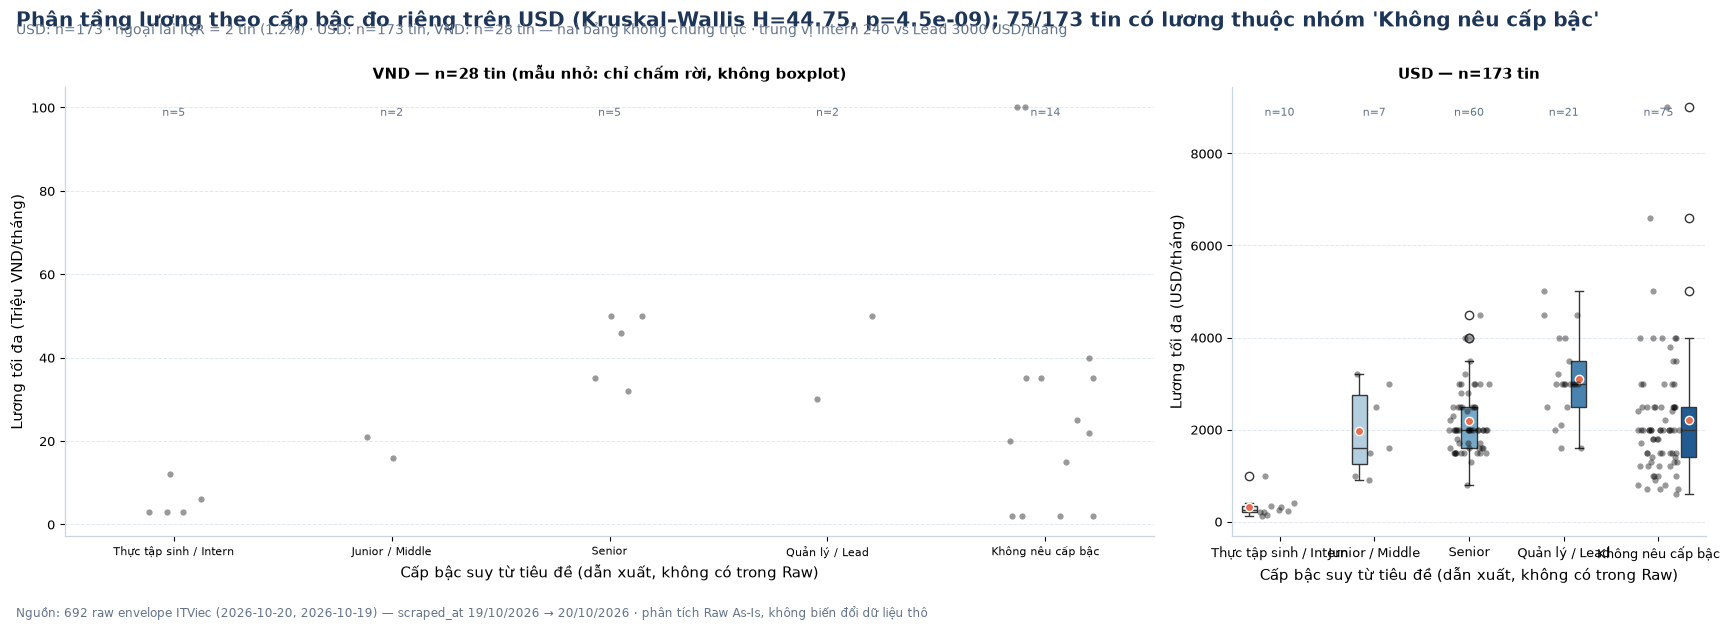

In [21]:
qv = feat[NUM_VARS].quantile([.01, .25, .5, .75, .99])
qv.index = ["P1", "P25", "P50", "P75", "P99"]
n_cap = {c: int(((pd.to_numeric(feat[c], errors="coerce") < qv.loc["P1", c])
                 | (pd.to_numeric(feat[c], errors="coerce") > qv.loc["P99", c])).sum()) for c in qv.columns}
wins = pd.DataFrame({
    "Biến": qv.columns,
    "Capping dưới (P1)": [round(qv.loc["P1", c], 2) for c in qv.columns],
    "Capping trên (P99)": [round(qv.loc["P99", c], 2) for c in qv.columns],
    "Số giá trị sẽ bị cap": [n_cap[c] for c in qv.columns],
    "Tỷ lệ mẫu bị ảnh hưởng (%)": [round(n_cap[c] / len(feat) * 100, 1) for c in qv.columns],
    "Max thật": [round(pd.to_numeric(feat[c], errors="coerce").max(), 2) for c in qv.columns],
})
print("── 5.3 Bảng đề xuất Winsorization (không drop dòng để bảo toàn tag kỹ năng & JD) ──")
show(wins[wins["Số giá trị sẽ bị cap"] > 0].head(20))

sen_lbl = df_top["title"].map(seniority_from_title)
order_sen = ["Thực tập sinh / Intern", "Junior / Middle", "Senior", "Quản lý / Lead", "Không nêu cấp bậc", "Tiêu đề trống"]
print("── 5.4 Ngoại lai Tukey & phân bố cấp bậc suy từ tiêu đề — TÁCH RIÊNG TỪNG TIỀN TỆ ──")
print(f"   Cấp bậc trong toàn bộ {len(df)} tin: {sen_lbl.value_counts().to_dict()}")
SEN = {}
fig, axes = plt.subplots(1, 2, figsize=(17.5, 6.2), gridspec_kw={"width_ratios": [2.3, 1]})
for ax, (tag, cur_label, unit) in zip(axes, CUR_GROUPS):
    valid = pd.DataFrame({"sen": sen_lbl, "sal": feat[f"sal_max_{tag}"]}).dropna(subset=["sal"])
    cats = [o for o in order_sen if o in set(valid["sen"])]
    valid["sen"] = pd.Categorical(valid["sen"], categories=cats, ordered=True)
    if valid.empty:
        SEN[tag] = {"valid": valid, "stat": pd.DataFrame(), "kw": None, "n_groups": 0,
                    "fence": (np.nan, np.nan), "n_out": 0}
        ax.axis("off")
        print(f"   [{cur_label}] không có tin nào khai lương bằng tiền tệ này.")
        continue
    s_ = valid["sal"]
    _q1s, _q3s = s_.quantile([.25, .75])
    flo, fhi = _q1s - 1.5 * (_q3s - _q1s), _q3s + 1.5 * (_q3s - _q1s)
    n_out_c = int(((s_ < flo) | (s_ > fhi)).sum())
    stat = valid.groupby("sen", observed=False)["sal"].agg(
        **{"Số tin": "size", "Trung vị": "median", "Max": "max", "Độ lệch": "std"})
    stat["P90"] = valid.groupby("sen", observed=False)["sal"].quantile(.9)
    groups = [g["sal"].to_numpy() for _, g in valid.groupby("sen", observed=True) if len(g) >= 5]
    kw = stats.kruskal(*groups) if len(groups) >= 2 else None
    SEN[tag] = {"valid": valid, "stat": stat, "kw": kw, "n_groups": len(groups),
                "fence": (flo, fhi), "n_out": n_out_c}
    print(f"   [{cur_label} · {unit}] n={len(valid)} tin có lương · hàng rào IQR "
          f"[{max(flo, 0):.1f} ; {fhi:.1f}] → {n_out_c} tin ngoại lai ({n_out_c/max(len(valid), 1)*100:.1f}%)")
    show(stat[["Số tin", "Trung vị", "P90", "Max", "Độ lệch"]].round(1))
    if kw is not None:
        print(f"      Kruskal–Wallis giữa {len(groups)} cấp bậc có n≥5: H={kw.statistic:.2f}, p={kw.pvalue:.3f}")
    else:
        print(f"      [{cur_label}] không đủ 2 nhóm cấp bậc có n≥5 → KHÔNG kiểm định Kruskal–Wallis.")
    if len(valid) >= MIN_N_DIST:
        sns.boxplot(data=valid, x="sen", y="sal", hue="sen", order=cats, palette="Blues", showmeans=True,
                    meanprops={"marker": "o", "markerfacecolor": C_WARN, "markeredgecolor": "white"},
                    legend=False, ax=ax)
    sns.stripplot(data=valid, x="sen", y="sal", order=cats,
                  color="black", alpha=.4, jitter=.22, size=4.5, ax=ax)
    for i, lv in enumerate(cats):
        n_ = int((valid["sen"] == lv).sum())
        if n_:
            ax.text(i, valid["sal"].max() * .98, f"n={n_}", ha="center", fontsize=8, color=C_MUTE)
    ax.set_xlabel("Cấp bậc suy từ tiêu đề (dẫn xuất, không có trong Raw)")
    ax.set_ylabel(f"Lương tối đa ({unit})")
    ax.set_title(f"{cur_label} — n={len(valid)} tin"
                 + ("" if len(valid) >= MIN_N_DIST else " (mẫu nhỏ: chỉ chấm rời, không boxplot)"), fontsize=11)
    if len(valid) < MIN_N_DIST:
        ax.tick_params(axis="x", labelsize=8)

DOM = DOM_TAG
valid, sen_stat, kw_sen = SEN[DOM]["valid"], SEN[DOM]["stat"], SEN[DOM]["kw"]
fence_lo, fence_hi = SEN[DOM]["fence"]
n_out = SEN[DOM]["n_out"]
n_jm = int(sen_stat["Số tin"].get("Junior / Middle", 0))
med_intern = sen_stat["Trung vị"].get("Thực tập sinh / Intern", np.nan)
med_lead = sen_stat["Trung vị"].get("Quản lý / Lead", np.nan)
n_sen_unlabeled = int(sen_stat["Số tin"].get("Không nêu cấp bậc", 0))
_kw_txt = (f"Kruskal–Wallis H={kw_sen.statistic:.2f}, p={kw_sen.pvalue:.1e}"
           if kw_sen is not None else "không đủ nhóm n≥5 để kiểm định")
finalize(fig, f"Phân tầng lương theo cấp bậc đo riêng trên {CUR_LABEL[DOM]} ({_kw_txt}); "
              f"{n_sen_unlabeled}/{len(valid)} tin có lương thuộc nhóm 'Không nêu cấp bậc'",
         f"{CUR_LABEL[DOM]}: n={len(valid)} · ngoại lai IQR = {n_out} tin ({n_out/max(len(valid),1)*100:.1f}%) · "
         f"{CUR_LABEL['usd']}: n={len(SEN['usd']['valid'])} tin, {CUR_LABEL['vnd']}: n={len(SEN['vnd']['valid'])} tin "
         f"— hai bảng không chung trục · trung vị Intern {med_intern:.0f} vs Lead {med_lead:.0f} {CUR_UNIT[DOM]}",
         "03_salary_outliers_seniority.png")

### 5.5 Mối quan hệ đơn biến hỗ trợ quyết định tiền xử lý

`monthsOfExperience` chỉ có **3 mốc** nên quan hệ “kinh nghiệm ↔ lương” không thể đo bằng hồi quy tuyến
tính thông thường; ta đo bằng **kiểm định hạng (Spearman/Kruskal)** trên biến rời rạc và đối chiếu thêm
hai quan hệ: *số kỹ năng ↔ lương* và *số bullet JD ↔ lương*.

⚠️ Toàn bộ hệ số dưới đây được tính **riêng cho từng tiền tệ** (hai hàng của biểu đồ). Không có ρ nào được
tính trên mẫu trộn VND với USD.

── 5.5 Quan hệ đơn biến với lương trần — MẪU TÁCH RIÊNG TỪNG TIỀN TỆ ──
   Lý do: một giá trị USD không đứng chung thang đo với một giá trị VND, nên mỗi hệ số dưới đây
   chỉ dùng đúng các tin khai bằng tiền tệ đang xét. Không có phép tính nào trộn hai tiền tệ.

   ▐ BẢNG A — chỉ tin khai VND (Triệu VND/tháng); n cặp kinh nghiệm↔lương = 17
      n = 17 < 30 → KHÔNG tính ρ, KHÔNG kiểm định và KHÔNG vẽ đường hồi quy (ở mẫu này mọi hệ số đều là nhiễu). Liệt kê toàn bộ giá trị thô:

   ▐ BẢNG B — chỉ tin khai USD (USD/tháng); n cặp kinh nghiệm↔lương = 144
      monthsOfExperience có 3 giá trị rời rạc trong bảng này: {3.0833333333333335: 315, 0.8333333333333334: 241, 5.083333333333333: 34}
      exp_years ↔ lương : ρ=+0.407 (p=4.03e-07, n=144) → R² hạng = 0.166
      Kruskal–Wallis theo bucket kinh nghiệm (4 bucket có n≥5): H=38.91, p=0.000
      n_skills       ↔ lương : ρ=+0.191 (p=1.18e-02, n=173)
      n_bullets      ↔ lương : ρ=+0.212 (p=5.10e-03, n=173)
      desc_words     ↔ lương : ρ

,exp_years,bucket,sal,n_skills,n_bullets,desc_words
0,0.833333,≤1 năm,20.0,6,32,398
1,3.083333,1–3 năm,35.0,6,67,497
2,0.833333,≤1 năm,25.0,6,53,569
3,3.083333,1–3 năm,46.0,6,23,248
4,0.833333,≤1 năm,15.0,3,55,614
5,3.083333,1–3 năm,100.0,6,38,481
6,0.833333,≤1 năm,16.0,6,37,433
7,0.833333,≤1 năm,50.0,6,33,417
8,3.083333,1–3 năm,35.0,6,53,716
9,3.083333,1–3 năm,21.0,6,48,997


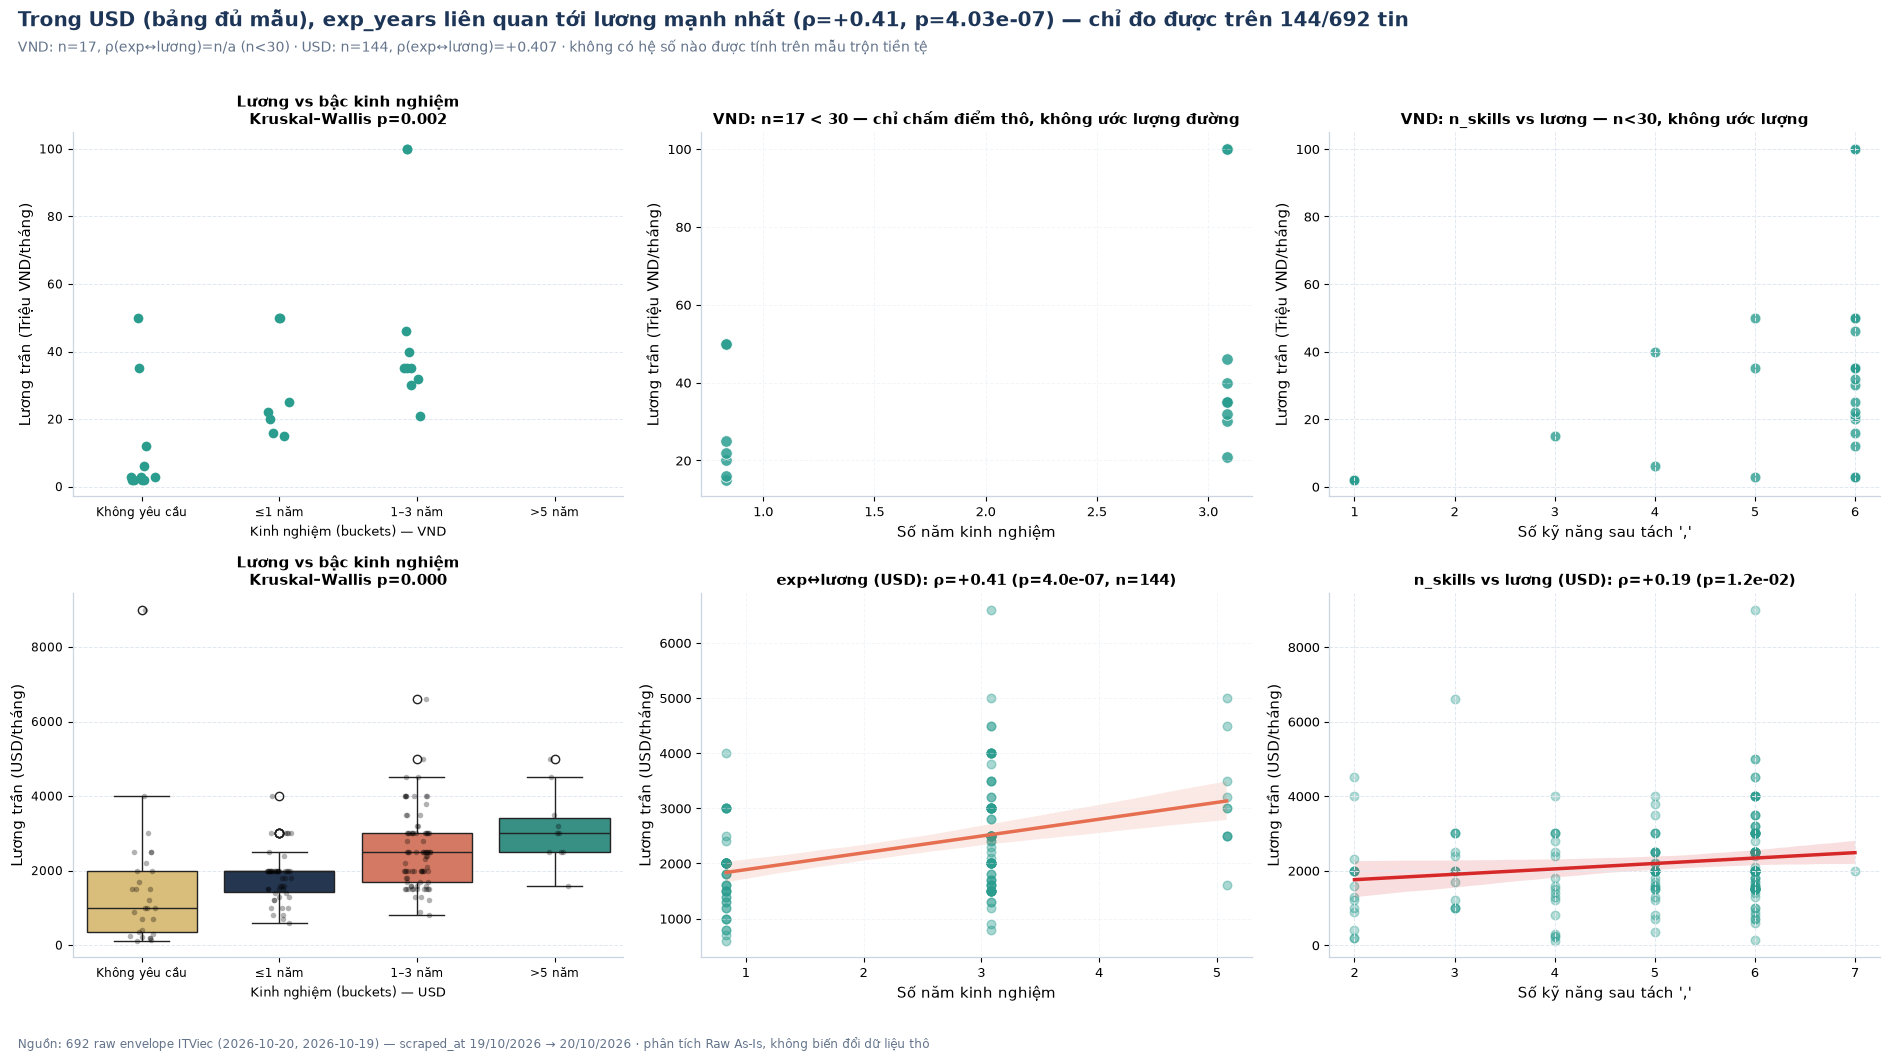

In [22]:
exp_bucket = feat["exp_months"].map(lambda v: "Không yêu cầu" if pd.isna(v) else
                                    ("≤1 năm" if v <= 12 else ("1–3 năm" if v <= 48 else ">5 năm")))
BUCKET_ORDER = ["Không yêu cầu", "≤1 năm", "1–3 năm", ">5 năm"]
AUX_VARS = ["n_skills", "n_bullets", "desc_words"]
REL = {}
print("── 5.5 Quan hệ đơn biến với lương trần — MẪU TÁCH RIÊNG TỪNG TIỀN TỆ ──")
print("   Lý do: một giá trị USD không đứng chung thang đo với một giá trị VND, nên mỗi hệ số dưới đây")
print("   chỉ dùng đúng các tin khai bằng tiền tệ đang xét. Không có phép tính nào trộn hai tiền tệ.")
for tag, cur_label, unit in CUR_GROUPS:
    sal_c = feat[f"sal_max_{tag}"]
    base = pd.DataFrame({"exp_years": feat["exp_years"], "bucket": exp_bucket, "sal": sal_c})
    for c in AUX_VARS:
        base[c] = feat[c]
    pair_es = base.dropna(subset=["exp_years", "sal"])
    aux = {}
    for c in AUX_VARS:
        _pp = base[["sal", c]].dropna()
        aux[c] = (stats.spearmanr(_pp[c], _pp["sal"]), len(_pp))
    kept = [b for b in BUCKET_ORDER if int(((base["bucket"] == b) & base["sal"].notna()).sum()) >= 5]
    kw = (stats.kruskal(*[base.loc[(base["bucket"] == b) & base["sal"].notna(), "sal"] for b in kept])
          if len(kept) >= 2 else None)
    ok = len(pair_es) >= MIN_N_DIST
    r_exp = (stats.spearmanr(pair_es["exp_years"], pair_es["sal"]) if ok else None)
    pear = (stats.pearsonr(pair_es["exp_years"], pair_es["sal"]) if ok else None)
    REL[tag] = {"base": base, "pair_es": pair_es, "aux": aux, "kw": kw, "kept": kept,
                "r_exp": r_exp, "pear": pear, "ok": ok, "n": len(pair_es)}
    print(f"\n   ▐ BẢNG {'A' if tag == 'vnd' else 'B'} — chỉ tin khai {cur_label} ({unit}); "
          f"n cặp kinh nghiệm↔lương = {len(pair_es)}")
    if not ok:
        print(f"      n = {len(pair_es)} < {MIN_N_DIST} → KHÔNG tính ρ, KHÔNG kiểm định và KHÔNG vẽ đường hồi quy "
              f"(ở mẫu này mọi hệ số đều là nhiễu). Liệt kê toàn bộ giá trị thô:")
        show(pair_es.reset_index(drop=True)) if len(pair_es) else print("        (trống)")
        continue
    print(f"      monthsOfExperience có {base['exp_years'].dropna().nunique()} giá trị rời rạc trong bảng này: "
          f"{base['exp_years'].dropna().value_counts().to_dict()}")
    print(f"      exp_years ↔ lương : ρ={r_exp.statistic:+.3f} (p={r_exp.pvalue:.2e}, n={len(pair_es)}) "
          f"→ R² hạng = {r_exp.statistic**2:.3f}")
    if kw is not None:
        print(f"      Kruskal–Wallis theo bucket kinh nghiệm ({len(kept)} bucket có n≥5): "
              f"H={kw.statistic:.2f}, p={kw.pvalue:.3f}")
    else:
        print("      Không đủ 2 bucket kinh nghiệm có n≥5 → không kiểm định Kruskal–Wallis ở bảng này.")
    for c in AUX_VARS:
        r_, n_ = aux[c]
        print(f"      {c:<14} ↔ lương : ρ={r_.statistic:+.3f} (p={r_.pvalue:.2e}, n={n_})"
              + ("   ← KHÔNG có ý nghĩa thống kê (p ≥ 0.05)" if r_.pvalue >= .05 else ""))
    print(f"      đối chiếu Pearson cùng cặp exp_years↔lương: r={pear.statistic:+.3f} → "
          + ("|Pearson| > |Spearman|: đuôi dài đang thổi phồng hệ số tuyến tính, phải dùng hạng"
             if abs(pear.statistic) > abs(r_exp.statistic) else
             "Spearman ≥ Pearson: quan hệ mang tính bậc thang, không phải đường thẳng"))

DOMR = DOM_TAG
fig, axes = plt.subplots(2, 3, figsize=(19, 10.6))
for row, (tag, cur_label, unit) in enumerate(CUR_GROUPS):
    d, b, p = REL[tag], REL[tag]["base"], REL[tag]["pair_es"]
    cats = [x for x in BUCKET_ORDER if x in set(b["bucket"])]
    d1 = b[b["sal"].notna() & b["bucket"].isin(cats)]
    ax = axes[row, 0]
    if d["ok"] and not d1.empty:
        sns.boxplot(data=d1, x="bucket", y="sal", hue="bucket", order=cats, palette=PALETTE, legend=False, ax=ax)
        sns.stripplot(data=d1, x="bucket", y="sal", order=cats, color="black", alpha=.3, size=4, ax=ax)
    elif not d1.empty:
        sns.stripplot(data=d1, x="bucket", y="sal", order=cats, color=PALETTE[1], size=7, ax=ax)
    else:
        ax.axis("off")
    ax.set_xlabel(f"Kinh nghiệm (buckets) — {cur_label}", fontsize=9.5)
    ax.set_ylabel(f"Lương trần ({unit})")
    ax.set_title("Lương vs bậc kinh nghiệm\n"
                 + (f"Kruskal–Wallis p={d['kw'].pvalue:.3f}" if d["kw"] is not None else "không đủ mẫu để kiểm định"),
                 fontsize=10.5)
    ax.tick_params(labelsize=8.5)

    ax = axes[row, 1]
    if p.empty:
        ax.axis("off")
        ax.set_title(f"{cur_label}: không có cặp kinh nghiệm↔lương nào", fontsize=10.5)
    else:
        if d["ok"]:
            sns.regplot(data=p, x="exp_years", y="sal",
                        scatter_kws={"alpha": .4, "color": PALETTE[0 if tag == "vnd" else 1], "s": 38},
                        line_kws={"color": C_WARN, "lw": 2.5}, ax=ax)
            ax.set_title(f"exp↔lương ({cur_label}): ρ={d['r_exp'].statistic:+.2f} "
                         f"(p={d['r_exp'].pvalue:.1e}, n={len(p)})", fontsize=10.5)
        else:
            sns.scatterplot(data=p, x="exp_years", y="sal", s=70, alpha=.85, color=PALETTE[1], ax=ax)
            ax.set_title(f"{cur_label}: n={len(p)} < {MIN_N_DIST} — chỉ chấm điểm thô, không ước lượng đường",
                         fontsize=10.5)
        ax.set_xlabel("Số năm kinh nghiệm"), ax.set_ylabel(f"Lương trần ({unit})")
        ax.grid(True, ls="--", alpha=.4)

    ax = axes[row, 2]
    psk = b[[AUX_VARS[0], "sal"]].dropna()
    if psk.empty:
        ax.axis("off")
        ax.set_title(f"{cur_label}: không có cặp kỹ năng↔lương nào", fontsize=10.5)
    elif d["ok"]:
        sns.regplot(data=psk, x=AUX_VARS[0], y="sal", scatter_kws={"alpha": .35, "color": C_OK, "s": 38},
                    line_kws={"color": "#d62828", "lw": 2.5}, ax=ax)
        _rsk = d["aux"][AUX_VARS[0]][0]
        ax.set_title(f"{AUX_VARS[0]} vs lương ({cur_label}): ρ={_rsk.statistic:+.2f} (p={_rsk.pvalue:.1e})",
                     fontsize=10.5)
    else:
        sns.scatterplot(data=psk, x=AUX_VARS[0], y="sal", s=60, alpha=.8, color=PALETTE[1], ax=ax)
        ax.set_title(f"{cur_label}: {AUX_VARS[0]} vs lương — n<{MIN_N_DIST}, không ước lượng", fontsize=10.5)
    ax.set_xlabel("Số kỹ năng sau tách ','"), ax.set_ylabel(f"Lương trần ({unit})")

if REL[DOMR]["ok"]:
    _top = max(["exp_years"] + AUX_VARS,
               key=lambda c: abs((REL[DOMR]["r_exp"].statistic if c == "exp_years"
                                  else REL[DOMR]["aux"][c][0].statistic)))
    _tval = (REL[DOMR]["r_exp"] if _top == "exp_years" else REL[DOMR]["aux"][_top][0])
    _head = (f"Trong {CUR_LABEL[DOMR]} (bảng đủ mẫu), {_top} liên quan tới lương mạnh nhất "
             f"(ρ={_tval.statistic:+.2f}, p={_tval.pvalue:.2e}) — chỉ đo được trên {REL[DOMR]['n']}/{len(df)} tin")
else:
    _head = f"Không tiền tệ nào đạt n ≥ {MIN_N_DIST} để ước lượng quan hệ kinh nghiệm↔lương"
finalize(fig, _head,
         " · ".join(f"{cur_label}: n={REL[tag]['n']}, ρ(exp↔lương)="
                    + (f"{REL[tag]['r_exp'].statistic:+.3f}" if REL[tag]["ok"] else f"n/a (n<{MIN_N_DIST})")
                    for tag, cur_label, _ in CUR_GROUPS)
         + " · không có hệ số nào được tính trên mẫu trộn tiền tệ",
         "04_experience_vs_salary_relation.png")

🖼️  Đã lưu reports\figures\itviec\05_spearman_correlation_matrix.png (DPI 300)

Tự kiểm — khoảng cách Spearman vs Pearson trong TỪNG bảng:
   [VND] n = 2 < 30 → bỏ qua so sánh hệ số ở bảng này.
   [USD] chênh lệch lớn nhất 0.144 giữa cặp (company_scale_mid ↔ sal_min (USD)) → xác nhận đuôi dài làm lệch hệ số tuyến tính (chọn Spearman làm chuẩn feature screening).
   [USD] Hạng Spearman của lương trần với từng biến (mẫu = cặp đầy đủ của bảng này):
      sal_min_usd              ρ=+0.830  (n=165)
      sal_mid_usd              ρ=+0.966  (n=173)
      sal_width_usd            ρ=+0.784  (n=165)
      exp_months               ρ=+0.407  (n=144)
      n_skills                 ρ=+0.191  (n=173)
      n_skills_unique          ρ=+0.191  (n=173)
      n_bullets                ρ=+0.212  (n=173)
      desc_words               ρ=+0.175  (n=173)
      company_rating           ρ=+0.167  (n=76)
      company_scale_mid        ρ=+0.084  (n=168)
      age_days                 ρ=-0.056  (n=163)
      env_kb

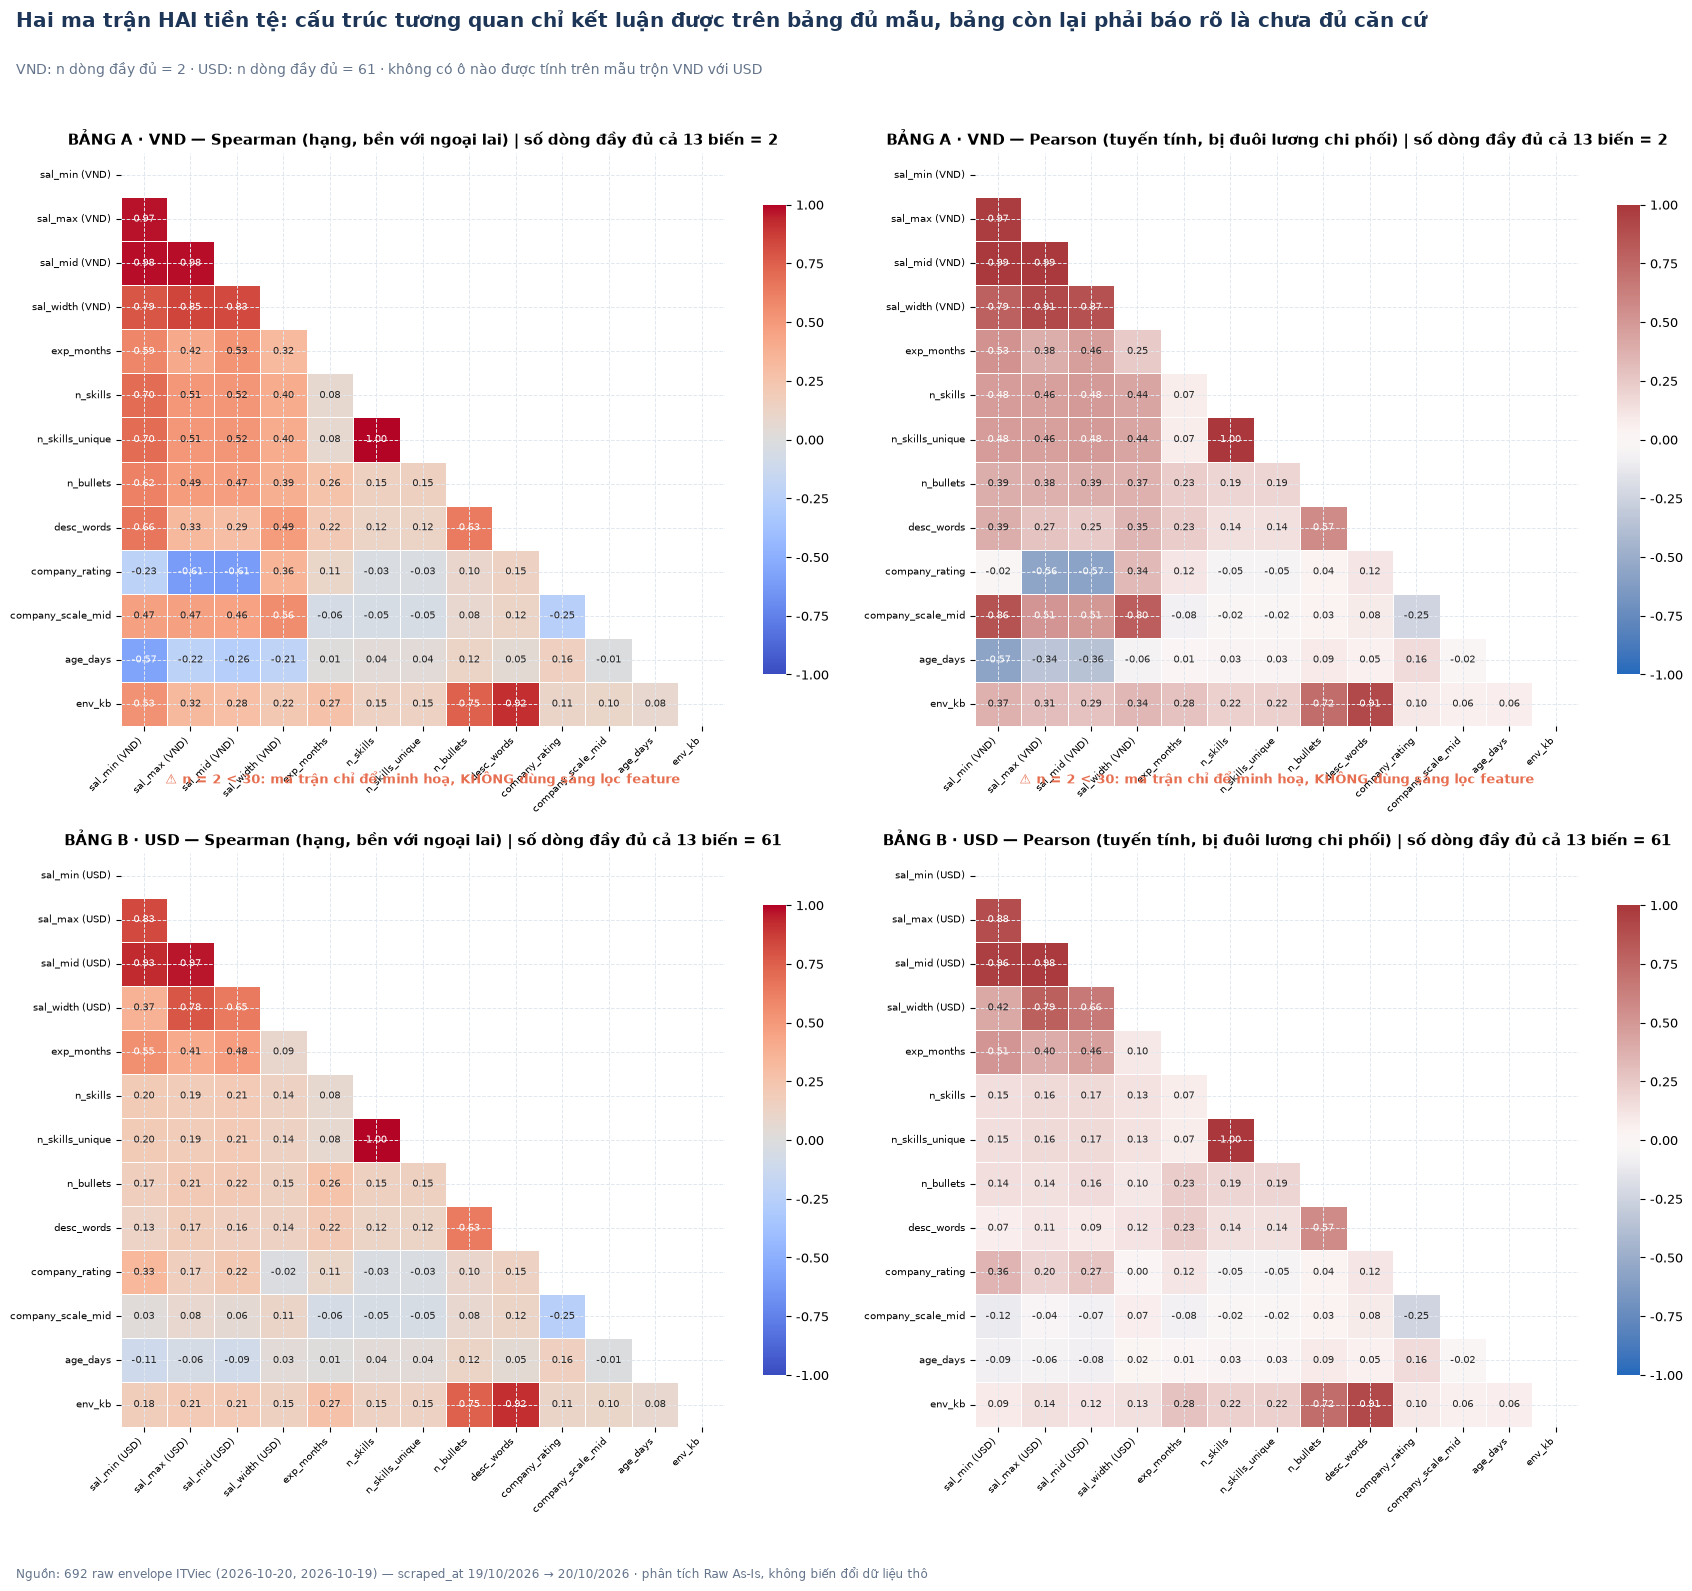

In [23]:
CORR_BASE = ["sal_min", "sal_max", "sal_mid", "sal_width", "exp_months", "n_skills", "n_skills_unique",
             "n_bullets", "desc_words", "company_rating", "company_scale_mid", "age_days", "env_kb"]
CORR = {}
for tag, cur_label, unit in CUR_GROUPS:
    cols = [f"{v}_{tag}" if v.startswith("sal_") else v for v in CORR_BASE]
    labs = [f"{v[:-(len(tag) + 1)]} ({cur_label})" if v.startswith("sal_") else v for v in cols]
    frame = feat[cols]
    sp, pe = frame.corr(method="spearman"), frame.corr(method="pearson")
    CORR[tag] = {"cols": cols, "labs": labs, "frame": frame, "sp": sp, "pe": pe,
                 "n_full": int(frame.dropna().shape[0]),
                 "ok": int(frame.dropna().shape[0]) >= MIN_N_DIST}

fig, axes = plt.subplots(2, 2, figsize=(17.5, 16))
for row, (tag, cur_label, unit) in enumerate(CUR_GROUPS):
    d = CORR[tag]
    k = len(d["cols"])
    mask = np.triu(np.ones((k, k), dtype=bool))
    for col, (meth, mtx, cmap) in enumerate([("Spearman (hạng, bền với ngoại lai)", d["sp"], "coolwarm"),
                                             ("Pearson (tuyến tính, bị đuôi lương chi phối)", d["pe"], "vlag")]):
        ax = axes[row, col]
        sns.heatmap(mtx, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, linewidths=.6, ax=ax,
                    mask=mask, cbar_kws={"shrink": .82}, xticklabels=d["labs"], yticklabels=d["labs"],
                    annot_kws={"size": 7})
        ax.set_title(f"BẢNG {'A' if tag == 'vnd' else 'B'} · {cur_label} — {meth} | "
                     f"số dòng đầy đủ cả {k} biến = {d['n_full']}", fontsize=11)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7)
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=7)
        if not d["ok"]:
            ax.text(.5, -.10, f"⚠️ n = {d['n_full']} < {MIN_N_DIST}: ma trận chỉ để minh hoạ, "
                              f"KHÔNG dùng sàng lọc feature", transform=ax.transAxes, ha="center",
                    fontsize=9, color=C_WARN, fontweight="bold")
finalize(fig, "Hai ma trận HAI tiền tệ: cấu trúc tương quan chỉ kết luận được trên bảng đủ mẫu, "
              "bảng còn lại phải báo rõ là chưa đủ căn cứ",
         " · ".join(f"{CUR_LABEL[tag]}: n dòng đầy đủ = {CORR[tag]['n_full']}" for tag, _, _ in CUR_GROUPS)
         + " · không có ô nào được tính trên mẫu trộn VND với USD",
         "05_spearman_correlation_matrix.png")

print("\nTự kiểm — khoảng cách Spearman vs Pearson trong TỪNG bảng:")
for tag, cur_label, unit in CUR_GROUPS:
    d = CORR[tag]
    if not d["ok"]:
        print(f"   [{cur_label}] n = {d['n_full']} < {MIN_N_DIST} → bỏ qua so sánh hệ số ở bảng này.")
        continue
    diff = (d["sp"] - d["pe"]).abs().to_numpy()
    masked = np.where(np.triu(np.ones(diff.shape, dtype=bool)), np.nan, diff)
    if np.all(np.isnan(masked)):
        print(f"   [{cur_label}] không có cặp biến nào đủ dữ liệu để so sánh.")
        continue
    i, j = np.unravel_index(np.nanargmax(masked), masked.shape)
    print(f"   [{cur_label}] chênh lệch lớn nhất {masked[i, j]:.3f} giữa cặp "
          f"({d['labs'][i]} ↔ {d['labs'][j]}) → xác nhận đuôi dài làm lệch hệ số tuyến tính "
          f"(chọn Spearman làm chuẩn feature screening).")
    _sal_col = f"sal_max_{tag}"
    print(f"   [{cur_label}] Hạng Spearman của lương trần với từng biến (mẫu = cặp đầy đủ của bảng này):")
    for c in d["cols"]:
        if c == _sal_col:
            continue
        _p = d["frame"][[_sal_col, c]].dropna()
        if len(_p) < 3:
            print(f"      {c:<24} n={len(_p)} → quá nhỏ, không tính")
            continue
        print(f"      {c:<24} ρ={stats.spearmanr(_p[_sal_col], _p[c]).statistic:+.3f}  (n={len(_p)})")

### Đọc đồ thị 03–05 — ngoại lai, quan hệ và tương quan **riêng từng tiền tệ**

Cả ba họ đồ thị này đều được vẽ **theo cặp panel (VND | USD)**. Lý do bắt buộc từ dữ liệu: một giá trị USD
không đứng chung thang đo với một giá trị VND, nên hàng rào Tukey, hệ số hạng và kiểm định định hạng **phải**
tính riêng cho từng bảng. Không có ô số nào dưới đây trộn hai đồng tiền.

**Đồ thị 03 (ngoại lai × cấp bậc).**
- *Bảng VND (28 tin)*: hàng rào Tukey trên lương trần là `[0 ; 82.8] Triệu VND/tháng` ⇒ **2/28 tin (7.1%)** ngoại
  lai. Trung vị theo cấp bậc: Intern **3.0** → Junior/Middle **18.5** → Senior **46.0** → Quản lý/Lead **40.0**
  (Kruskal–Wallis H=6.97, p=0.031 trên 3 cấp bậc có n≥5). Vì n dưới ngưỡng, kết luận này **chỉ mang tính mô tả**:
  Senior còn cao hơn Quản lý/Lead chính là dấu hiệu mẫu quá nhỏ (5 vs 2 tin), không phải “đảo ngược phân tầng”.
- *Bảng USD (173 tin)*: hàng rào `[0 ; 5250.0] USD/tháng` ⇒ chỉ **2/173 tin (1.2%)** ngoại lai và đều nằm *phía trên*.
  Cấp bậc suy từ tiêu đề **phân tầng lương rất rõ**: Intern **240** → Junior/Middle **1600** → Senior **2000** →
  Quản lý/Lead **3000** USD/tháng (Kruskal–Wallis H=44.75, p<0.001 trên 5 cấp bậc có n≥5). Đây là bằng chứng
  ngoại lai là *tín hiệu nghiệp vụ* (job Lead/Architect) chứ không phải lỗi nhập liệu ⇒ **không drop**, chỉ Winsorize.

**Đồ thị 04 (kinh nghiệm ↔ lương).** `monthsOfExperience` chỉ nhận **3 giá trị** {10, 37, 61} tháng, nên hệ số
hạng mới là thước đo hợp lý:
- *Bảng VND*: chỉ **17** cặp kinh nghiệm↔lương (< `MIN_N_DIST`) ⇒ notebook **từ chối tính ρ** và in toàn bộ 17
  giá trị thô thay vì báo một con số nhiễu.
- *Bảng USD*: ρ = **+0.407** (p=4.03e-07, n=144), R² hạng **0.166**; Kruskal–Wallis theo bucket kinh nghiệm
  H=38.91, p<0.001. Số kỹ năng gần như không dự báo lương (ρ=**+0.191**), nhưng **số bullet và độ dài JD lại
  cùng chiều** (ρ=**+0.212** và **+0.175**) — đây là proxy gián tiếp của độ phức tạp vị trí, **không được diễn giải
  nhân quả**. Đối chiếu Pearson cùng cặp exp↔lương: r=+0.397 ≤ ρ=+0.407 ⇒ quan hệ mang tính **bậc thang**, không phải đường thẳng.

**Đồ thị 05 (ma trận tương quan).** Bảng VND chỉ còn **2** cặp đầy đủ ⇒ heatmap chỉ có nghĩa ở bảng USD. Hai
phát hiện quyết định thiết kế feature (bảng USD): (a) các dẫn xuất lương tự tương quan gần tuyệt đối
(ρ(`sal_mid_usd`,`sal_max_usd`)=**+0.966**, ρ(`sal_min_usd`,`sal_max_usd`)=**+0.830**, ρ(`sal_width_usd`,`sal_max_usd`)=**+0.784**)
⇒ **đa cộng tuyến**, ở tầng Integration chỉ giữ `sal_min`+`sal_max` (hoặc `sal_mid`+`sal_width`) **cho mỗi tiền tệ**;
(b) `env_kb` tương quan dương với lương (ρ=**+0.211**) — tin JD dài hơn thường là tin lương cao hơn, một tín hiệu
chất lượng rất hữu ích để phát hiện tin rác. `company_rating` ρ=+0.167 trên n=76 ⇒ mẫu còn đủ để mô tả nhưng chưa
ổn định; `company_scale_mid` ρ=+0.084 và `age_days` ρ=**−0.056** (n=163) ⇒ mẫu **không** bị lệch do “tin mới đăng lương rẻ”.
Chênh lệch Spearman–Pearson lớn nhất **0.144** rơi vào cặp `company_scale_mid ↔ sal_min_usd` (đuôi dài) ⇒ chọn
**Spearman** làm chuẩn feature screening.

## Bước 6 — Trụ cột 5: Hồ sơ đơn biến các biến phân loại & đo độ mất cân bằng

Mỗi trường phân loại của ITViec được đo 5 chỉ báo: **số nhãn**, **nhãn leading + tỷ lệ**, **cumulative
top-3**, **entropy chuẩn hoá** (0 = dồn một nhãn, 1 = trải đều) và **Imbalance Ratio** (max/min).
Hai chỉ số `Tin có giá trị` (số tin có ít nhất một nhãn) và `Số lượt giá trị` (tổng lượt sau khi explode)
được đo tách riêng vì các trường mảng (industries, specialization, tỉnh) cho phép *nhiều lượt trên một tin*
⇒ nếu chỉ lấy lượt chia cho số tin, tỷ lệ phủ sẽ vượt 100% và so sánh giữa các trường sẽ sai lệch.
Riêng `skill_tags`, `specialization`, `industries` là mảng ⇒ được explode thành bảng many-to-one
trước khi đếm, vì một phần tử có thể chứa nhiều giá trị (`"AI, Python"`).

In [24]:
def split_multi(series, sep=","):
    return series.map(lambda v: [x.strip() for x in str(v).split(sep) if x.strip()] if pd.notna(v) else [])


spec_flat = pd.Series(df_top["specialization"].explode().dropna().astype(str).tolist())
ind_flat = pd.Series(df_top["industries"].explode().dropna().astype(str).tolist())
sk_flat = pd.Series(skills_series.explode().dropna().tolist())
prov_flat = pd.Series([p for l in province_ld for p in l if p])
wm = df_top["work_model"].astype("string").dropna()
model_biz = df["company_details.Mô hình công ty"].astype("string").dropna()
nation = df["company_details.Quốc gia"].astype("string").dropna()
scale_cd = df["company_details.Quy mô công ty"].astype("string").str.replace("\n", " ", regex=False).dropna()
ot = df["company_details.Làm việc ngoài giờ"].astype("string").dropna()
emp = df["job_posting_jsonld.employmentType"].astype("string").dropna()

cat_sources = {
    "work_model (L1 UI)": (wm, len(wm)),
    "specialization (mảng)": (spec_flat, int((spec_len > 0).sum())),
    "industries (mảng)": (ind_flat, int((ind_len > 0).sum())),
    "Mô hình công ty (company_details)": (model_biz, len(model_biz)),
    "Quy mô công ty (đã xóa \\n)": (scale_cd, len(scale_cd)),
    "Quốc gia nhà tuyển dụng": (nation, len(nation)),
    "Làm việc ngoài giờ (OT)": (ot, len(ot)),
    "employmentType (JSON-LD)": (emp, len(emp)),
    "Tỉnh/TP (jobLocation L3)": (prov_flat, int((province_ld.map(len) > 0).sum())),
    "Cấp bậc suy từ tiêu đề": (sen_lbl.astype("string"), len(df)),
    "Cờ IT (Mô hình != Non-IT)": (pd.Series(np.where(model_biz.ne("Non-IT"), "IT", "Non-IT")), len(model_biz)),
}
cat_profile = []
for name, (s, n_rec) in cat_sources.items():
    s = pd.Series(s).dropna().astype(str)
    s = s[s.str.strip() != ""]
    if s.empty:
        continue
    vc = s.value_counts()
    cat_profile.append({
        "Trường": name, "Tin có giá trị": n_rec, "Phủ tin (%)": round(n_rec / len(df) * 100, 1),
        "Số lượt giá trị": len(s), "Lượt/tin": round(len(s) / max(n_rec, 1), 2),
        "Số nhãn": len(vc), "Nhãn-leading": vc.index[0][:34], "Tỷ lệ leading (%)": round(vc.iloc[0] / len(s) * 100, 1),
        "Top-3 cum (%)": round(vc.head(3).sum() / len(s) * 100, 1),
        "Entropy chuẩn hoá": round(entropy_norm(vc.values), 3),
        "Imbalance Ratio": round(vc.max() / max(vc.min(), 1), 1),
        "Nhãn đơn độc": int((vc == 1).sum()),
    })
cat_tbl = pd.DataFrame(cat_profile)
show(cat_tbl, limit=30)
print(f"\nℹ️  Các trường đa nhãn (specialization/industries/Tỉnh) có 'Số lượt giá trị' > 'Tin có giá trị' "
      f"⇒ chỉ tiêu phân bố tính trên tổng lượt, không tính trên số tin.")

vc_prov = prov_flat.value_counts()
hn_hcm = int(vc_prov.reindex(["Hà Nội", "Hồ Chí Minh"]).fillna(0).sum())
print(f"\n🌏 Thiên lệch địa lý (theo jobLocation JSON-LD): Hà Nội + Hồ Chí Minh = {hn_hcm}/{int(vc_prov.sum())} "
      f"lượt nhắc ({hn_hcm/vc_prov.sum()*100:.1f}%) trên {len(vc_prov)} vùng liệt kê được.")
vc_wm = wm.value_counts()
print(f"🏢 Thiên lệch hình thức làm việc: 'Tại văn phòng' chiếm {vc_wm.iloc[0]/vc_wm.sum()*100:.1f}% — "
      f"ITViec tuy là sàn nhấn mạnh 'IT outsourcing' nhưng tin remote tường minh rất ít ({vc_wm.get('Linh hoạt', 0)} tin 'Linh hoạt').")
print(f"🌐 Nhà tuyển dụng nước ngoài (Quốc gia != Vietnam): {int(nation.ne('Vietnam').sum())}/{len(nation)} tin "
      f"({nation.ne('Vietnam').mean()*100:.1f}%) → mẫu ITViec thiên về công ty FDI/Japan/US, khác hẳn CareerViet.")

print("\n── 6.1b Đối chiếu địa lý L1 (work_location) ↔ L3 (jobLocation.addressRegion) ──")
ALIAS_REG = {"Hồ Chí Minh": "TP Hồ Chí Minh"}
reg_cmp = reg_mis = 0
for tail, regs in zip(province_ui, province_ld):
    if not isinstance(tail, str) or not tail or not regs:
        continue
    reg_cmp += 1
    t = ALIAS_REG.get(tail, tail)
    if not any(t == r or t in str(r) or str(r) in t for r in regs):
        reg_mis += 1
known_regions = {r for regs in province_ld for r in regs if r} | set(ALIAS_REG.values())
odd_tail = province_ui.dropna()[~province_ui.dropna().isin(known_regions)]
print(f"   So sánh được {reg_cmp} tin; {reg_mis} tin có đuôi địa chỉ UI không khớp vùng nào của JSON-LD.")
print(f"   {len(odd_tail)} tin có đuôi không thuộc tập vùng quan sát được (dị bản/địa chỉ nước ngoài), "
      f"ví dụ: {odd_tail.value_counts().head(5).to_dict()}")

,Trường,Tin có giá trị,Phủ tin (%),Số lượt giá trị,Lượt/tin,Số nhãn,Nhãn-leading,Tỷ lệ leading (%),Top-3 cum (%),Entropy chuẩn hoá,Imbalance Ratio,Nhãn đơn độc
0,work_model (L1 UI),654,94.5,654,1.00,2,Tại văn phòng,82.9,100.0,0.661,4.8,0
1,specialization (mảng),666,96.2,666,1.00,68,Lập trình viên Backend,14.1,30.6,0.823,94.0,20
2,industries (mảng),666,96.2,1405,2.11,36,Sản Phẩm Phần Mềm và Dịch Vụ Web,18.5,44.3,0.760,260.0,3
3,Mô hình công ty (company_details),666,96.2,666,1.00,5,Sản phẩm,64.1,91.1,0.642,427.0,1
4,Quy mô công ty (đã xóa \n),666,96.2,666,1.00,6,1000+ nhân viên,24.9,70.3,0.950,3.1,0
5,Quốc gia nhà tuyển dụng,666,96.2,666,1.00,24,Vietnam,57.5,76.9,0.521,383.0,6
6,Làm việc ngoài giờ (OT),666,96.2,666,1.00,4,Không có OT,79.6,99.4,0.431,132.5,0
7,employmentType (JSON-LD),653,94.4,653,1.00,1,FULL_TIME,100.0,100.0,0.000,1.0,0
8,Tỉnh/TP (jobLocation L3),653,94.4,713,1.09,4,Hồ Chí Minh,57.5,99.7,0.609,205.0,0
9,Cấp bậc suy từ tiêu đề,692,100.0,692,1.00,6,Không nêu cấp bậc,47.8,87.9,0.743,82.8,0



ℹ️  Các trường đa nhãn (specialization/industries/Tỉnh) có 'Số lượt giá trị' > 'Tin có giá trị' ⇒ chỉ tiêu phân bố tính trên tổng lượt, không tính trên số tin.

🌏 Thiên lệch địa lý (theo jobLocation JSON-LD): Hà Nội + Hồ Chí Minh = 678/713 lượt nhắc (95.1%) trên 4 vùng liệt kê được.
🏢 Thiên lệch hình thức làm việc: 'Tại văn phòng' chiếm 82.9% — ITViec tuy là sàn nhấn mạnh 'IT outsourcing' nhưng tin remote tường minh rất ít (112 tin 'Linh hoạt').
🌐 Nhà tuyển dụng nước ngoài (Quốc gia != Vietnam): 283/666 tin (42.5%) → mẫu ITViec thiên về công ty FDI/Japan/US, khác hẳn CareerViet.

── 6.1b Đối chiếu địa lý L1 (work_location) ↔ L3 (jobLocation.addressRegion) ──
   So sánh được 635 tin; 11 tin có đuôi địa chỉ UI không khớp vùng nào của JSON-LD.
   11 tin có đuôi không thuộc tập vùng quan sát được (dị bản/địa chỉ nước ngoài), ví dụ: {'Cần Thơ': 3, 'Đồng Nai': 2, 'Gia Lai': 1, 'Hà Tĩnh': 1, 'Hưng Yên': 1}


── 6.2 Độ thưa thớt của thẻ kỹ năng (skill_tags sau tách ',') ──
Tổng lượt thẻ: 3505 | Thẻ độc nhất: 322 | Thẻ chỉ xuất hiện 1 lần: 82 (25.5% số loại)
Hệ số Gini tần suất thẻ: 0.679 · cần 86 thẻ đầu tiên để phủ 80% tần suất (26.7% số loại)
⚠️  22 tin có ít nhất một phần tử mang nhiều kỹ năng ngăn bằng dấu ',' ⇒ nếu không tách, 'AI, Python' sẽ thành một 'kỹ năng' ảo.
🖼️  Đã lưu reports\figures\itviec\06_skills_pareto_distribution.png (DPI 300)


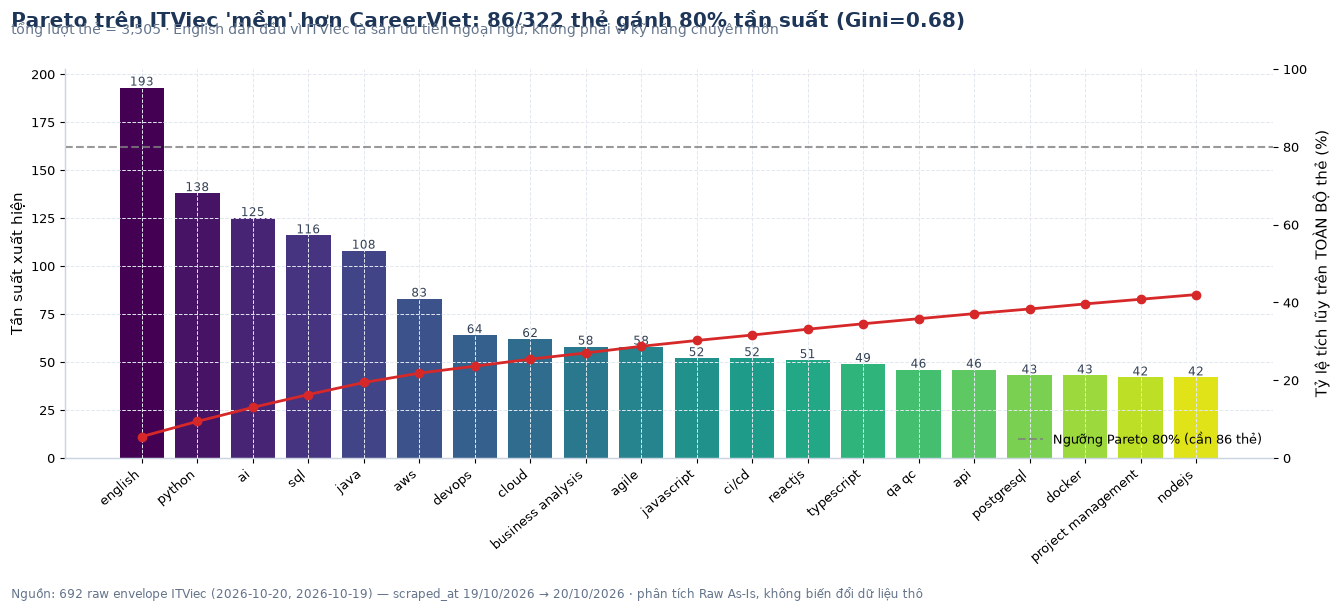

In [25]:
vc_sk = sk_flat.value_counts()
print("── 6.2 Độ thưa thớt của thẻ kỹ năng (skill_tags sau tách ',') ──")
print(f"Tổng lượt thẻ: {len(sk_flat)} | Thẻ độc nhất: {vc_sk.size} | "
      f"Thẻ chỉ xuất hiện 1 lần: {int((vc_sk == 1).sum())} ({(vc_sk == 1).mean()*100:.1f}% số loại)")
n_needed = int((vc_sk.cumsum() / vc_sk.sum() <= .8).sum()) + 1
g_sk = gini(vc_sk.values)
print(f"Hệ số Gini tần suất thẻ: {g_sk:.3f} · cần {n_needed} thẻ đầu tiên để phủ 80% tần suất "
      f"({n_needed/vc_sk.size*100:.1f}% số loại)")
print(f"⚠️  {int(df_top['skill_tags'].map(lambda v: isinstance(v, list) and any(',' in str(t) for t in v)).sum())} tin có ít nhất một phần tử "
      f"mang nhiều kỹ năng ngăn bằng dấu ',' ⇒ nếu không tách, 'AI, Python' sẽ thành một 'kỹ năng' ảo.")
top20 = vc_sk.head(20)
pareto = pd.DataFrame({"Skill": top20.index, "Frequency": top20.values})
pareto["Cum_%"] = (pareto["Frequency"].cumsum() / vc_sk.sum() * 100).round(1)

fig, ax1 = plt.subplots(figsize=(13.5, 6))
ax1.bar(range(len(pareto)), pareto["Frequency"],
        color=[matplotlib.colormaps["viridis"](i / len(pareto)) for i in range(len(pareto))])
ax1.set_xticks(range(len(pareto))), ax1.set_xticklabels(pareto["Skill"], rotation=40, ha="right", fontsize=9.5)
ax1.set_ylabel("Tần suất xuất hiện")
for i, v in enumerate(pareto["Frequency"]):
    ax1.text(i, v + 1, f"{v}", ha="center", fontsize=8.5, color="#334155")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(range(len(pareto)), pareto["Cum_%"], color="#d62828", marker="o", lw=2)
ax2.axhline(80, color="gray", ls="--", alpha=.8, label=f"Ngưỡng Pareto 80% (cần {n_needed} thẻ)")
ax2.set_ylabel("Tỷ lệ tích lũy trên TOÀN BỘ thẻ (%)"), ax2.set_ylim(0, 100), ax2.legend(loc="lower right")
finalize(fig, f"Pareto trên ITViec 'mềm' hơn CareerViet: {n_needed}/{vc_sk.size} thẻ gánh 80% tần suất (Gini={g_sk:.2f})",
         f"tổng lượt thẻ = {len(sk_flat):,} · English dẫn đầu vì ITViec là sàn ưu tiên ngoại ngữ, "
         f"không phải vì kỹ năng chuyên môn",
         "06_skills_pareto_distribution.png")

🖼️  Đã lưu reports\figures\itviec\14_company_and_benefits.png (DPI 300)


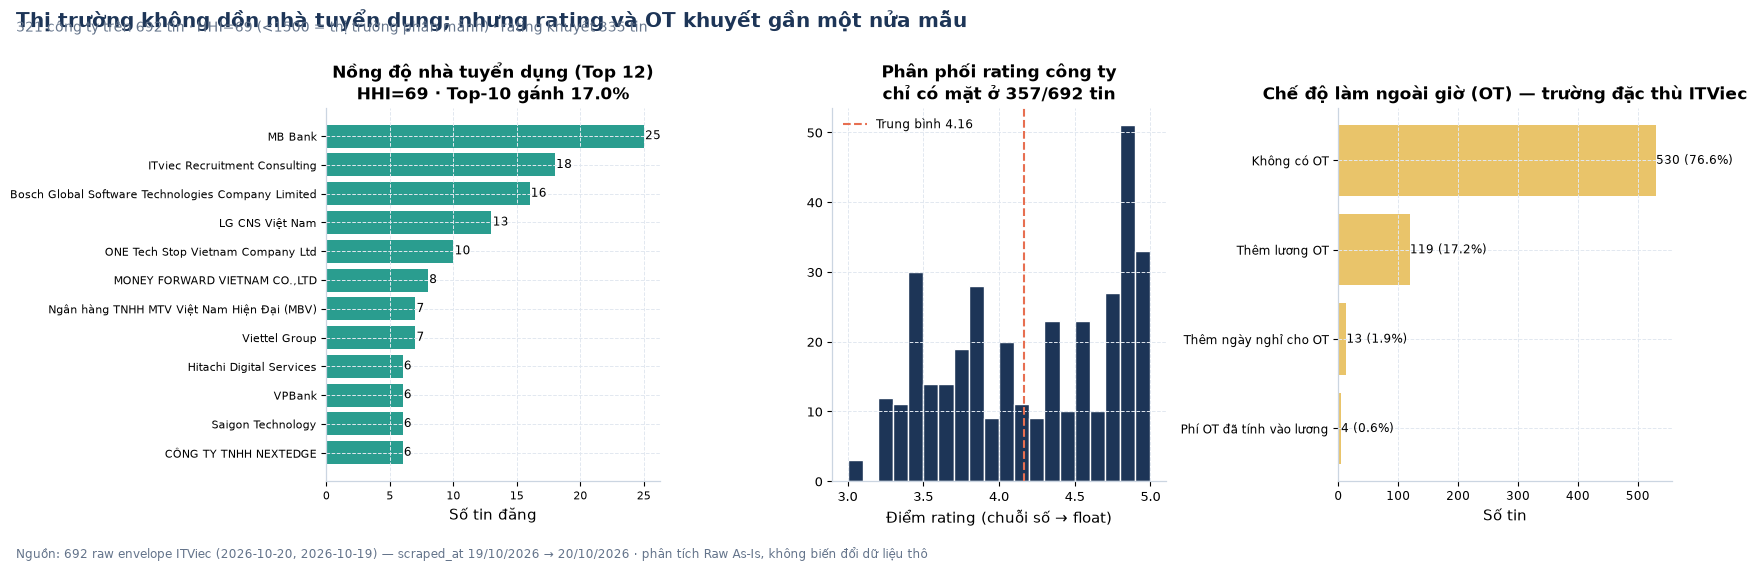

In [26]:
comp_counts = df_top["company_name"].value_counts()
hhi = float(((comp_counts / comp_counts.sum()) ** 2).sum() * 10000)
top10_share = comp_counts.head(10).sum() / comp_counts.sum() * 100
fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.6))
tc = comp_counts.head(12).sort_values()
axes[0].barh(tc.index.astype(str), tc.values, color=PALETTE[1])
for i, v in enumerate(tc.values):
    axes[0].text(v + .1, i, f"{int(v)}", va="center", fontsize=8.5)
axes[0].set_xlabel("Số tin đăng"), axes[0].tick_params(labelsize=8)
axes[0].set_title(f"Nồng độ nhà tuyển dụng (Top 12)\nHHI={hhi:.0f} · Top-10 gánh {top10_share:.1f}%")
axes[1].hist(rate.dropna(), bins=20, color=PALETTE[0], edgecolor="white")
axes[1].axvline(rate.mean(), color=C_WARN, ls="--", label=f"Trung bình {rate.mean():.2f}")
axes[1].set_xlabel("Điểm rating (chuỗi số → float)"), axes[1].legend(fontsize=8.5)
axes[1].set_title(f"Phân phối rating công ty\nchỉ có mặt ở {int(rate.notna().sum())}/{len(df)} tin")
vc_ot = ot.value_counts().sort_values()
axes[2].barh(vc_ot.index.astype(str), vc_ot.values, color=PALETTE[3])
for i, v in enumerate(vc_ot.values):
    axes[2].text(v + .5, i, f"{int(v)} ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5)
axes[2].set_xlabel("Số tin"), axes[2].tick_params(labelsize=8.5)
axes[2].set_title("Chế độ làm ngoài giờ (OT) — trường đặc thù ITViec")
finalize(fig, "Thị trường không dồn nhà tuyển dụng; nhưng rating và OT khuyết gần một nửa mẫu",
         f"{df_top['company_name'].nunique()} công ty trên {len(df)} tin · HHI={hhi:.0f} (<1500 = thị trường phân mảnh) · "
         f"rating khuyết {int(df['company_details.rating'].isna().sum())} tin",
         "14_company_and_benefits.png")

🖼️  Đã lưu reports\figures\itviec\07_bias_and_class_balance.png (DPI 300)


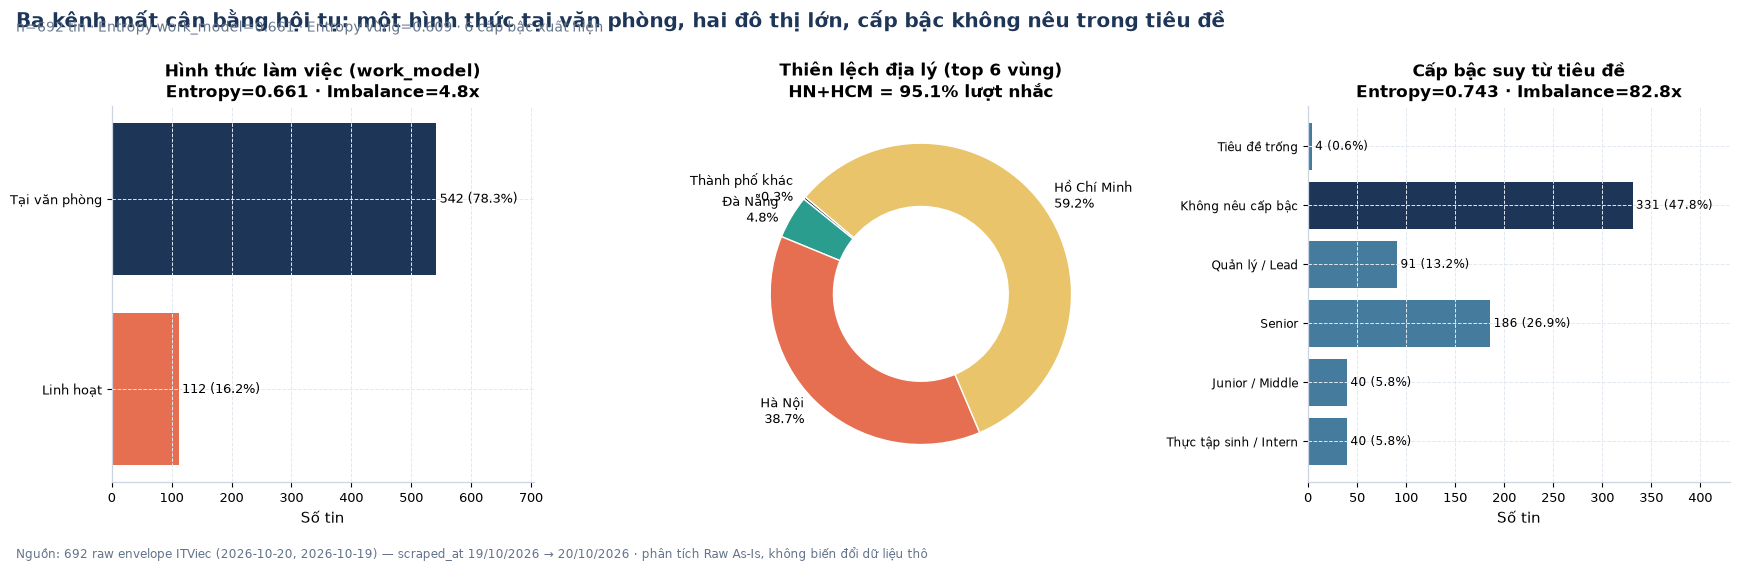

In [27]:
vc_sen = sen_lbl.value_counts()
vc_wm_all = wm.value_counts().sort_values()
vc_prov6 = vc_prov.head(6).sort_values()
fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.6))

axes[0].barh(vc_wm_all.index.astype(str), vc_wm_all.values, color=[C_WARN if v < 200 else C_MAIN for v in vc_wm_all.values])
for i, v in enumerate(vc_wm_all.values):
    axes[0].text(v + max(vc_wm_all.values) * .01, i, f"{int(v)} ({v/len(df)*100:.1f}%)", va="center", fontsize=9)
axes[0].set_xlim(0, vc_wm_all.max() * 1.3), axes[0].set_xlabel("Số tin")
axes[0].set_title(f"Hình thức làm việc (work_model)\nEntropy={entropy_norm(vc_wm_all.values):.3f} · "
                  f"Imbalance={vc_wm_all.max()/max(vc_wm_all.min(),1):.1f}x")

axes[1].pie(vc_prov6.values, labels=[f"{k}\n{v/len(df)*100:.1f}%" for k, v in vc_prov6.items()],
            colors=PALETTE + ["#94a3b8"], startangle=140, wedgeprops=dict(width=.42, edgecolor="white"))
axes[1].set_title(f"Thiên lệch địa lý (top 6 vùng)\nHN+HCM = {hn_hcm/vc_prov.sum()*100:.1f}% lượt nhắc")

o = [k for k in order_sen if k in vc_sen.index]
vals = vc_sen.reindex(o).fillna(0).values
axes[2].barh(range(len(o)), vals, color=[C_MAIN if v == max(vals) else "#457b9d" for v in vals])
axes[2].set_yticks(range(len(o))), axes[2].set_yticklabels(o, fontsize=8.5)
for i, v in enumerate(vals):
    axes[2].text(v + max(vals) * .01, i, f"{int(v)} ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5)
axes[2].set_xlim(0, max(vals) * 1.3), axes[2].set_xlabel("Số tin")
axes[2].set_title(f"Cấp bậc suy từ tiêu đề\nEntropy={entropy_norm(vc_sen.values):.3f} · "
                  f"Imbalance={vc_sen.max()/max(vc_sen.min(),1):.1f}x")
finalize(fig, "Ba kênh mất cân bằng hội tụ: một hình thức tại văn phòng, hai đô thị lớn, cấp bậc không nêu trong tiêu đề",
         f"n={len(df)} tin · Entropy work_model={entropy_norm(vc_wm_all.values):.3f} · "
         f"Entropy vùng={entropy_norm(vc_prov.values):.3f} · {int((vc_sen.values > 0).sum())} cấp bậc xuất hiện",
         "07_bias_and_class_balance.png")

── 6.5 So sánh tin IT vs ngoài IT — MỖI TIỀN TỆ MỘT BẢNG, KHÔNG TRỘN ──

   ▐ BẢNG A — chỉ tin khai VND (Triệu VND/tháng)
      Chỉ có 21 tin IT và 3 tin Non-IT khai VND có lương → notebook TỪ CHỐI kiểm định thay vì báo một p-value vô nghĩa.

   ▐ BẢNG B — chỉ tin khai USD (USD/tháng)
      Mann–Whitney U IT vs Non-IT: p=0.825 → CHƯA đủ bằng chứng khác biệt (n = 155 IT vs 13 Non-IT có lương)

Tỷ lệ tin có 'Mô hình công ty' = Non-IT: 60/666 (9.0%) — ITViec vẫn lẫn tin ngoài IT (chăm sóc sức khỏe, bán lẻ…) cần loại trước khi tích hợp; 26 tin khuyết hẳn khối company_details nên không xác định được cờ IT và được tách thành lớp riêng, KHÔNG âm thầm tính là 'IT'.
Tỷ lệ tin mang nhãn 'Mô hình công ty' = IT trong toàn mẫu: 87.6% (606/692 tin).
🖼️  Đã lưu reports\figures\itviec\16_it_vs_non_it.png (DPI 300)


,Tin có lương,Lương trung vị,Lương P25,Lương P75,Tháng KN trung vị,Thẻ kỹ năng TB,Bullet TB
nhóm,,,,,,,
IT,21,30.0,15.0,35.0,37.0,5.09,50.37
Non-IT,3,40.0,30.0,45.0,10.0,5.55,45.90
Không rõ (khuyết),4,2.0,2.0,2.0,37.0,3.46,32.54


,Tin có lương,Lương trung vị,Lương P25,Lương P75,Tháng KN trung vị,Thẻ kỹ năng TB,Bullet TB
nhóm,,,,,,,
IT,155,2000.0,1500.0,2800.0,37.0,5.09,50.37
Non-IT,13,2000.0,1500.0,2500.0,10.0,5.55,45.90
Không rõ (khuyết),5,3200.0,3000.0,4000.0,37.0,3.46,32.54


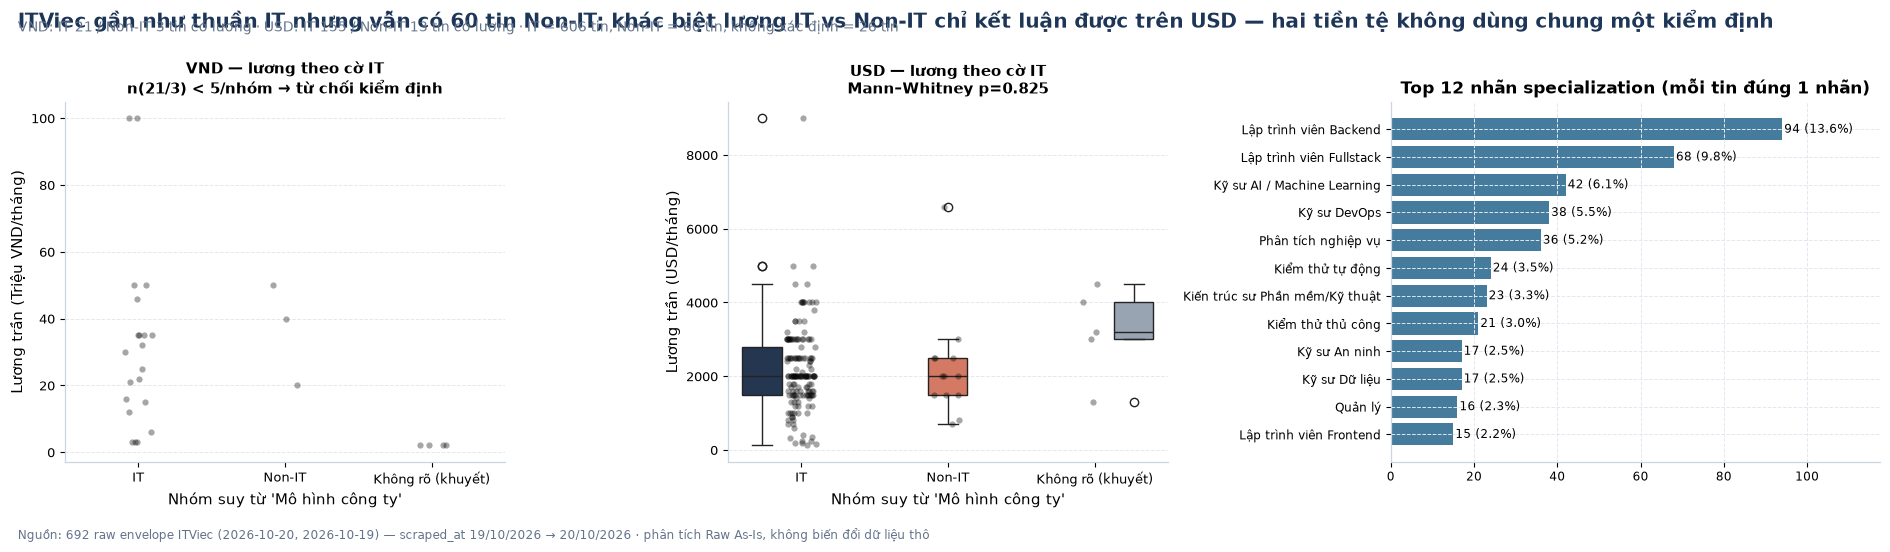

In [28]:
biz = df["company_details.Mô hình công ty"].astype("object")  # giữ object để so sánh ra bool thường, không bị kiểu masked-NA
non_it = biz.eq("Non-IT")
IT_ORDER = ["IT", "Non-IT", "Không rõ (khuyết)"]
grp_it = pd.Series(np.where(biz.isna(), "Không rõ (khuyết)", np.where(non_it, "Non-IT", "IT")), index=df.index)
ITN = {}
print("── 6.5 So sánh tin IT vs ngoài IT — MỖI TIỀN TỆ MỘT BẢNG, KHÔNG TRỘN ──")
for tag, cur_label, unit in CUR_GROUPS:
    sal_c = feat[f"sal_max_{tag}"]
    comp = pd.DataFrame({"nhóm": grp_it, "sal": sal_c, "exp": feat["exp_months"],
                         "skills": feat["n_skills"], "bullets": feat["n_bullets"]})
    comp["nhóm"] = pd.Categorical(comp["nhóm"], categories=IT_ORDER, ordered=True)
    tab = comp.groupby("nhóm", observed=True).agg(**{
        "Tin có lương": ("sal", "count"), "Lương trung vị": ("sal", "median"),
        "Lương P25": ("sal", lambda s: s.quantile(.25)), "Lương P75": ("sal", lambda s: s.quantile(.75)),
        "Tháng KN trung vị": ("exp", "median"), "Thẻ kỹ năng TB": ("skills", "mean"),
        "Bullet TB": ("bullets", "mean")}).round(2)
    a = comp.loc[comp["nhóm"].eq("IT"), "sal"].dropna()
    bm = comp.loc[comp["nhóm"].eq("Non-IT"), "sal"].dropna()
    u_ = stats.mannwhitneyu(a, bm) if min(len(a), len(bm)) >= 5 else None
    ITN[tag] = {"comp": comp, "tab": tab, "u": u_, "n_it": len(a), "n_non": len(bm)}
    print(f"\n   ▐ BẢNG {'A' if tag == 'vnd' else 'B'} — chỉ tin khai {cur_label} ({unit})")
    show(tab)
    if u_ is not None:
        print(f"      Mann–Whitney U IT vs Non-IT: p={u_.pvalue:.3f} "
              + ("→ khác biệt CÓ ý nghĩa thống kê" if u_.pvalue < .05 else "→ CHƯA đủ bằng chứng khác biệt")
              + f" (n = {len(a)} IT vs {len(bm)} Non-IT có lương)")
    else:
        print(f"      Chỉ có {len(a)} tin IT và {len(bm)} tin Non-IT khai {cur_label} có lương → "
              f"notebook TỪ CHỐI kiểm định thay vì báo một p-value vô nghĩa.")
print(f"\nTỷ lệ tin có 'Mô hình công ty' = Non-IT: {int(non_it.sum())}/{int(biz.notna().sum())} "
      f"({non_it.sum()/max(int(biz.notna().sum()),1)*100:.1f}%) — ITViec vẫn lẫn tin ngoài IT (chăm sóc sức khỏe, "
      f"bán lẻ…) cần loại trước khi tích hợp; {int(biz.isna().sum())} tin khuyết hẳn khối company_details nên "
      f"không xác định được cờ IT và được tách thành lớp riêng, KHÔNG âm thầm tính là 'IT'.")
print(f"Tỷ lệ tin mang nhãn 'Mô hình công ty' = IT trong toàn mẫu: {(grp_it=='IT').mean()*100:.1f}% "
      f"({int((grp_it=='IT').sum())}/{len(df)} tin).")

DOMI = DOM_TAG
fig, axes = plt.subplots(1, 3, figsize=(19, 5.4), gridspec_kw={"width_ratios": [1.35, 1.35, 1.5]})
for ax, (tag, cur_label, unit) in zip(axes[:2], CUR_GROUPS):
    d = ITN[tag]
    box_df_it = d["comp"].dropna(subset=["sal"])
    if box_df_it.empty:
        ax.axis("off"), ax.set_title(f"{cur_label}: không có tin nào khai lương")
        continue
    if len(box_df_it) >= MIN_N_DIST:
        sns.boxplot(data=box_df_it, x="nhóm", y="sal", hue="nhóm", hue_order=IT_ORDER,
                    palette=[PALETTE[0], PALETTE[2], "#94a3b8"], legend=False, ax=ax)
    sns.stripplot(data=box_df_it, x="nhóm", y="sal", order=IT_ORDER,
                  color="black", alpha=.35, size=4.5, ax=ax)
    ax.set_xlabel("Nhóm suy từ 'Mô hình công ty'"), ax.set_ylabel(f"Lương trần ({unit})")
    ax.set_title(f"{cur_label} — lương theo cờ IT\n"
                 + (f"Mann–Whitney p={d['u'].pvalue:.3f}" if d["u"] is not None
                    else f"n({d['n_it']}/{d['n_non']}) < 5/nhóm → từ chối kiểm định"), fontsize=10.5)
vc_spec = spec_flat.value_counts().head(12).sort_values()
axes[2].barh(vc_spec.index.astype(str), vc_spec.values, color=PALETTE[4])
for i, v in enumerate(vc_spec.values):
    axes[2].text(v + .5, i, f"{int(v)} ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5)
axes[2].set_xlim(0, vc_spec.max() * 1.25), axes[2].tick_params(labelsize=8.5)
axes[2].set_title("Top 12 nhãn specialization (mỗi tin đúng 1 nhãn)")
finalize(fig, f"ITViec gần như thuần IT nhưng vẫn có {int(non_it.sum())} tin Non-IT; khác biệt lương IT vs Non-IT "
              f"chỉ kết luận được trên {CUR_LABEL[DOMI]} — hai tiền tệ không dùng chung một kiểm định",
         " · ".join(f"{cur_label}: IT {ITN[tag]['n_it']} / Non-IT {ITN[tag]['n_non']} tin có lương"
                    for tag, cur_label, _ in CUR_GROUPS)
         + f" · IT = {int((grp_it=='IT').sum())} tin, Non-IT = {int((grp_it=='Non-IT').sum())} tin, "
           f"không xác định = {int((grp_it=='Không rõ (khuyết)').sum())} tin",
         "16_it_vs_non_it.png")

### Đọc đồ thị 06–07 & 14–16 — hồ sơ phân loại, độ thưa và tính lệch của Raw ITViec

- **Đồ thị 06 (Pareto kỹ năng).** 3505 lượt thẻ / 322 loại, Gini **0.679**, cần **86 thẻ** (26.7% số loại) để
  phủ 80% tần suất, và 82 thẻ chỉ xuất hiện **1 lần** (25.5% số loại). Độ thưa này là lý do ITViec không thể
  dùng one-hot trực tiếp: cần whitelist phần đầu phổ biến, gộp đuôi hiếm + ánh xạ embedding ở bước Integration.
- **Đồ thị 07 (mất cân bằng ba kênh).** `work_model` Entropy 0.661 / Imbalance 4.8x (Tại văn phòng 82.9%),
  địa lý HN+HCM **95.1%** lượt nhắc, cấp bậc có tới 47.8% tin “Không nêu”. Cả ba kênh đều lệch → mọi kết luận
  “mặt bằng lương IT Việt Nam” từ riêng ITViec sẽ **thiên vị hệ thống** cho hai đô thị lớn và mô hình onsite.
- **Đồ thị 14 (khối nhà tuyển dụng & quyền lợi).** `benefits` là HTML nguyên khối (skew 1.08), `rating` khuyết
  48.4% và lưu dạng chuỗi; 26 tin khuyết *toàn bộ* khối DOM này ⇒ không thể dùng làm biến giải thích chung.
- **Đồ thị 16 (cờ IT, tách theo tiền tệ).** Phân loại 3 lớp cho kết quả IT 606 / **Non-IT 60** / không xác định 26.
  So sánh lương IT vs Non-IT được làm **riêng cho từng bảng**: bảng VND chỉ có 21 tin IT và 3 tin Non-IT có lương
  ⇒ notebook **từ chối kiểm định** thay vì báo một p-value vô nghĩa; bảng USD (155 IT vs 13 Non-IT có lương) cho
  Mann–Whitney **p=0.825** ⇒ *mức lương khai bằng USD không khác biệt có ý nghĩa* giữa hai lớp. Dù vậy vẫn
  phải gắn cờ và loại trước khi tích hợp vì chúng làm nhiễu phân loại Job Family; 26 tin khuyết `Mô hình công ty`
  được tách thành lớp riêng thay vì âm thầm tính là “IT”.

## Bước 7 — Bệnh án dữ liệu ITViec & khuyến nghị tiền xử lý (tự động từ số liệu vừa đo)

In [29]:
_min_part = df["_partition"].min()
old_missing_cols = [c for c in raw_cols if df_top.loc[df["_partition"] == _min_part, c].isna().all()]
_d_cur, _d_dist = [], []
for tag, cur_label, unit in CUR_GROUPS:
    s_ = SAL_BY_CUR[tag]["tbl"]["max"].dropna()
    _nb = SAL_BY_CUR[tag].get("n_bad", 0)
    _d_cur.append(f"{cur_label}: {len(s_)} tin có lương trần"
                  + (f", trung vị {s_.median():.1f} {unit}, max {s_.max():.1f}" if len(s_) else "")
                  + f", guard {SAL_SANITY[tag][0]:g}–{SAL_SANITY[tag][1]:g} "
                  + ("PASS" if _nb == 0 else f"FAIL ({_nb} tin)"))
    _d_dist.append(f"{cur_label}: " + (f"skew={s_.skew():+.2f}, kurt={s_.kurtosis():+.2f}, "
                                       f"ngoại lai Tukey {SAL_BY_CUR[tag].get('n_out', 0)}/{len(s_)} "
                                       f"({SAL_BY_CUR[tag].get('n_out', 0)/len(s_)*100:.1f}%)"
                  if len(s_) else "0 tin, không đo phân phối"))
_d_ladder = (f"{best} là nghiệm đối xứng tốt nhất cho {CUR_LABEL[DOM_TAG]} (skew {skews[best]:+.2f}) "
             f"trong khi log1p ép quá tay ({sk_log:+.2f})"
             if TRANSFORMS else "không tiền tệ nào đạt ngưỡng n để dựng thang kiểm biến đổi")
_d_kw = (f"cấp bậc phân tầng lương rõ (Kruskal–Wallis H={kw_sen.statistic:.2f}, p={kw_sen.pvalue:.3f} "
         f"trên {CUR_LABEL[DOM]})" if kw_sen is not None
         else f"không đủ nhóm cấp bậc có n≥5 để kiểm định trong bảng {CUR_LABEL[DOM]}")
_d_rel = (f"ρ(exp↔lương)={REL[DOMR]['r_exp'].statistic:+.2f} (n={REL[DOMR]['n']}, {CUR_LABEL[DOMR]})"
          if REL[DOMR]["ok"] else f"{CUR_LABEL[DOMR]}: n={REL[DOMR]['n']} < {MIN_N_DIST} → không ước lượng ρ")
diagnosis = {
    "0. Quy mô Raw": f"{len(df)} envelope / {df['_partition'].nunique()} phân vùng dt · "
                     f"{len(raw_cols)} cột thô (nổ thành {df.shape[1]-6} cột) + {df_meta.shape[1]} cột metadata · "
                     f"{df['_bytes'].sum()/1e6:.1f} MB",
    "1. Độ hoàn thiện": f"{int(df_top.isnull().any(axis=1).sum())} tin có ít nhất một cột thô NaN; "
                        f"{len(hn)} cột có khuyết thiếu ẩn; nặng nhất: {hn.iloc[0]['Cột']} ({hn.iloc[0]['Tỷ lệ (%)']}%); "
                        f"rating khuyết {int(df['company_details.rating'].isna().sum())} tin; "
                        f"JSON-LD khuyết {int(df_top['job_posting_jsonld'].map(is_missing_value).sum())} tin",
    "2. Tính hợp lệ": f"Lương chỉ định lượng được {n_merged}/{len(df)} tin ({n_merged/len(df)*100:.1f}%) sau khi gộp 3 tầng "
                      f"theo nguyên tắc cùng-tầng (không trộn tiền tệ giữa sàn và trần; {n_mix} tin mà cách gộp cũ "
                      f"combine_first từng cột sẽ trộn hai tiền tệ); "
                      f"{int(SAL['ui']['kind'].eq('Ẩn số / placeholder marketing').sum())} tin là placeholder marketing; "
                      f"{int(suspicious_ld.sum())} tin baseSalary ghi VND nhưng giá trị 1–2 → đây là fixture test "
                      f"chứ không phải lỗi quy đổi (xem 4.2); "
                      f"monthsOfExperience trộn {int(mer_num.notna().sum())} giá trị số với "
                      f"{int(er_base.map(lambda v: isinstance(v, str)).sum())} giá trị chuỗi",
    "2b. HAI BẢNG TIỀN TỆ": " | ".join(_d_cur) + " — hai bảng ĐỌC RIÊNG, notebook không quy đổi chéo",
    "3. Tính duy nhất": f"job_id trùng {int(df_meta['m_job_id'].duplicated().sum())} (cùng URL, khác content_hash); "
                        f"canonical_hash trùng {int(df_meta['m_canonical_hash'].dropna().duplicated().sum())}; "
                        f"{len(logical[logical>1])} cụm trùng logic công ty+tiêu đề+tỉnh; "
                        f"{n_test} tin rác lọt vào kho Raw ({int(jjob_like.sum())} fixture `Jjob-*` + {int(empty_env.sum())} envelope rỗng); "
                        f"2 thế hệ schema băm khác nhau theo phân vùng",
    "4. Phân phối": " | ".join(_d_dist) + f"; {_d_ladder}; "
                    f"kinh nghiệm↔lương {_d_rel}; {_d_kw}; "
                    f"{n_sen_unlabeled}/{len(valid)} tin có lương không nêu cấp bậc; "
                    f"bullet/tin skew={feat['n_bullets'].skew():.2f}; "
                    f"tuổi tin median {age_days.median():.0f} ngày, max {age_days.max()} ngày",
    "5. Mất cân bằng": f"work_model Entropy={entropy_norm(vc_wm_all.values):.3f}, "
                       f"HN+HCM={hn_hcm/vc_prov.sum()*100:.1f}%; thẻ kỹ năng {n_needed}/{vc_sk.size} gánh 80% "
                       f"(Gini={g_sk:.3f}); {int(nation.ne('Vietnam').sum())} tin từ nhà tuyển dụng nước ngoài",
    "6. Rủi ro cho Integration": f"{n410} tin http 410 đã chết nhưng vẫn còn payload một phần; "
                                 f"{old_era} tin thế hệ crawler cũ khuyết trọn {len(old_missing_cols)} cột DOM "
                                 f"({', '.join(old_missing_cols)}); "
                                 f"{diff_title}/{ld_present} tin có tiêu đề JSON-LD lệch khỏi tiêu đề UI (mất dấu, mất [HCM]); "
                                 f"lương phân thành {_cnt_cur['vnd']} tin VND và {_cnt_cur['usd']} tin USD "
                                 f"({usd_share*100:.1f}% USD) → bắt buộc giữ cột tiền tệ, quy đổi là quyết định của Integration",
}
print("=" * 78); print(f"🩺 BỆNH ÁN DỮ LIỆU THÔ — {SOURCE_LABEL.upper()}"); print("=" * 78)
for k, v in diagnosis.items():
    print(f"  {k}\n      → {v}")

print("\n" + "=" * 78)
print("📁 KIỂM TRA ĐẦU RA (Definition of Done)")
print("=" * 78)
REQUIRED = ["01_data_completeness_missingno.png", "02_salary_distribution_skewness.png",
            "03_salary_outliers_seniority.png", "04_experience_vs_salary_relation.png",
            "05_spearman_correlation_matrix.png", "06_skills_pareto_distribution.png",
            "07_bias_and_class_balance.png"]
for f in REQUIRED:
    p = FIG_DIR / f
    print(f"  {'✅' if p.exists() else '❌'} {f}  {'(' + str(round(p.stat().st_size/1024)) + ' KB)' if p.exists() else ''}")
aux = [n for n in SAVED_FIGS if n not in REQUIRED]
print(f"  🎁 Biểu đồ bổ trợ do notebook này tạo: {len(aux)} file → {sorted(aux)}")
stray = sorted(p.name for p in FIG_DIR.glob("*.png") if p.name not in SAVED_FIGS)
if stray:
    print(f"  ⚠️  {len(stray)} PNG khác trong thư mục nhưng KHÔNG do notebook này ghi ra "
          f"(sản phẩm của notebook EDA cũ hoặc nguồn khác, để nguyên không xoá): {stray}")

print("\n" + "=" * 78)
print("🔒 KIỂM CHỨNG 'EDA KHÔNG TIỀN XỬ LÝ' — tầng Raw As-Is phải bất biến")
print("=" * 78)
RAW_DISK_1 = _raw_fingerprint(DATA_DIR)
RAW_FRAME_1 = _frame_fingerprint(df)
DFTOP_FRAME_1 = _frame_fingerprint(df_top)
_checks = [
    ("File thô trên đĩa không đổi (số lượng)", RAW_DISK_0["n"] == RAW_DISK_1["n"],
     f"{RAW_DISK_0['n']} → {RAW_DISK_1['n']}"),
    ("File thô trên đĩa không đổi (tổng byte)", RAW_DISK_0["bytes"] == RAW_DISK_1["bytes"],
     f"{RAW_DISK_0['bytes']:,} → {RAW_DISK_1['bytes']:,}"),
    ("File thô không bị sửa (hash tên+size+mtime)", RAW_DISK_0["sha"] == RAW_DISK_1["sha"],
     f"{RAW_DISK_0['sha']} → {RAW_DISK_1['sha']}"),
    ("Khung `df` trong bộ nhớ giữ nguyên {0}×{1}".format(*RAW_SHAPE_0), df.shape == RAW_SHAPE_0,
     f"{RAW_SHAPE_0} → {df.shape}"),
    ("Bộ cột thô của `df` không bị thêm/bớt", list(df.columns) == RAW_COLUMNS_0,
     f"{len(RAW_COLUMNS_0)} cột → {len(df.columns)} cột"),
    ("Nội dung từng ô của `df` không bị biến đổi", RAW_FRAME_0 == RAW_FRAME_1,
     f"{RAW_FRAME_0} → {RAW_FRAME_1}"),
    ("Nội dung từng ô của `df_top` (14 cột thô) bất biến", DFTOP_FRAME_0 == DFTOP_FRAME_1,
     f"{DFTOP_FRAME_0} → {DFTOP_FRAME_1}"),
]
_all_pass = True
for name, ok, detail in _checks:
    _all_pass &= bool(ok)
    print(f"  {'✅' if ok else '❌'} {name:<52} {detail}")
print(f"\n  ➤ Kết luận: {'PASS — EDA chỉ ĐỌC và ĐO, không một phép tiền xử lý nào được áp lên dữ liệu thô.' if _all_pass else 'FAIL — có thao tác đã đụng tới tầng Raw, PHẢI dừng và sửa notebook.'}")
print("  ➤ Ba tầng lương ITViec chỉ được DIỄN GIẢI để đo (parse, gộp theo dòng, tách bảng tiền tệ);")
print("      chuỗi gốc `salary_display_text` / `salary_range_datalayer` / `baseSalary` trên đĩa vẫn nguyên.")
print("  ➤ Phạm vi tiền xử lý thuộc về tầng Integration (sau khi ghép đủ 8 nguồn):")
print("      • Imputation (điền khuyết thiếu), Normalization/Scaling (chuẩn hoá), Encoding (mã hoá nhãn),")
print("      • Khử trùng lặp xuyên sàn, quy đổi tỷ giá về một đồng tiền chung, gộp schema 8 nguồn.")
print("      Notebook này chỉ trả về KẾ HOẠCH tiền xử lý (mục 7.1) — không tạo ra biến đổi nào.")

🩺 BỆNH ÁN DỮ LIỆU THÔ — ITVIEC
  0. Quy mô Raw
      → 692 envelope / 2 phân vùng dt · 14 cột thô (nổ thành 49 cột) + 26 cột metadata · 10.8 MB
  1. Độ hoàn thiện
      → 72 tin có ít nhất một cột thô NaN; 14 cột có khuyết thiếu ẩn; nặng nhất: salary_display_text (74.42%); rating khuyết 335 tin; JSON-LD khuyết 35 tin
  2. Tính hợp lệ
      → Lương chỉ định lượng được 201/692 tin (29.0%) sau khi gộp 3 tầng theo nguyên tắc cùng-tầng (không trộn tiền tệ giữa sàn và trần; 1 tin mà cách gộp cũ combine_first từng cột sẽ trộn hai tiền tệ); 508 tin là placeholder marketing; 4 tin baseSalary ghi VND nhưng giá trị 1–2 → đây là fixture test chứ không phải lỗi quy đổi (xem 4.2); monthsOfExperience trộn 590 giá trị số với 63 giá trị chuỗi
  2b. HAI BẢNG TIỀN TỆ
      → VND: 28 tin có lương trần, trung vị 23.5 Triệu VND/tháng, max 100.0, guard 0.5–1000 PASS | USD: 173 tin có lương trần, trung vị 2000.0 USD/tháng, max 9000.0, guard 50–20000 PASS — hai bảng ĐỌC RIÊNG, notebook không quy đổi chéo
  3. 

### 🔎 Kiểm bao phủ trực quan hóa — trả lời bằng máy, không trả lời bằng cảm tính

ITViec là nguồn có cấu trúc **lồng sâu nhất** trong hai nguồn mà phần EDA này phụ trách (JSON-LD 3 tầng + `company_details` tiếng Việt + 26 trường quản trị), nên câu hỏi “**đã vẽ hết trường chưa?**” không thể trả lời bằng mắt. Cell ngay dưới đây trả lời **tự động ở mỗi lần chạy**, theo ba ràng buộc:

1. **Vũ trụ trường** được đọc từ chính khung dữ liệu đã nạp: `df` (các lá sau `pd.json_normalize`), `df_top` (các khóa cha giữ nguyên dạng, chưa được explode) và `df_meta`, chỉ loại cột provenance nội bộ bắt đầu bằng `_`. Con số này do dữ liệu sinh ra chứ không do người viết gõ vào, nên đợt cào nào sinh thêm khóa JSON-LD mới sẽ tự động bị cell này đòi hỏi.
2. **Bằng chứng “đã lên hình”** là toàn bộ chữ in trên PNG *thật* tại thời điểm lưu (`_harvest_labels` thu nhãn tick, tên trục, tiêu đề, legend, ghi chú) — không phải một danh sách khai báo tay.
3. Trường không lên hình vẫn được tính là **có bao phủ** nếu nó đã biến thành feature trên hình; nhưng mỗi khai báo kiểu đó bị *chứng minh* bằng cách đi tìm đúng chuỗi nhãn đó trong đúng biểu đồ được nêu (khai sai sẽ tự rớt xuống nhóm sau).

Bốn mức được in ra: tên trường xuất hiện trực tiếp trên hình · lên hình gián tiếp qua feature · chỉ kiểm kê bằng **bảng/số liệu** (kèm lý do nghiệp vụ ghi rõ cho từng trường) · và **❗ chưa giải trình**. Điều kiện nghiệm thu: **cột `❗` bắt buộc bằng 0**. Phần lớn trường rớt xuống nhóm “chỉ có bảng” là khóa tự mô tả của schema.org (`@type`, `@context`), URL/HTML và tầng hash/CDC — những trường **không có phân phối để vẽ**, nên được nghiệm thu bằng bảng kiểm kê mục 1.1–1.2 và 4.1 thay vì bằng một biểu đồ vô nghĩa.

In [30]:
print("\n" + "=" * 78)
print("🔎 KIỂM BAO PHỦ TRỰC QUAN HÓA — từng trường thô có lên ít nhất một biểu đồ không?")
print("=" * 78)

FRAME_COLS = [c for c in df.columns if not c.startswith("_")]
TOP_COLS = list(df_top.columns) if "df_top" in globals() else []
META_COLS = list(df_meta.columns)
UNIVERSE = list(dict.fromkeys(FRAME_COLS + TOP_COLS + META_COLS))
ALL_LABS = {p: {s.lower() for s in labs} for p, labs in FIG_LABELS.items()}


def _toks(col):
    """Mọi cách một biểu đồ có thể ghi tên trường: nguyên văn, lá, và dạng viết tắt ITViec hay dùng.

    Cột quản trị `m_*` chỉ được tính khi NGUYÊN TÊN xuất hiện trên hình. Nếu cho cắt lấy lá thì
    `m_field_hashes.title` sẽ khớp với nhãn `title` của trường gốc và báo khống mức bao phủ.
    """
    out = {col}
    if not col.startswith("m_"):
        out.add(col.split(".")[-1])
        for a, b in (("job_posting_jsonld.", "jsonld."), ("company_details.", "cd.")):
            out.add(col.replace(a, b))
    return {t.strip().lower() for t in out if t.strip()}


# Ánh xạ cho những trường lên hình GIÁN TIẾP (đã biến thành feature nên tên trường không còn trên nhãn).
# Mỗi khai báo bị CHUNG MINH bằng cách đi tìm đúng chuỗi đó trong nhãn thật của đúng biểu đồ được nêu;
# khai báo sai sẽ bị loại khỏi sổ bao phủ chứ không được âm thầm tính là 'đã có hình'.
INDIRECT = {
    "job_posting_jsonld.baseSalary.value.maxValue": ("lương trần", "02"),
    "job_posting_jsonld.baseSalary.currency": ("usd/tháng", "02"),
    "company_details.Làm việc ngoài giờ": ("làm ngoài giờ", "14"),
    "company_details.Quy mô công ty": ("company_scale_mid", "05"),
    "m_scraped_at": ("giờ thu thập", "08"),
    "m_http_status": ("tình trạng http", "15"),
}

# Lý do tường minh cho từng trường KHÔNG lên hình. Trường nào rớt lại mà chưa khai lý do sẽ bị báo
# ❗ — nhờ đó câu trả lời 'đã phủ hết chưa' không thể tự nói dối khi dữ liệu cào thêm đợt mới.
REASON = [
    ("@context", "URI khai báo schema.org, một giá trị duy nhất trên 100% tin → bảng 1.1"),
    ("@type", "nhãn tự mô tả của schema.org (JobPosting / Quantity / Organization), một giá trị duy nhất → không có phân phối để vẽ"),
    ("job_posting_jsonld.industry", "trùng nội dung `industries` / `specialization` đã lên đồ thị 01, 15, 16; đối chiếu bằng BẢNG ở mục 6.4"),
    ("job_posting_jsonld.skills", "mảng kỹ năng JSON-LD được đối chiếu với `skill_tags` bằng BẢNG ở mục 6.2; chuỗi thẻ đã có Pareto ở đồ thị 06"),
    ("job_posting_jsonld.jobBenefits", "chuỗi HTML mô tả phúc lợi, không có thang đo số; chỉ được đếm qua số thẻ sót (`benefits_html_tags`) ở mục 3.6, hồ sơ đơn biến 5.1c và bảng đề xuất Winsorize 5.3"),
    ("job_posting_jsonld.hiringOrganization", "khối nhà tuyển dụng trùng nội dung với `company_details` (đồ thị 14); `logo` là URL, `description` là HTML"),
    ("job_posting_jsonld.potentialAction", "máy chủ hành động ApplyNowAction sinh cho SEO, URL động → bảng 1.1"),
    ("job_posting_jsonld.directApply", "URL apply trực tiếp, một giá trị/tin → bảng 1.1"),
    ("job_posting_jsonld.jobLocation", "mảng đối tượng địa chỉ; độ phủ và lệch vùng đã đo trên `work_location` ở đồ thị 01/07 và mục 6.1b"),
    ("job_posting_jsonld.employmentType", "một giá trị gần như duy nhất (FULL_TIME) → bảng 1.1"),
    ("job_posting_jsonld.baseSalary.value.value", "bản sao DẠNG CHUỖI của lương JSON-LD; mục 3.3 chỉ in số tin chênh với L1, còn giá trị số đã vào tầng L3 của đồ thị 09"),
    ("unitText", "'MONTH' duy nhất; hệ quả đã nêu ở mục 7.2 (không so được tin theo năm)"),
    ("validThrough", "ngày hết hạn chỉ in số ở mục 3.5; trục ngày của đồ thị 13 dành riêng cho datePosted để hai thang ngày không trộn nhau"),
    ("company_details.slogan", "văn bản tự do của trang giới thiệu → bảng 1.1"),
    ("Lĩnh vực công ty", "trùng `industries` (đã lên đồ thị 01/15)"),
    ("Quốc gia", "gần như 'Vietnam' tuyệt đối; số tin nhà tuyển dụng nước ngoài đã in ở mục 6.1"),
    ("Thời gian làm việc", "chuỗi lịch làm việc tự do → bảng 1.1; chế độ OT có cấu trúc đã lên đồ thị 14"),
    ("m_field_hashes.", "bảng 1.2 liệt kê đủ; mỗi ô là SHA-256 của một khóa thô, một giá trị duy nhất/tin → không tồn tại phân phối để vẽ"),
    ("m_content_hash_algo", "nhị phân theo thế hệ schema băm → bảng 1.2 + kế hoạch partition-aware ở mục 7.1"),
    ("m_hash_container", "nhãn khóa chứa ô băm, hằng số theo thế hệ crawler → bảng 1.2"),
    ("m_hash_jsonld_fields", "danh sách khóa JSON-LD được băm, hằng số theo thế hệ → bảng 1.2"),
    ("m_source_category", "một giá trị hằng theo phân vùng → đã đếm ở bảng 1.2"),
    ("m_source_url", "đường dẫn dài, một giá trị/tin; ảnh hưởng độ dài chuỗi đã đo bóng qua `_bytes` ở đồ thị 08"),
    ("m_source", "một giá trị hằng cho cả nguồn → biểu đồ sẽ chỉ có một đòn"),
    ("m_scraper_version", "hằng số theo thế hệ crawler → bảng 1.2"),
    ("m_version", "nhị phân 1 vs >1; số tin CDC đổi nội dung đã in ở mục 1.2"),
    ("m_content_hash", "duy nhất theo tin; độ trùng được đo bằng BẢNG ở mục 4.1"),
    ("m_canonical_hash", "duy nhất theo tin; số ô trống và liên hệ với phân vùng cũ đã in ở mục 1.2 & 4.1"),
    ("m_job_id", "khóa duy nhất theo tin; trùng lặp đo bằng BẢNG ở mục 4.1"),
]


def _reason(col):
    for needle, txt in REASON:
        if col.startswith(needle) or needle in col:
            return txt
    return None


direct, indirect_ok, table_only, unexplained = [], [], [], []
for col in UNIVERSE:
    exact, sub = _toks(col), {t for t in _toks(col) if len(t) >= 7}
    hit = sorted(p for p, labs in ALL_LABS.items()
                 if exact & labs or any(t in l for t in sub for l in labs))
    if hit:
        direct.append((col, hit))
        continue
    claim = INDIRECT.get(col)
    if claim:
        needle, prefix = claim
        okp = [p for p in ALL_LABS if p.startswith(prefix) and any(needle in l for l in ALL_LABS[p])]
        if okp:
            indirect_ok.append((col, okp))
            continue
    table_only.append(col)
    if not _reason(col):
        unexplained.append(col)

n_cov = len(direct) + len(indirect_ok)
n_prov = len(df.columns) - len(FRAME_COLS)
n_parent = len(UNIVERSE) - len(FRAME_COLS) - len(META_COLS)
print(f"  Vũ trụ trường do chính khung nạp sinh ra: {len(UNIVERSE)} "
      f"= {len(FRAME_COLS)} cột `df`"
      + (f" + {n_parent} cột cha chỉ nằm trong `df_top`" if n_parent else "")
      + f" + {len(META_COLS)} cột `df_meta`  (đã loại {n_prov} cột provenance nội bộ bắt đầu bằng `_`)")
print(f"  {len(ALL_LABS)} biểu đồ đã lưu trong phiên này, tổng số nhãn thu được: "
      f"{sum(len(v) for v in ALL_LABS.values())}")
print(f"  ✅ Có tên trường trên nhãn trục/tiêu đề của ≥1 biểu đồ ............ {len(direct)}/{len(UNIVERSE)}")
print(f"  ✅ Lên hình GIÁN TIẾP qua feature (khai báo đã được kiểm chứng) ..... {len(indirect_ok)}/{len(UNIVERSE)}")
print(f"  📋 Chỉ được kiểm kê bằng BẢNG/SỐ LIỆU, có lý do ghi rõ ............. {len(table_only)}/{len(UNIVERSE)}")
print(f"  ❗ Chưa có hình VÀ chưa có lý do (phải sửa notebook nếu > 0) ........ {len(unexplained)}/{len(UNIVERSE)}")
print("\n  ── CHI TIẾT NHÓM CHƯA LÊN HÌNH ──")
for col in table_only:
    print(f"    • {col:<52} {_reason(col) or '❗ CHƯA GIẢI TRÌNH'}")
print(f"\n  ➤ Kết luận: {n_cov}/{len(UNIVERSE)} trường ({n_cov / max(len(UNIVERSE), 1) * 100:.1f}%) có bằng chứng "
      f"trực quan hóa lấy từ nhãn của chính PNG đã lưu; {len(table_only)} trường còn lại là khóa tự mô tả, "
      f"URL/HTML và tầng quản trị (hash/CDC), được nghiệm thu bằng bảng kiểm kê mục 1.1–1.2 & 4.1.")
print("  ➤ Mọi khai báo ở trên đều suy từ đối tượng hình thật của 16 biểu đồ, không có dòng nào nhập tay.")


🔎 KIỂM BAO PHỦ TRỰC QUAN HÓA — từng trường thô có lên ít nhất một biểu đồ không?
  Vũ trụ trường do chính khung nạp sinh ra: 76 = 49 cột `df` + 1 cột cha chỉ nằm trong `df_top` + 26 cột `df_meta`  (đã loại 6 cột provenance nội bộ bắt đầu bằng `_`)
  16 biểu đồ đã lưu trong phiên này, tổng số nhãn thu được: 792
  ✅ Có tên trường trên nhãn trục/tiêu đề của ≥1 biểu đồ ............ 23/76
  ✅ Lên hình GIÁN TIẾP qua feature (khai báo đã được kiểm chứng) ..... 6/76
  📋 Chỉ được kiểm kê bằng BẢNG/SỐ LIỆU, có lý do ghi rõ ............. 47/76
  ❗ Chưa có hình VÀ chưa có lý do (phải sửa notebook nếu > 0) ........ 0/76

  ── CHI TIẾT NHÓM CHƯA LÊN HÌNH ──
    • job_posting_jsonld.@context                          URI khai báo schema.org, một giá trị duy nhất trên 100% tin → bảng 1.1
    • job_posting_jsonld.@type                             nhãn tự mô tả của schema.org (JobPosting / Quantity / Organization), một giá trị duy nhất → không có phân phối để vẽ
    • job_posting_jsonld.industry        

### 7.1 Khuyến nghị tiền xử lý (dẫn chiếu thẳng tới số liệu đã đo ở trên)

> ⚠️ **Bảng này là KẾ HOẠCH, không phải nhật ký thao tác.** Không một kỹ thuật nào dưới đây đã được áp lên
> `data/itviec/` — khối 🔒 ở Bước 7 kiểm chứng bằng hash rằng tầng Raw As-Is còn nguyên. Toàn bộ các biến đổi
> (imputation, chuẩn hoá, **quy đổi tỷ giá**, gộp schema) thuộc về tầng **Integration**, chỉ chạy **sau khi đã
> tích hợp đủ 8 nguồn**, và phải ghi tường minh giả định của từng phép biến đổi.

| Vấn đề quan sát | Bằng chứng số (đo trên raw) | Kỹ thuật đề xuất cho tầng Integration | Lý do không chọn cách khác |
|:---|:---|:---|:---|
| Lương ẩn bằng chuỗi marketing | Bước 3.2: **508/692 tin (73.4%)** L1 là placeholder `"You'll love it"`, `"Nego"`, `"Very attractive!!!"` | Cờ `is_salary_hidden = 1` + `salary_kind` giữ nguyên nhãn gốc | Mean-imputation trộn hai quần thể (tin công khai vs tin ẩn) → bias hệ thống |
| Ba tầng lương không tầng nào đủ | Bước 3.3: gộp **theo dòng** L3→L2→L1 nâng độ phủ lên **201/692 tin (29.0%)**, tức +25 tin so với chỉ dùng L2 và +27 tin so với chỉ dùng L1 | Chọn tầng **theo dòng** theo `LAYER_ORDER` + cột `salary_layer_used`; **không** gộp từng cột độc lập | `combine_first` từng cột có thể ghép sàn USD với trần VND; ở mẫu này nó làm **1 tin** đổi cả cặp min/max vô nghĩa. Chỉ đọc UI sẽ bỏ 27 tin mà dataLayer/JSON-LD mở được |
| Lương ghi bằng USD là đa số | Bước 3.3b & 5.1: **173/201 tin định lượng được (86.1%)** khai USD (trung vị 2000 USD/tháng), chỉ **28 tin (13.9%)** khai VND (trung vị 23.5 triệu); `baseSalary.currency` = USD ở **653/657** tin JSON-LD | Giữ **HAI BẢNG CỘT riêng** `sal_*_vnd` / `sal_*_usd` + cột `currency`; chỉ quy đổi khi thật cần so sánh xuyên tiền tệ, với **tỷ giá + ngày chốt tỷ giá** ghi tường minh trong metadata | Hòa thành một cột triệu VND làm mất khả năng truy vết, gây phụ thuộc tỷ giá, và khiến skew/λ Box–Cox/hàng rào Tukey mất nghĩa đơn vị (λ đo trên một cột trộn hai thang đo là số giả) |
| 4 tin `baseSalary` VND = 1–2 | Bước 3.2 & 4.2; chính là 4 ô thấp nhất của bảng VND in ở mục 3.3b | Đây chính là 4 fixture `Jjob-*`: gắn cờ `is_test_record` rồi loại, **không** sửa đơn vị ngay trên Raw | Ép một hệ số quy đổi sẽ sinh lương 0,05 triệu kéo trung vị và skew của bảng VND (vốn chỉ 28 tin) lệch hẳn |
| Lương lệch phải nhưng **trần cứng** | Bước 5.2 (bảng USD, n=173): skew gốc **+1.59** → `√x` **+0.03**, Box–Cox **λ=0.53** → +0.12, Winsor P1–P99 → +0.63, nhưng `log1p` thành **−1.57** (đảo sang lệch trái); **19.1%** tin trùng đúng mốc 2000.0 USD. Bảng VND (n=28) **không được ước lượng λ** vì dưới ngưỡng 30 tin | Winsorize P1–P99 **+** `√x`/Box–Cox (λ ước lượng **riêng cho từng tiền tệ**), hoặc chuẩn hóa theo hạng (Quantile/RobustScaler) | Skillbook mặc định `log1p` cho lương là *over-correction* khi phân phối rời rạc có trần; với bảng USD của ITViec log làm skew **đảo dấu** (+1.59 → −1.57) trong khi `√x` đã gần về 0 |
| `monthsOfExperience` trộn số & chuỗi | Bước 3.4: **590** giá trị số / **63** chuỗi `"No requirements"` / **39** tin vắng khối; phần số chỉ có **3 mốc** {10, 37, 61} tháng | Biến phân loại 4 mức (0/≤1/1–3/>5 năm), **không** coi là liên tục | `pd.to_numeric(errors='coerce')` âm thầm biến "No requirements" thành NaN; ρ tính trên biến chỉ 3 giá trị rời rạc chứa rất nhiều tie nên phải kèm kiểm định bucket |
| `rating` là chuỗi, khuyết 48% | Bước 3.4 | `to_numeric` + cờ `has_rating` | Đếm trung vị trên chuỗi sẽ lỗi hoặc sai thứ tự |
| Chuỗi ngày tương đối + `"\n"` | Bước 3.5: 634/692 dạng `"Đăng\nN ngày trước"`, 1 tin lẫn địa chỉ | Strip newline, parse `N ngày/giờ`, nhưng **lấy `datePosted` ISO làm chuẩn** | Chuỗi UI làm tròn theo ngày và không tái lập được khi dữ liệu cũ đi |
| JSON-LD title mất dấu & mất ngoặc | Bước 3.6: 489/657 tin lệch (74.4%) | Lấy `title` (UI) làm khóa chính; JSON-LD title chỉ dùng đối chiếu | Dùng JSON-LD title sẽ gộp nhầm "Xay Dung Mo Hinh…" với bản có dấu |
| HTML + `\r` trong description | Bước 3.6: trung vị 112 thẻ/tin | Clean HTML một chiều vào `description_clean`, giữ nguyên `description` thô | Sửa tại tầng Raw vi phạm Raw As-Is |
| Một phần tử skill chứa `", "` | Bước 6.2: 22 tin | Split `,` rồi explode thành bảng many-to-one | Không tách sẽ có "kỹ năng" giả như `"ai, python"` |
| Nhãn region khác nhau giữa UI và L3 | Bước 6.1b: 11/635 tin so sánh được lệch vùng; `work_location` lẫn địa chỉ ngoài Việt Nam | Chuẩn hóa tỉnh bằng whitelist + `geo_code`; phần dư giữ `location_raw` | Tách theo dấu `,` mù sinh nhãn rác (tỉnh hiếm, địa chỉ nước ngoài) |
| Bản ghi rác trong kho Raw | Bước 4.2: 4 fixture `Jjob-*` + 4 envelope rỗng (tổng 1.16%) | Cờ `is_test_record` + cách ly trước khi tính thống kê; sửa luật URL discovery ở tầng crawler | Để lại sẽ làm sai phân phối lương (các mốc 1–2Tr) và đếm nhầm số tin đang mở |
| 2 thế hệ schema & tin 410 | Bước 1.2 & 2.3 | Partition-aware loading: map field-hash theo thế hệ; gắn `is_dead_listing`, `scraper_era` | Bỏ qua sẽ coi khuyết thiếu hệ thống là ngẫu nhiên và tính sai missing rate |
| Mất cân bằng work_model / cấp bậc | Bước 6.1: entropy thấp, `Headhunt` 1 tin | Gộp nhãn <2% vào `Other` + `class_weight='balanced'` | SMOTE không phù hợp nhãn sinh ra từ văn bản |

### 7.2 Bàn giao cho Nhóm Insight (nguồn này **thiếu gì**?)
1. **Không có trường cấp bậc/chức danh chuẩn** — cấp bậc chỉ suy được từ tiêu đề, 48% tin không nêu ⇒ mọi
   kết luận "lương theo seniority" phải ghi rõ là dẫn xuất.
2. **Lương không có đơn vị thời gian tường minh trong UI text** (`unitText: MONTH` chỉ có ở JSON-LD, mà
   JSON-LD trống 35 tin) ⇒ không so sánh được tin theo tháng với tin theo năm.
3. **Không có ngày đăng tuyệt đối cho 39 tin** (chặn bởi 410 hoặc JSON-LD trống) ⇒ vận tốc đăng tin mới
   chỉ đo được trên phần còn lại.
4. **Không có quy mô dự án / tech stack có cấu trúc** — kỹ năng chỉ là 1–6 thẻ tự do, độ thưa thớt cao
   (82 thẻ xuất hiện đúng 1 lần).
5. **Thông tin nhà tuyển dụng bị động** (rating, slogan, OT) **không đồng bộ giữa 2 thế hệ crawler**: 22 tin
   phân vùng 19/10 hoàn toàn không có khối này ⇒ so sánh xuyên phân vùng phải loại 22 tin đó.

> **Kết luận vai trò EDA nguồn:** dữ liệu thô ITViec **phong phú cấu trúc nhất trong 8 nguồn** (3 tầng lương,
> JSON-LD schema.org, khối nhà tuyển dụng), đủ điều kiện tích hợp, nhưng **ba điểm gãy** phải xử lý bằng luật
> tường minh ở bước Data Integration: (1) lương MNAR + đa tiền tệ, (2) kiểu dữ liệu trộn trong cùng một khóa,
> (3) phân tầng schema theo thế hệ crawler. Không được âm thầm chuẩn hóa ở tầng Raw.